# 05 · Comparativa: ¿cambia la audiencia al cambiar de algoritmo?

Mercedes-Benz Customer Clustering — Malackathon 2026

**Objetivo:** comparar K-Means y GMM en X completa; contrastar enlaces jerárquicos y Sparse K-Means en experimentos delimitados.


## Continuidad del estudio

Se dan por conocidos los resultados de 03 y la argumentación de las entregas anteriores. Se reutilizan sus centros, asignaciones y diagnósticos; aquí se desarrolla exclusivamente el reto indicado.

El paquete **segmentacion_ml.zip**, generado por 03 y ampliado en las siguientes entregas, contiene resultados numéricos, sin código ejecutable ni la matriz de features. Al cambiar de sesión de Colab se sube junto a los CSV. Los únicos archivos de código entregados son estos notebooks.


## Configuración

Ejecutar en orden. En Colab, usar `DATA_MODE="real_upload"`. Se excluye la clave técnica `Unnamed: 0`. La entrega 03 audita las escalas y define explícitamente una representación de varianza unitaria por variable. Las siguientes reutilizan sus parámetros, sin ajustarlos otra vez. Los CSV permanecen intactos. Cada etiqueta de cluster es local a su población.


In [1]:
from pathlib import Path
from io import BytesIO
import json, sys, importlib.util
from time import perf_counter
import uuid
STARTED = perf_counter()

# Interfaz v3: matrices de modelado y metadatos separados; resultados secuenciales.
DATA_MODE = "real"  # En Colab: "real_upload" y seleccionar los CSV y el paquete de la entrega anterior.
SEGMENT_ID = "AT_B2B"
RUN_ALL_SEGMENTS = True
SEGMENT_FILES = {name: f"{name}_features_scaled.csv" for name in ("AT_B2B", "AT_B2C", "CH_B2B", "CH_B2C")}
METADATA_FILES = {name: f"{name}_metadata.csv" for name in SEGMENT_FILES}
ID_COLUMN = "Unnamed: 0"  # Clave técnica de la exportación; nunca es una feature.
CSV_OPTIONS = dict(sep=",", decimal=".", encoding="utf-8-sig")
SCALING_POLICY = "standardize"  # Decisión explícita común: media 0 y varianza 1 por variable.
REFERENCE_FILE = "segmentacion_ml.zip"
INSTALL_MISSING = False
SEED = 42
N_INIT = 20
SILHOUETTE_SAMPLE_SIZE = 2000
FEATURE_DESCRIPTIONS = {'age_range_encoded': 'Rango de edad codificado', 'vehicle_age_years': 'Antigüedad del vehículo', 'estimated_itv_passes': 'Inspecciones técnicas estimadas', 'is_current_vehicle': 'Vehículo actual', 'months_as_mb_customer': 'Antigüedad de la relación', 'currently_connected_vehicles': 'Vehículos conectados', 'workshop_frequency_yearly': 'Frecuencia anual de taller', 'workshop_visits_warranty_goodwill': 'Visitas en garantía o atención comercial', 'marketing_receptivity_score': 'Receptividad a marketing', 'purchasing_power_per_inhabitant_eur': 'Poder adquisitivo por habitante del área', 'population': 'Población del área', 'has_telemetry_active': 'Telemetría activa', 'trip_distance_median': 'Mediana de distancia por trayecto', 'speed_median': 'Mediana de velocidad', 'fuel_consumption_average': 'Consumo medio', 'operating_hours_total': 'Horas totales de funcionamiento'}
GMM_COVARIANCE_TYPE = "diag"
HYPERPARAMETER_MAX_SAMPLES = 20000
EXTENDED_SWEEP = False
HIERARCHICAL_MAX_SAMPLES = 3000
SPARSE_RESTARTS = 3
N_PERMUTATIONS = 5
DBSCAN_MIN_SAMPLES = (10,30,60)
DBSCAN_EPS_QUANTILES = (.5,.75,.9)
OUTPUT_DIR = Path("outputs") / "05" / uuid.uuid4().hex[:8]
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
required = {"numpy":"numpy>=1.26,<3", "pandas":"pandas>=2.1,<3", "sklearn":"scikit-learn>=1.3,<2",
            "scipy":"scipy>=1.11,<2", "matplotlib":"matplotlib>=3.8,<4", "threadpoolctl":"threadpoolctl>=3.2,<4"}
missing = [package for module,package in required.items() if importlib.util.find_spec(module) is None]
if missing:
    if not INSTALL_MISSING:
        raise ImportError("Instalar las dependencias ausentes o activar INSTALL_MISSING: " + repr(missing))
    import subprocess
    subprocess.check_call([sys.executable,"-m","pip","install",*missing])
try:
    display
except NameError:
    from IPython.display import display


## Funciones del estudio

Las celdas plegadas agrupan validación, algoritmos y presentación. El desarrollo del análisis aparece después en celdas breves, cada una con su pregunta y su resultado.


In [2]:
from __future__ import annotations
"""Contrato de features procesadas y trazabilidad posicional por cliente."""


from dataclasses import dataclass
from numbers import Integral
from pathlib import Path
from typing import Iterable, Optional, Union

import numpy as np
import pandas as pd
from pandas.api.types import is_bool_dtype, is_complex_dtype, is_numeric_dtype, is_scalar


@dataclass(frozen=True)
class FeatureData:
    """Resultado validado: X[i] corresponde exactamente a client_ids.iloc[i].

    Crear mediante validate_features/load_features. X es una copia float64 de
    solo lectura; el índice original del DataFrame no se utiliza como identidad.
    Los identificadores se conservan con su tipo, sin ordenar ni convertirlos.
    """

    X: np.ndarray
    client_ids: pd.Series
    feature_names: tuple[str, ...]
    constant_features: tuple[str, ...]

    @property
    def n_samples(self) -> int:
        return self.X.shape[0]

    @property
    def n_features(self) -> int:
        return self.X.shape[1]

    def assignments(self, labels: Iterable[int]) -> pd.DataFrame:
        """Adjuntar etiquetas por posición, sin alinear índices de pandas.

        Admite etiquetas enteras (también -1 para futuras extensiones).
        Una Series debe estar ya en el orden de X; no se interpreta su índice.
        """
        values = np.asarray(list(labels))
        if values.ndim != 1 or len(values) != self.n_samples:
            raise ValueError("Debe existir una etiqueta por fila de X, en el mismo orden.")
        if values.dtype.kind not in "iu":
            raise ValueError("Las etiquetas de cluster deben ser enteros, sin nulos.")
        result = self.client_ids.reset_index(drop=True).to_frame(name="client_id").copy()
        result["cluster"] = values.copy()
        return result


def _positive_integer(value: int, name: str, minimum: int = 1) -> int:
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, Integral) or value < minimum:
        raise ValueError(f"{name} debe ser un entero >= {minimum}.")
    return int(value)


def validate_k_values(
    k_values: Iterable[int],
    n_samples: int,
    *,
    n_distinct_rows: Optional[int] = None,
) -> tuple[int, ...]:
    """Validar candidatos para clustering evaluado mediante Silhouette.

    Se exige 2 <= k < n_samples. Si se conoce la cantidad de filas distintas,
    k no puede superarla. No se modifica, ordena ni recorta la lista solicitada.
    No entrena modelos ni selecciona k. k=1 (solo codo) queda fuera del contrato
    de evaluación conjunta y podrá tratarse aparte en Fase 2.
    """
    n_samples = _positive_integer(n_samples, "n_samples", minimum=3)
    if n_distinct_rows is not None:
        n_distinct_rows = _positive_integer(n_distinct_rows, "n_distinct_rows")
        if n_distinct_rows > n_samples:
            raise ValueError("n_distinct_rows no puede superar n_samples.")
    try:
        candidates = tuple(k_values)
    except TypeError as exc:
        raise ValueError("k_values debe ser una secuencia no vacía de enteros.") from exc
    if not candidates:
        raise ValueError("k_values no puede estar vacío.")
    checked = tuple(_positive_integer(k, "k", minimum=2) for k in candidates)
    if len(set(checked)) != len(checked):
        raise ValueError("k_values contiene candidatos duplicados.")
    if any(k >= n_samples for k in checked):
        raise ValueError("Cada k debe ser menor que n_samples para evaluar Silhouette.")
    if n_distinct_rows is not None and any(k > n_distinct_rows for k in checked):
        raise ValueError("k no puede superar el número de filas de features distintas.")
    return checked


def validate_features(
    frame: pd.DataFrame,
    *,
    min_samples: int = 3,
    k_values: Optional[Iterable[int]] = None,
) -> FeatureData:
    """Validar una matriz de features sin preprocesarla.

    Acepta features reales numéricas y booleanas ya codificadas, incluidas
    extensiones numéricas nullable si no contienen nulos. Rechaza strings
    numéricos, categorías, fechas y complejos. Las columnas constantes se
    reportan y conservan; falla si ninguna feature varía.

    Complejidad O(n*p), salvo la comprobación opcional de filas únicas para k
    (ordenación, sin matrices de distancias entre clientes).
    """
    if not isinstance(frame, pd.DataFrame):
        raise TypeError("La entrada debe ser un pandas.DataFrame.")
    min_samples = _positive_integer(min_samples, "min_samples", minimum=3)
    if frame.columns.has_duplicates:
        raise ValueError("Los nombres de columnas deben ser únicos.")
    if not all(isinstance(name, str) and name.strip() for name in frame.columns):
        raise ValueError("Los nombres de columnas deben ser strings no vacíos.")
    if "client_id" not in frame.columns:
        raise ValueError("Falta la columna obligatoria client_id.")
    if len(frame) < min_samples:
        raise ValueError(f"Número insuficiente de muestras: se necesitan al menos {min_samples}.")

    ids = frame["client_id"]
    if ids.isna().any():
        raise ValueError("client_id no puede contener nulos.")
    for value in ids:
        if not is_scalar(value):
            raise ValueError("client_id debe contener identificadores escalares y hashables.")
        try:
            hash(value)
        except TypeError as exc:
            raise ValueError("client_id debe contener identificadores hashables.") from exc
        if isinstance(value, str) and not value.strip():
            raise ValueError("client_id no puede contener strings vacíos.")
        if isinstance(value, (float, np.floating)) and not np.isfinite(value):
            raise ValueError("client_id no puede contener identificadores infinitos.")
    if ids.duplicated().any():
        raise ValueError("client_id contiene identificadores duplicados.")

    names = tuple(name for name in frame.columns if name != "client_id")
    if not names:
        raise ValueError("La matriz no contiene features.")
    features = frame.loc[:, list(names)]
    incompatible = [
        name for name, dtype in features.dtypes.items()
        if not (is_numeric_dtype(dtype) or is_bool_dtype(dtype)) or is_complex_dtype(dtype)
    ]
    if incompatible:
        raise ValueError(f"Features con tipos no numéricos reales: {incompatible}.")
    if features.isna().to_numpy().any():
        raise ValueError("Las features contienen NaN o valores nulos.")
    try:
        X = features.to_numpy(dtype=np.float64, na_value=np.nan, copy=True)
    except (TypeError, ValueError, OverflowError) as exc:
        raise ValueError("Las features no pueden representarse como matriz float64.") from exc
    if not np.isfinite(X).all():
        raise ValueError("Las features contienen NaN o valores infinitos.")
    varying = np.any(X != X[0], axis=0)
    if not varying.any():
        raise ValueError("Matriz sin características útiles: todas las features son constantes.")
    if k_values is not None:
        validate_k_values(k_values, len(X), n_distinct_rows=len(np.unique(X, axis=0)))
    X = np.ascontiguousarray(X)
    X.setflags(write=False)
    return FeatureData(
        X=X,
        client_ids=ids.reset_index(drop=True).copy(deep=True),
        feature_names=names,
        constant_features=tuple(name for name, varies in zip(names, varying) if not varies),
    )


def load_features(
    source: Union[pd.DataFrame, str, Path] = "segment_01.csv",
    *,
    min_samples: int = 3,
    k_values: Optional[Iterable[int]] = None,
    csv_options: Optional[dict] = None,
) -> FeatureData:
    """Misma interfaz para DataFrame, CSV o Parquet de un segmento.

    Las rutas relativas se resuelven desde el directorio de ejecución.
    Leer Parquet requiere pyarrow; el índice guardado en el archivo no es un ID.
    """
    if isinstance(source, pd.DataFrame):
        frame = source
    elif isinstance(source, (str, Path)):
        path = Path(source)
        if path.suffix.lower() not in {".csv", ".parquet"}:
            raise ValueError("Se espera un archivo .csv o .parquet de features procesadas.")
        if not path.is_file():
            raise FileNotFoundError(f"No existe el archivo solicitado: {path}")
        try:
            frame = read_processed_table(path, csv_options=csv_options)
        except ImportError as exc:
            raise ImportError("La lectura Parquet requiere instalar pyarrow.") from exc
    else:
        raise TypeError("source debe ser un DataFrame o la ruta de un CSV/Parquet.")
    return validate_features(frame, min_samples=min_samples, k_values=k_values)


def read_processed_table(source, *, filename=None, csv_options=None, id_column="client_id"):
    """Lectura de una tabla ya procesada, sin preprocesamiento adicional.

    filename identifica el formato cuando source es un buffer de subida. Los IDs
    de CSV se conservan como texto; no se infiere su significado numérico.
    """
    suffix = str(filename if filename is not None else source).replace("\\", "/").rsplit(".", 1)[-1].lower()
    if suffix == "parquet":
        return pd.read_parquet(source, engine="pyarrow")
    if suffix != "csv":
        raise ValueError("Se espera un archivo .csv o .parquet de features procesadas.")
    options = {"sep": ",", "decimal": ".", "encoding": "utf-8-sig"}
    if csv_options:
        if set(csv_options)-set(options):
            raise ValueError("CSV_OPTIONS solo admite sep, decimal y encoding.")
        options.update(csv_options)
    return pd.read_csv(source, converters={id_column: str}, low_memory=False, **options)


In [3]:
from __future__ import annotations
"""Evaluación geométrica: muestra común y Silhouette individual por bloques."""


import numpy as np
import pandas as pd
from sklearn import config_context
from sklearn.metrics import (
    adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score,
    normalized_mutual_info_score, pairwise_distances_chunked, silhouette_samples,
)


def evaluation_indices(n_samples, sample_size=2000, random_state=42):
    """Muestreo uniforme sin reemplazo, independiente de las etiquetas."""
    if n_samples < 3 or not isinstance(sample_size, (int, np.integer)) or sample_size < 3:
        raise ValueError("Se necesitan n_samples y sample_size >= 3.")
    return np.sort(np.random.default_rng(random_state).choice(
        n_samples, min(n_samples, sample_size), replace=False,
    ))


def partition_scores(X, labels, *, indices=None, sample_size=2000, random_state=42):
    """DB/CH/WCSS en X completa; Silhouette en una muestra común controlada.

    WCSS se calcula respecto a las medias empíricas de la partición para poder
    comparar asignaciones de distintos algoritmos. Solo coincide con la inercia
    de K-Means cuando sus centros son esas medias. No usa etiquetas verdaderas.
    """
    labels = np.asarray(labels)
    if labels.ndim != 1 or len(labels) != len(X):
        raise ValueError("Las etiquetas deben corresponder a las filas de X.")
    if indices is None:
        indices = evaluation_indices(len(X), sample_size, random_state)
    indices = np.asarray(indices, dtype=int)
    if len(indices) < 3 or len(np.unique(indices)) != len(indices) or np.any(indices < 0) or np.any(indices >= len(X)):
        raise ValueError("Índices de evaluación inválidos.")
    unique, counts = np.unique(labels, return_counts=True)
    means = np.array([X[labels == c].mean(axis=0) for c in unique])
    wcss = sum(float(np.sum((X[labels == c] - mean) ** 2)) for c, mean in zip(unique, means))
    result = dict(
        n_clusters=len(unique), min_cluster_size=int(counts.min()),
        min_cluster_fraction=float(counts.min() / len(X)), max_cluster_fraction=float(counts.max() / len(X)),
        within_ss=wcss, silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan,
        silhouette_n=len(indices), silhouette_estimated=len(indices) < len(X),
        silhouette_clusters_seen=len(np.unique(labels[indices])), status="ok",
    )
    if not 2 <= len(unique) < len(X):
        result["status"] = "invalid_partition"
        return result
    result["davies_bouldin"] = float(davies_bouldin_score(X, labels))
    result["calinski_harabasz"] = float(calinski_harabasz_score(X, labels))
    sub_labels = labels[indices]
    if 2 <= len(np.unique(sub_labels)) < len(indices):
        # sklearn utiliza distancias por bloques; nunca guardamos una matriz n*n.
        with config_context(working_memory=32):
            scores = silhouette_samples(X[indices], sub_labels, metric="euclidean")
        result["silhouette"] = float(scores.mean())
    else:
        result["status"] = "silhouette_undefined_in_sample"
    return result


def individual_silhouette(X, labels, *, reference_size=2000, random_state=42, working_memory=32):
    """Silhouette y vecino por cliente, sin conservar distancias cuadráticas.

    Si n<=reference_size es exacto. En datasets grandes, cada cliente se compara
    con anclas uniformes comunes: estima distancias medias por grupo, O(n*m*p),
    memoria por bloque. Esta estimación individual NO es el score global de una
    submuestra. Una clase sin anclas produce NaN en lugar de falsa certeza.
    Los singletons reales reciben 0 como en sklearn; no son evidencia de calidad.
    """
    labels = np.asarray(labels)
    if labels.shape != (len(X),) or not 2 <= len(np.unique(labels)) < len(X):
        raise ValueError("Silhouette requiere entre 2 y n-1 grupos y etiquetas por fila.")
    refs = evaluation_indices(len(X), reference_size, random_state)
    clusters, encoded = np.unique(labels, return_inverse=True)
    counts = np.bincount(encoded, minlength=len(clusters))
    ref_groups = encoded[refs]
    ref_counts = np.bincount(ref_groups, minlength=len(clusters))
    missing_clusters = int(np.sum(ref_counts == 0))
    anchor_position = np.full(len(X), -1, dtype=int)
    anchor_position[refs] = np.arange(len(refs))
    values = np.full(len(X), np.nan)
    neighbor = np.full(len(X), np.nan)
    a_all, b_all = np.full(len(X), np.nan), np.full(len(X), np.nan)
    start = 0
    for distances in pairwise_distances_chunked(X, X[refs], metric="euclidean", working_memory=working_memory):
        stop = start + len(distances)
        own = encoded[start:stop]
        position = anchor_position[start:stop]
        rows = np.arange(len(distances))
        present = position >= 0
        distances[rows[present], position[present]] = 0.0
        mean_distance = np.column_stack([
            distances[:, ref_groups == c].sum(axis=1) / ref_counts[c]
            if ref_counts[c] else np.full(len(distances), np.nan)
            for c in range(len(clusters))
        ])
        divisor = ref_counts[own] - present.astype(int)
        own_sum = np.array([distances[i, ref_groups == c].sum() for i, c in enumerate(own)])
        a = np.divide(own_sum, divisor, out=np.full(len(rows), np.nan), where=divisor > 0)
        mean_distance[rows, own] = np.inf
        mean_distance = np.where(np.isnan(mean_distance), np.inf, mean_distance)
        best = np.argmin(mean_distance, axis=1)
        b = mean_distance[rows, best]
        # Si falta un rival no sabemos si sería el grupo medio más cercano.
        valid = np.isfinite(a) & np.isfinite(b) & (missing_clusters == 0)
        scale = np.maximum(a[valid], b[valid])
        local = np.full(len(rows), np.nan)
        local[valid] = np.divide(b[valid] - a[valid], scale, out=np.zeros(valid.sum()), where=scale > 0)
        local[counts[own] == 1] = 0.0
        values[start:stop] = local
        neighbor[start:stop] = np.where(np.isfinite(b) & (missing_clusters == 0), clusters[best], np.nan)
        a_all[start:stop], b_all[start:stop] = a, np.where(np.isfinite(b) & (missing_clusters == 0), b, np.nan)
        start = stop
    return pd.DataFrame(dict(
        silhouette=values, silhouette_neighbor=neighbor, mean_own_distance=a_all,
        mean_neighbor_distance=b_all, silhouette_estimated=len(refs) < len(X),
        silhouette_reference_n=len(refs),
        silhouette_missing_anchor_clusters=missing_clusters,
    ))


def partition_geometry(X, labels):
    """Dispersión y separación entre centroides; no supone intersecciones reales."""
    labels = np.asarray(labels)
    clusters = np.unique(labels)
    rows, centers = [], {}
    for c in clusters:
        points = X[labels == c]
        center = points.mean(axis=0)
        distances = np.linalg.norm(points - center, axis=1)
        centers[c] = center
        rows.append(dict(cluster=int(c), n_clients=len(points), fraction=len(points) / len(X),
                         mean_radius=distances.mean(), rms_radius=np.sqrt(np.mean(distances**2)),
                         radius_q95=np.quantile(distances, .95)))
    summary = pd.DataFrame(rows).set_index("cluster", drop=False)
    pairs = []
    for i, a in enumerate(clusters):
        for b in clusters[i+1:]:
            distance = float(np.linalg.norm(centers[a] - centers[b]))
            scatter = float(summary.loc[a, "mean_radius"] + summary.loc[b, "mean_radius"])
            pairs.append(dict(cluster_a=int(a), cluster_b=int(b), centroid_distance=distance,
                              scatter_over_separation=scatter / distance if distance > 0 else np.inf))
    return summary.reset_index(drop=True), pd.DataFrame(pairs)


def agreement_matrices(assignments):
    """ARI y NMI invariantes a permutaciones; cada vector usa los mismos clientes."""
    names = list(assignments)
    ari = pd.DataFrame(index=names, columns=names, dtype=float)
    nmi = ari.copy()
    if len({len(v) for v in assignments.values()}) != 1:
        raise ValueError("Las particiones deben cubrir los mismos clientes en el mismo orden.")
    for a in names:
        for b in names:
            ari.loc[a, b] = adjusted_rand_score(assignments[a], assignments[b])
            nmi.loc[a, b] = normalized_mutual_info_score(assignments[a], assignments[b])
    return ari, nmi


In [4]:
from __future__ import annotations
"""Baseline, decisión multicriterio y comparación extensible con k fijo."""


from dataclasses import dataclass
from time import perf_counter
import hashlib
import warnings

import numpy as np
import pandas as pd
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import adjusted_rand_score
from sklearn.mixture import GaussianMixture
from threadpoolctl import threadpool_limits



def matrix_digest(X):
    """Huella de valores/forma para rechazar una referencia entrenada en otro X."""
    values = np.ascontiguousarray(X, dtype=np.float64)
    digest = hashlib.sha256(str(values.shape).encode())
    digest.update(memoryview(values).cast("B"))
    return digest.hexdigest()


def fit_kmeans(X, k, *, random_state=42, n_init=20, max_iter=300):
    validate_k_values([k], len(X), n_distinct_rows=len(np.unique(X, axis=0)))
    model = KMeans(n_clusters=k, random_state=random_state, n_init=n_init,
                   max_iter=max_iter, algorithm="lloyd", tol=1e-4)
    with threadpool_limits(limits=1):
        model.fit(X)
    model.training_digest_ = matrix_digest(X)
    return model


@dataclass
class KMeansSearch:
    table: pd.DataFrame
    models: dict
    evaluation_rows: np.ndarray


def search_kmeans(data: FeatureData, k_values=range(2, 9), *, random_state=42,
                  n_init=20, seed_repeats=3, silhouette_sample_size=2000):
    """Codo e índices geométricos; ARI entre semillas mide sensibilidad al ajuste.

    No es Jackknife ni validación de negocio. Se guarda un modelo de referencia
    por k y la misma muestra de evaluación para todos los candidatos.
    """
    candidates = validate_k_values(k_values, data.n_samples,
                                   n_distinct_rows=len(np.unique(data.X, axis=0)))
    if not isinstance(seed_repeats, int) or seed_repeats < 1:
        raise ValueError("seed_repeats debe ser un entero >= 1.")
    indices = evaluation_indices(data.n_samples, silhouette_sample_size, random_state)
    rows, models = [], {}
    for k in candidates:
        started = perf_counter()
        model = fit_kmeans(data.X, k, random_state=random_state, n_init=n_init)
        scores = partition_scores(data.X, model.labels_, indices=indices)
        stability = []
        for offset in range(1, seed_repeats):
            other = fit_kmeans(data.X, k, random_state=random_state + offset, n_init=n_init)
            stability.append(adjusted_rand_score(model.labels_, other.labels_))
        rows.append(dict(k=k, inertia=float(model.inertia_),
                         seed_ari_mean=float(np.mean(stability)) if stability else np.nan,
                         seed_ari_min=float(np.min(stability)) if stability else np.nan,
                         seed_repeats=seed_repeats, fit_seconds=perf_counter()-started, **scores))
        models[k] = model
    return KMeansSearch(pd.DataFrame(rows).sort_values("k").reset_index(drop=True), models, indices)


def select_k(search_table, *, manual_k=None, min_cluster_fraction=0.02):
    """Propuesta revisable, no estimación de un k verdadero universal.

    Rango de inercia normalizado: distancia vertical bajo la cuerda del codo.
    Agrega rangos de Silhouette .25, DB .20, CH .20, codo .20 y ARI entre
    semillas .15. Los rangos no son tests estadísticos ni métricas independientes.
    Se excluyen particiones colapsadas; tamaños mínimos son una alerta operativa.
    """
    table = search_table.copy().sort_values("k").reset_index(drop=True)
    if not 0 <= min_cluster_fraction < 1:
        raise ValueError("min_cluster_fraction debe estar en [0,1).")
    valid = ((table["n_clusters"] == table["k"]) & table["silhouette"].notna()
             & table["davies_bouldin"].notna() & table["calinski_harabasz"].notna())
    if not valid.any():
        raise ValueError("Ninguna partición admite la evaluación conjunta requerida.")
    table["elbow_strength"] = 0.0
    if len(table) >= 3 and np.ptp(table["inertia"]) > 0:
        x = (table["k"] - table["k"].min()) / np.ptp(table["k"])
        y = (table["inertia"] - table["inertia"].min()) / np.ptp(table["inertia"])
        table["elbow_strength"] = np.maximum(0, 1 - x - y)
    weights = {"silhouette": .25, "davies_bouldin": .20, "calinski_harabasz": .20,
               "elbow_strength": .20, "seed_ari_mean": .15}
    table["selection_rank"] = 0.0
    active_weight = 0.0
    for metric, weight in weights.items():
        if table.loc[valid, metric].notna().any():
            rank = table.loc[valid, metric].rank(ascending=(metric == "davies_bouldin"), method="average", pct=True)
            # rank mayor debe significar peor para todos los criterios.
            if metric != "davies_bouldin":
                rank = table.loc[valid, metric].rank(ascending=False, method="average", pct=True)
            table.loc[valid, "selection_rank"] += weight * rank.fillna(1.0)
            active_weight += weight
    table["selection_rank"] /= active_weight
    table.loc[~valid, "selection_rank"] = np.nan
    table["size_alert"] = table["min_cluster_fraction"] < min_cluster_fraction
    admissible = valid & ~table["size_alert"]
    note = "Propuesta heurística multicriterio; revisar codo, métricas, tamaños y estabilidad."
    if not admissible.any():
        admissible = valid
        note += " ALERTA: ningún candidato cumple el tamaño mínimo configurado."
    if len(table) < 3 or table["elbow_strength"].max() < .05:
        note += " No hay un codo claro en el rango estudiado."
    if manual_k is not None:
        if manual_k not in table.loc[valid, "k"].tolist():
            raise ValueError("manual_k debe ser un candidato válido ya evaluado.")
        chosen = int(manual_k)
        note += " Se utiliza la decisión manual, que requiere justificación escrita."
    else:
        chosen = int(table.loc[admissible].sort_values(["selection_rank", "k"]).iloc[0]["k"])
    table["selected"] = table["k"] == chosen
    selected = table.loc[table["selected"]].iloc[0]
    note += (f" k={chosen}; Silhouette={selected['silhouette']:.3f}, "
             f"DB={selected['davies_bouldin']:.3f}, CH={selected['calinski_harabasz']:.1f}, "
             f"grupo mínimo={selected['min_cluster_fraction']:.1%}.")
    return chosen, table, note


def fit_gmm(X, k, *, random_state=42, covariance_type="diag", n_init=5):
    """Covarianza diagonal por defecto: menos parámetros para p desconocido."""
    validate_k_values([k], len(X), n_distinct_rows=len(np.unique(X, axis=0)))
    model = GaussianMixture(n_components=k, covariance_type=covariance_type,
                            random_state=random_state, n_init=n_init, max_iter=500,
                            reg_covar=1e-5, tol=1e-3, init_params="kmeans")
    with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X)
    model.fit_warnings_ = [str(w.message) for w in captured]
    return model


@dataclass
class AlgorithmComparison:
    table: pd.DataFrame
    models: dict
    labels: dict
    ari: pd.DataFrame
    nmi: pd.DataFrame
    evaluation_rows: np.ndarray


def compare_algorithms(data, k, *, random_state=42, kmeans_model=None,
                       silhouette_sample_size=2000, covariance_type="diag", factories=None):
    """Mismo objeto X, mismo k y mismas filas de Silhouette.

    factories permite añadir {nombre: callable(X,k,seed)->modelo ajustado}.
    El modelo debe exponer predict(X) o labels_ en el orden exacto de X.
    Un algoritmo con ruido requerirá además definir una política de evaluación.
    """
    validate_k_values([k], data.n_samples, n_distinct_rows=len(np.unique(data.X, axis=0)))
    models = {"KMeans": kmeans_model if kmeans_model is not None else fit_kmeans(data.X, k, random_state=random_state)}
    if (models["KMeans"].n_clusters != k
            or getattr(models["KMeans"], "training_digest_", None) != matrix_digest(data.X)
            or not np.array_equal(models["KMeans"].predict(data.X), models["KMeans"].labels_)):
        raise ValueError("El modelo K-Means de referencia no corresponde al k/orden solicitado.")
    builders = {"GMM": lambda X, k, seed: fit_gmm(X, k, random_state=seed, covariance_type=covariance_type)}
    if factories:
        if set(factories) & {"KMeans", "GMM"}:
            raise ValueError("Los nombres KMeans/GMM están reservados.")
        builders.update(factories)
    for name, builder in builders.items():
        models[name] = builder(data.X, k, random_state)
    indices = evaluation_indices(data.n_samples, silhouette_sample_size, random_state)
    rows, labels = [], {}
    for name, model in models.items():
        labels[name] = np.asarray(model.predict(data.X) if hasattr(model, "predict") else model.labels_)
        scores = partition_scores(data.X, labels[name], indices=indices)
        converged = bool(getattr(model, "converged_", getattr(model, "n_iter_", 0) < getattr(model, "max_iter", 1)))
        rows.append(dict(algorithm=name, requested_k=k, converged=converged,
                         inertia=float(model.inertia_) if name == "KMeans" else np.nan,
                         bic=float(model.bic(data.X)) if isinstance(model, GaussianMixture) else np.nan,
                         aic=float(model.aic(data.X)) if isinstance(model, GaussianMixture) else np.nan,
                         covariance_type=getattr(model, "covariance_type", "n/a"), **scores))
    ari, nmi = agreement_matrices(labels)
    return AlgorithmComparison(pd.DataFrame(rows), models, labels, ari, nmi, indices)


def gmm_information_curve(data, k_values, *, covariance_type="diag", random_state=42):
    """Experimento BIC/AIC independiente; NO cambia el k de comparación principal."""
    k_values = tuple(k_values)
    validate_k_values(k_values, data.n_samples, n_distinct_rows=len(np.unique(data.X, axis=0)))
    rows = []
    for k in k_values:
        model = fit_gmm(data.X, k, random_state=random_state, covariance_type=covariance_type)
        rows.append(dict(k=k, bic=model.bic(data.X), aic=model.aic(data.X),
                         converged=model.converged_, covariance_type=covariance_type))
    return pd.DataFrame(rows)


def hierarchical_benchmark(data, k, *, max_samples=3000, random_state=42,
                           linkages=("ward", "average", "complete"), silhouette_sample_size=2000):
    """Experimento secundario: todos se ajustan/evalúan en la misma submatriz.

    El límite explícito acota la memoria cuadrática del jerárquico sin construir
    distancias n×n de la población. No predice etiquetas fuera de la muestra.
    Ward usa Euclídea; average/complete contrastan reglas de enlace a k fijo.
    """
    if isinstance(max_samples, bool) or not isinstance(max_samples, int) or not 3 <= max_samples <= 5000:
        raise ValueError("max_samples debe estar entre 3 y 5000 para acotar el coste jerárquico.")
    if not linkages or len(set(linkages)) != len(linkages) or set(linkages)-{"ward","average","complete","single"}:
        raise ValueError("Reglas de enlace inválidas o duplicadas.")
    positions = evaluation_indices(data.n_samples, max_samples, random_state)
    frame = pd.DataFrame(data.X[positions], columns=data.feature_names)
    frame.insert(0, "client_id", data.client_ids.iloc[positions].to_numpy())
    subset = load_features(frame, k_values=[k])
    factories = {"Agg "+linkage: lambda X, k, seed, rule=linkage:
                 AgglomerativeClustering(n_clusters=k, metric="euclidean", linkage=rule,
                                         compute_full_tree=True).fit(X) for linkage in linkages}
    result = compare_algorithms(subset, k, random_state=random_state, factories=factories,
                                silhouette_sample_size=silhouette_sample_size)
    result.table["fit_clients"] = subset.n_samples
    return subset, positions, result


In [5]:
from __future__ import annotations
"""Fronteras geométricas, pertenencia probabilística y desacuerdo de modelos."""


import numpy as np
import pandas as pd
from scipy.optimize import linear_sum_assignment
from scipy.spatial.distance import cdist


def align_labels(reference, candidate):
    """Alineación óptima por coincidencias sobre los mismos clientes en orden.

    Un cluster sin correspondencia recibe un entero nuevo, evitando falsos
    aciertos. ARI no necesita esta alineación. No modificar IDs ni ordenar filas.
    """
    reference, candidate = np.asarray(reference), np.asarray(candidate)
    if reference.ndim != 1 or candidate.shape != reference.shape or not len(reference):
        raise ValueError("Las dos particiones deben corresponder a los mismos clientes.")
    if reference.dtype.kind not in "iu" or candidate.dtype.kind not in "iu":
        raise ValueError("Se requieren etiquetas enteras.")
    ref_values, r = np.unique(reference, return_inverse=True)
    pred_values, p = np.unique(candidate, return_inverse=True)
    contingency = np.zeros((len(ref_values), len(pred_values)), dtype=np.int64)
    np.add.at(contingency, (r, p), 1)
    row, col = linear_sum_assignment(-contingency)
    mapping = {int(pred_values[j]): int(ref_values[i]) for i, j in zip(row, col)}
    unused = int(ref_values.min()) - 1
    for value in pred_values:
        if int(value) not in mapping:
            mapping[int(value)] = unused
            unused -= 1
    return np.array([mapping[int(value)] for value in candidate]), mapping


def kmeans_boundaries(data, model, *, boundary_threshold=.15, radial_quantile=.95, batch_size=2048):
    """Distancia exacta a la frontera de Voronoi más cercana, en X original.

    Para asignado a y competidor b: (d_b²-d_a²)/(2*||c_b-c_a||).
    El competidor de frontera más cercana puede diferir del segundo centro
    más cercano. Se muestran ambos. Normalizar por radio RMS de a permite
    comparar escalas, sin transformar el modelo ni producir probabilidades.
    Un cliente lejano puede tener margen relativo pequeño; se marca aparte.
    """
    if boundary_threshold < 0 or not 0 < radial_quantile < 1 or batch_size < 1:
        raise ValueError("Umbrales o batch_size inválidos.")
    centers = model.cluster_centers_
    k = len(centers)
    if k < 2 or centers.shape[1] != data.n_features:
        raise ValueError("El modelo debe tener al menos 2 centros compatibles con X.")
    center_dist = cdist(centers, centers)
    if np.any(center_dist[np.triu_indices(k, 1)] <= 0):
        raise ValueError("Hay centroides coincidentes; no se pueden definir fronteras únicas.")
    labels = model.predict(data.X)
    records = []
    for start in range(0, data.n_samples, batch_size):
        X = data.X[start:start+batch_size]
        distances = model.transform(X)
        own = labels[start:start+len(X)]
        rows = np.arange(len(X))
        order = np.argsort(distances, axis=1, kind="stable")
        second = np.array([order[i][order[i] != own[i]][0] for i in rows])
        d1, d2 = distances[rows, own], distances[rows, second]
        denom = 2 * center_dist[own].copy()
        denom[rows, own] = np.inf
        clearance = (distances**2 - d1[:, None]**2) / denom
        clearance[rows, own] = np.inf
        boundary_neighbor = np.argmin(clearance, axis=1)
        for i in rows:
            records.append(dict(cluster=int(own[i]), second_centroid_cluster=int(second[i]),
                                boundary_neighbor=int(boundary_neighbor[i]), distance_to_center=float(d1[i]),
                                centroid_margin=float((d2[i]-d1[i]) / max(d2[i], np.finfo(float).eps)),
                                boundary_distance=max(0., float(clearance[i, boundary_neighbor[i]]))))
    result = pd.concat([data.client_ids.to_frame().reset_index(drop=True), pd.DataFrame(records)], axis=1)
    rms = result.groupby("cluster")["distance_to_center"].agg(lambda d: np.sqrt(np.mean(d**2)))
    radial = result.groupby("cluster")["distance_to_center"].quantile(radial_quantile)
    result["boundary_distance_scaled"] = result["boundary_distance"] / result["cluster"].map(rms).clip(lower=np.finfo(float).eps)
    result["near_boundary"] = result["boundary_distance_scaled"] <= boundary_threshold
    result["radial_outlier"] = result["distance_to_center"] > result["cluster"].map(radial)
    return result


def gmm_memberships(data, model, *, confidence_threshold=.7, gap_threshold=.2,
                     membership_threshold=.2, low_density_quantile=.05):
    """Posteriors condicionados al GMM; no son confianza comercial calibrada."""
    if (not 0 <= confidence_threshold <= 1 or not 0 <= gap_threshold <= 1
            or not 0 < membership_threshold <= 1 or not 0 < low_density_quantile < 1):
        raise ValueError("Umbrales de probabilidad/densidad inválidos.")
    probabilities = model.predict_proba(data.X)
    k = probabilities.shape[1]
    if k < 2:
        raise ValueError("Se requieren al menos 2 componentes.")
    order = np.argsort(-probabilities, axis=1, kind="stable")
    rows = np.arange(data.n_samples)
    best, second = order[:, 0], order[:, 1]
    p1, p2 = probabilities[rows, best], probabilities[rows, second]
    logs = np.zeros_like(probabilities)
    np.log(probabilities, out=logs, where=probabilities > 0)
    entropy = -(probabilities * logs).sum(axis=1) / np.log(k)
    log_density = model.score_samples(data.X)
    result = data.assignments(best)
    result["second_cluster"] = second
    result["max_probability"], result["probability_gap"] = p1, p1-p2
    result["normalized_entropy"] = np.clip(entropy, 0, 1)
    result["candidate_clusters"] = ["|".join(map(str, np.flatnonzero(p >= membership_threshold))) for p in probabilities]
    result["n_candidate_clusters"] = (probabilities >= membership_threshold).sum(axis=1)
    result["ambiguous_posterior"] = (p1 < confidence_threshold) | (p1-p2 <= gap_threshold)
    result["log_density"] = log_density
    result["low_density"] = log_density < np.quantile(log_density, low_density_quantile)
    for c in range(k):
        result[f"p_cluster_{c}"] = probabilities[:, c]
    return result


def membership_overlap(memberships, *, threshold=.2):
    """Masa posterior compartida por pares; no intersección de etiquetas duras."""
    if not 0 < threshold <= 1:
        raise ValueError("threshold debe estar en (0,1].")
    columns = [c for c in memberships if c.startswith("p_cluster_")]
    rows = []
    for i, a in enumerate(columns):
        for b in columns[i+1:]:
            pa, pb = memberships[a].to_numpy(), memberships[b].to_numpy()
            rows.append(dict(cluster_a=int(a.rsplit("_", 1)[1]), cluster_b=int(b.rsplit("_", 1)[1]),
                             mean_shared_posterior=float(np.minimum(pa, pb).mean()),
                             n_joint_candidates=int(((pa >= threshold) & (pb >= threshold)).sum()),
                             membership_threshold=threshold))
    return pd.DataFrame(rows)


def ambiguity_sensitivity(boundaries, memberships):
    """Sensibilidad de los umbrales, no optimización para obtener menos ambiguos."""
    rows = []
    for threshold in (.05, .10, .15, .25, .40):
        rows.append(dict(signal="KMeans: distancia frontera/radio RMS", threshold=threshold,
                         flagged_fraction=float((boundaries["boundary_distance_scaled"] <= threshold).mean())))
    for threshold in (.5, .6, .7, .8, .9):
        rows.append(dict(signal="GMM: probabilidad máxima inferior", threshold=threshold,
                         flagged_fraction=float((memberships["max_probability"] < threshold).mean())))
    return pd.DataFrame(rows)


In [6]:
from __future__ import annotations
"""Figuras de evaluación, perfiles y robustez de clustering."""


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def plot_k_search(table, selected_k):
    columns = [("inertia", "Inercia ↓"), ("silhouette", "Silhouette ↑"),
               ("davies_bouldin", "Davies–Bouldin ↓"), ("calinski_harabasz", "Calinski–Harabasz ↑"),
               ("seed_ari_mean", "ARI entre semillas ↑"), ("min_cluster_fraction", "Fracción del grupo menor")]
    fig, axes = plt.subplots(2, 3, figsize=(15, 8), layout="constrained")
    for ax, (column, title) in zip(axes.flat, columns):
        ax.plot(table["k"], table[column], "o-", color="#186B8C")
        ax.axvline(selected_k, color="#B14D25", linestyle="--", label=f"k propuesto={selected_k}")
        ax.set(xlabel="Número de clusters k", ylabel=title, title=title, xticks=table["k"])
        ax.grid(alpha=.2)
    axes.flat[0].legend()
    fig.suptitle("Contraste de criterios para k · revisar conjuntamente", fontsize=15)
    return fig


def plot_silhouette_clients(labels, values, *, estimated=False, max_points=5000):
    labels, values = np.asarray(labels), np.asarray(values)
    valid = np.flatnonzero(np.isfinite(values))
    if len(valid) > max_points:
        valid = np.sort(np.random.default_rng(42).choice(valid, max_points, replace=False))
    clusters = np.unique(labels)
    colors = plt.get_cmap("tab20", len(clusters))
    fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
    offset = 0
    for i, c in enumerate(clusters):
        ordered = np.sort(values[valid][labels[valid] == c])
        y = np.arange(offset, offset+len(ordered))
        ax.fill_betweenx(y, 0, ordered, color=colors(i), alpha=.85)
        ax.text(-.98, offset+len(ordered)/2, f"C{c} · n={len(ordered)}", va="center", fontsize=9)
        offset += len(ordered)+8
    if len(valid):
        ax.axvline(np.mean(values[valid]), color="black", linestyle="--", label="Media de clientes mostrados")
    ax.axvline(0, color="gray", linewidth=.8)
    ax.set(xlabel="Silhouette individual", ylabel="Clientes ordenados dentro de cada cluster",
           title=f"Silhouette por cliente · {'estimado con anclas' if estimated else 'exacto por bloques'}",
           xlim=(-1, 1), yticks=[])
    ax.legend(loc="lower right")
    return fig


def plot_comparison(table):
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
    for ax, column, title in zip(axes, ["silhouette", "davies_bouldin", "calinski_harabasz"],
                                ["Silhouette ↑", "Davies–Bouldin ↓", "Calinski–Harabasz ↑"]):
        ax.bar(table["algorithm"], table[column], color=["#186B8C", "#D18436", "#57A773"][:len(table)] if len(table) <= 3 else "#186B8C")
        ax.set(title=title, ylabel=title)
        ax.tick_params(axis="x", rotation=35)
        ax.grid(axis="y", alpha=.2)
    return fig


def plot_heatmap(table, title, *, vmin=None, vmax=None, cmap="viridis", integer=False):
    fig, ax = plt.subplots(figsize=(max(7, min(14, len(table.columns)*.9)), max(4, min(12, len(table)*.4+1.5))), layout="constrained")
    im = ax.imshow(table.to_numpy(dtype=float), cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ticks = [f"{value:.3g}" if isinstance(value, (float, np.floating)) else str(value) for value in table.columns]
    ax.set(xticks=range(len(table.columns)), xticklabels=ticks,
           yticks=range(len(table.index)), yticklabels=table.index, title=title)
    ax.tick_params(axis="x", rotation=30)
    if table.size <= 100:
        for i in range(len(table)):
            for j in range(len(table.columns)):
                value = table.iloc[i, j]
                ax.text(j, i, f"{value:.0f}" if integer else f"{value:.2f}", ha="center", va="center",
                        bbox=dict(facecolor="white", alpha=.65, edgecolor="none", pad=1), fontsize=9)
    fig.colorbar(im, ax=ax, shrink=.8)
    return fig


def plot_cluster_sizes(labels):
    counts = pd.Series(labels).value_counts().sort_index()
    fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
    ax.bar([str(c) for c in counts.index], counts.values, color=plt.get_cmap("tab20", len(counts))(range(len(counts))))
    ax.set(xlabel="Cluster", ylabel="Clientes", title="Distribución de clientes · asignaciones duras")
    for i, count in enumerate(counts):
        ax.text(i, count, f"{count} ({count/counts.sum():.1%})", ha="center", va="bottom")
    ax.margins(y=.15)
    return fig


def plot_pca_variance(analysis):
    table = analysis.variance
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
    x = np.arange(1, len(table)+1)
    axes[0].bar(x, table["explained_ratio"], color="#186B8C")
    axes[0].set(xlabel="Componente", ylabel="Fracción de varianza", title="Varianza individual")
    axes[1].plot(x, table["cumulative_ratio"], "o-", color="#186B8C")
    axes[1].axhline(.9, color="gray", linestyle="--", label="90 % como referencia")
    axes[1].set(xlabel="Número de componentes", ylabel="Varianza acumulada", ylim=(0, 1.03),
                title="Acumulada parcial" if analysis.truncated else "Varianza acumulada")
    axes[1].legend()
    return fig


def plot_pca_clusters(analysis, labels, *, ambiguous=None, title="PCA de clusters", dimensions=2,
                      max_points=6000, random_state=42, components=None, azimuth=-55):
    names = [c for c in analysis.coordinates if c != "client_id"]
    labels = np.asarray(labels)
    clusters = np.unique(labels)
    if dimensions not in (2,3) or max_points < len(clusters):
        raise ValueError("Vista de 2/3 dimensiones y presupuesto suficiente por cluster requeridos.")
    indices = tuple(range(min(dimensions,len(names)))) if components is None else tuple(components)
    if not indices or len(set(indices)) != len(indices) or any(i < 0 or i >= len(names) for i in indices):
        raise ValueError("Componentes de proyección incompatibles.")
    if components is not None and len(indices) != dimensions:
        raise ValueError("Se requiere una componente por dimensión.")
    # Muestreo por cluster: mantiene visibles grupos minoritarios. No estima densidad.
    rng = np.random.default_rng(random_state)
    budget = max_points//len(clusters)
    chosen = (np.arange(len(labels)) if len(labels)<=max_points else
              np.sort(np.concatenate([rng.choice(np.flatnonzero(labels==c),
                min(budget,int((labels==c).sum())),replace=False) for c in clusters])))
    cmap = plt.get_cmap("tab10")
    is3d = dimensions == 3 and len(indices) >= 3
    fig = plt.figure(figsize=(10, 7), layout="constrained")
    ax = fig.add_subplot(111, projection="3d" if is3d else None)
    x = analysis.coordinates[names[indices[0]]].to_numpy()
    y = analysis.coordinates[names[indices[1]]].to_numpy() if len(indices) >= 2 else np.zeros(len(x))
    z = analysis.coordinates[names[indices[2]]].to_numpy() if is3d else None
    selected = np.zeros(len(labels),dtype=bool)
    selected[chosen] = True
    for i, c in enumerate(clusters):
        mask = (labels == c) & selected
        coords = (x[mask], y[mask], z[mask]) if is3d else (x[mask], y[mask])
        ax.scatter(*coords, color=cmap(i%10), s=12, alpha=.65,
                   label=f"C{c} · total {int((labels==c).sum()):,} · vista {mask.sum():,}")
    if ambiguous is not None:
        mask = np.asarray(ambiguous, dtype=bool) & selected
        coords = (x[mask], y[mask], z[mask]) if is3d else (x[mask], y[mask])
        ax.scatter(*coords, facecolors="none", edgecolors="black", s=75, linewidths=1.2, label="Señal de ambigüedad")
    ratio = analysis.variance["explained_ratio"].to_numpy()
    axis_label = lambda i: f"{names[i]} ({ratio[i]:.1%})"
    ax.set(xlabel=axis_label(indices[0]), ylabel=axis_label(indices[1]) if len(indices)>=2 else "Sin segunda componente · vista 1D",
           title=title+f"\n{len(chosen):,}/{len(labels):,} puntos · muestreo por cluster")
    if is3d:
        ax.set_zlabel(axis_label(indices[2]))
        ax.view_init(elev=22, azim=azimuth)
    ax.legend(loc="best", fontsize=9)
    return fig


def plot_ambiguity(boundaries, memberships, *, boundary_threshold=.15):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
    axes[0].hist(boundaries["boundary_distance_scaled"], bins=25, color="#186B8C")
    axes[0].axvline(boundary_threshold, color="black", linestyle="--", label=f"Umbral {boundary_threshold:g}")
    axes[0].set(xlabel="Distancia frontera / radio RMS", ylabel="Clientes", title="K-Means: cercanía geométrica")
    axes[0].legend()
    axes[1].hist(memberships["normalized_entropy"], bins=25, color="#D18436")
    axes[1].set(xlabel="Entropía normalizada", ylabel="Clientes", title="GMM: incertidumbre condicional")
    points = axes[2].scatter(memberships["log_density"], memberships["max_probability"],
                             c=memberships["normalized_entropy"], cmap="magma", s=18)
    axes[2].set(xlabel="Log-densidad del GMM", ylabel="Probabilidad máxima", title="Atípicos y ambigüedad son distintos")
    fig.colorbar(points, ax=axes[2], label="Entropía normalizada")
    return fig


def plot_stability(result):
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
    axes[0, 0].hist(result.iterations["ari"], bins=10, color="#186B8C")
    axes[0, 0].set(xlabel="ARI frente a referencia", ylabel="Submuestras", title="Estabilidad global")
    axes[0, 1].hist(result.clients["stability"].dropna(), bins=np.linspace(0, 1, 21), color="#D18436")
    axes[0, 1].set(xlabel="Aciertos / presencias", ylabel="Clientes", title="Consistencia individual alineada")
    groups = list(result.clients.groupby("cluster"))
    axes[1, 0].boxplot([g["stability"].dropna() for _, g in groups])
    axes[1, 0].set(xticks=range(1, len(groups)+1), xticklabels=[str(c) for c, _ in groups],
                   xlabel="Cluster de referencia", ylabel="Consistencia", title="Estabilidad por segmento")
    axes[1, 1].scatter(result.clients["n_present"], result.clients["stability"], s=18, alpha=.5)
    axes[1, 1].set(xlabel="Presencias en submuestras", ylabel="Consistencia", title="Cobertura de cada cliente")
    return fig


In [7]:
from __future__ import annotations
"""Presentación y contrato de intercambio de los entregables científicos."""


from dataclasses import dataclass
from html import escape
from io import BytesIO
import json
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import pandas as pd



CONTRACT_VERSION = "1.1"


def notebook_features(mode, input_path, *, id_column="client_id", upload=None, csv_options=None):
    """Leer un segmento procesado, con identificador declarado explícitamente.

    upload es un callback (como files.upload) que devuelve {nombre: bytes}.
    Se lee exactamente el contenido subido, sin depender de su ruta en Colab.
    La validación se aplica después mediante load_features.
    """
    if mode == "real":
        frame = read_processed_table(input_path, csv_options=csv_options, id_column=id_column)
    elif mode == "real_upload":
        if upload is None:
            raise ValueError("El modo real_upload requiere una función de subida manual.")
        uploaded = upload()
        filename = str(input_path).replace("\\", "/").rsplit("/", 1)[-1]
        if filename not in uploaded:
            raise FileNotFoundError(f"Subir el archivo configurado: {filename}.")
        frame = read_processed_table(BytesIO(uploaded[filename]), filename=filename,
                                     csv_options=csv_options, id_column=id_column)
    else:
        raise ValueError("DATA_MODE debe ser real o real_upload.")
    if id_column not in frame.columns:
        raise ValueError(f"Falta la columna identificadora declarada: {id_column}.")
    if id_column != "client_id":
        if "client_id" in frame.columns:
            raise ValueError("Hay dos columnas identificadoras; declarar un esquema inequívoco.")
        frame = frame.rename(columns={id_column: "client_id"})
    return frame


def format_metric(value, *, digits=3, percent=False):
    if value is None or not np.isfinite(value):
        return "No definido"
    return f"{value:.{digits if not percent else 1}{'%' if percent else 'f'}}"


@dataclass
class ReportPanel:
    title: str
    facts: dict
    findings: list
    notice: str

    def to_html(self):
        cards = "".join(
            '<div style="background:#ffffff;color:#20313c;padding:12px 16px;border:1px solid #d9e3e8;border-radius:6px;flex:1;min-width:150px">'
            f'<div style="font-size:12px;color:#52636d">{escape(str(key))}</div>'
            f'<div style="font-size:21px;font-weight:600;color:#143c4b">{escape(str(value))}</div></div>'
            for key, value in self.facts.items()
        )
        items = "".join(f'<li style="color:#20313c">{escape(str(item))}</li>' for item in self.findings)
        return (f'<section style="font-family:Arial,sans-serif;background:#f5f8fa;color:#20313c;'
                f'color-scheme:light;padding:20px;border:1px solid #d9e3e8;border-radius:10px;line-height:1.5">'
                f'<h3 style="color:#143c4b">{escape(self.title)}</h3><p style="color:#563a16;border-left:4px solid #aa6d22;padding:8px 12px;background:#fff8eb">'
                f'{escape(self.notice)}</p><div style="display:flex;flex-wrap:wrap;gap:10px">{cards}</div>'
                f'<ul style="color:#20313c">{items}</ul></section>')

    def _repr_html_(self):
        return self.to_html()

    def __repr__(self):
        return self.to_markdown()

    def to_markdown(self):
        lines = [f"# {self.title}", "", self.notice, "", "| Indicador | Resultado |", "| --- | --- |"]
        clean = lambda value: str(value).replace("|", "\\|").replace("\n", " ")
        lines.extend(f"| {clean(key)} | {clean(value)} |" for key, value in self.facts.items())
        lines.extend(["", *[f"- {item}" for item in self.findings], ""])
        return "\n".join(lines)


LABELS = {
    "k": "k", "cluster": "Cluster", "client_id": "Cliente", "n_clients": "Clientes",
    "fraction": "Proporción", "algorithm": "Algoritmo", "inertia": "Inercia ↓",
    "silhouette": "Silhouette ↑", "davies_bouldin": "Davies–Bouldin ↓",
    "calinski_harabasz": "Calinski–Harabasz ↑", "seed_ari_mean": "ARI entre semillas ↑",
    "min_cluster_fraction": "Grupo mínimo", "selected": "Seleccionado",
    "selection_rank": "Rango agregado ↓", "mean_silhouette": "Silhouette medio",
    "boundary_fraction": "Fracción fronteriza", "near_boundary": "Cerca de frontera",
    "boundary_distance_scaled": "Distancia frontera / RMS", "radial_outlier": "Atípico radial",
    "feature": "Feature", "weight": "Peso", "component": "Componente",
    "explained_ratio": "Varianza explicada", "cumulative_ratio": "Varianza acumulada",
    "converged": "Convergencia", "status": "Estado", "bic": "BIC ↓", "aic": "AIC ↓",
    "stability": "Consistencia", "n_present": "Presencias", "n_matches": "Coincidencias",
    "mean_client_stability": "Consistencia media", "unstable_fraction": "Fracción inestable",
    "normalized_entropy": "Entropía normalizada", "max_probability": "Probabilidad máxima",
    "candidate_clusters": "Componentes candidatos", "l1_bound": "Restricción s",
    "field": "Atributo", "category": "Categoría", "count": "Clientes con atributo",
    "n_known": "Valores conocidos", "share_all": "Proporción total",
    "share_known": "Proporción entre conocidos", "unknown_fraction": "Desconocidos / total",
    "global_share": "Proporción poblacional", "difference_pp": "Diferencia (pp)",
    "business_evidence": "Composición de negocio observada", "fit_clients": "Clientes de ajuste",
    "matched": "Claves coincidentes", "missing": "Sin metadatos", "coverage": "Cobertura",
    "extra_metadata": "Claves adicionales", "observed_evidence": "Contraste de comportamiento",
    "candidate_campaign": "Hipótesis de campaña", "pilot_outcome": "Resultado del piloto",
    "descriptive_axis": "Eje descriptivo", "contrast_strength": "Contraste máximo (σ)",
    "within_ss": "WCSS en X original ↓", "fit_seconds": "Tiempo de ajuste (s)",
    "max_probability": "Posterior máximo", "n_candidate_clusters": "Componentes candidatos",
    "mean_input": "Media de entrada", "std_input": "Desviación de entrada",
    "std_model": "Desviación de modelado", "variance_share_input": "Cuota de varianza de entrada",
    "variance_share_model": "Cuota de varianza de modelado", "representation": "Representación",
    "max_feature_variance_share": "Mayor cuota de varianza por variable",
    "std_min": "Desviación mínima", "std_max": "Desviación máxima",
    "pc1": "Varianza PC1", "pc1_pc2": "Varianza PC1+PC2", "eps_quantile": "Cuantil del radio",
    "coverage": "Cobertura", "noise_fraction": "Fracción de ruido", "core_clients": "Clientes núcleo",
    "border_clients": "Clientes de borde", "min_cluster_size": "Grupo menor (clientes)",
    "assigned_silhouette": "Silhouette de asignados", "kmeans_on_assigned_silhouette": "Silhouette K-Means en mismos clientes",
    "assigned_davies_bouldin": "DB de asignados", "assigned_calinski_harabasz": "CH de asignados",
    "ari_assigned": "ARI sobre asignados", "ari_including_noise": "ARI incluyendo ruido",
    "silhouette_n": "Anclas de Silhouette",
}


def reading_table(table, *, columns=None, max_rows=12):
    """Vista para el jurado; no modifica ni redondea las exportaciones completas."""
    view = table if columns is None else table.loc[:, columns]
    view = view.head(max_rows).copy()
    if not isinstance(view.columns, pd.MultiIndex):
        view = view.rename(columns=LABELS)
    return view.round(4)


def profile_clusters(data, labels, *, top_features=3):
    """Perfilado posterior al modelo, sobre coordenadas procesadas.

    El contraste descriptivo (media_cluster-media_global)/sd_global NO vuelve
    a escalar X ni se utiliza para ajustar/seleccionar modelos. No asigna nombres
    comerciales a features sin una definición de sus transformaciones.
    """
    labels = np.asarray(labels)
    if labels.shape != (data.n_samples,) or top_features < 1:
        raise ValueError("Se requieren etiquetas por cliente y top_features positivo.")
    overall = data.X.mean(axis=0)
    scale = data.X.std(axis=0)
    rows = []
    for cluster in np.unique(labels):
        points = data.X[labels == cluster]
        mean, median = points.mean(axis=0), np.median(points, axis=0)
        contrast = np.divide(mean-overall, scale, out=np.zeros(data.n_features), where=scale > 0)
        for i, name in enumerate(data.feature_names):
            rows.append(dict(cluster=int(cluster), feature=name, n_clients=len(points),
                             mean=float(mean[i]), median=float(median[i]), global_mean=float(overall[i]),
                             standardized_mean_difference=float(contrast[i])))
    profiles = pd.DataFrame(rows)
    distinct = (profiles.assign(absolute_contrast=profiles["standardized_mean_difference"].abs())
                .loc[lambda df: df["absolute_contrast"] > 0]
                .sort_values(["cluster", "absolute_contrast", "feature"], ascending=[True, False, True])
                .groupby("cluster", sort=False).head(top_features).reset_index(drop=True))
    return profiles, distinct


def baseline_decision(provenance):
    """Representación portátil de una decisión, con identidad de datos y receta."""
    keys = ("input_sha256", "feature_names", "k_values", "chosen_k", "seed", "n_init", "seed_repeats", "selection_reason")
    result = {key: provenance[key] for key in keys}
    result["contract_version"] = CONTRACT_VERSION
    result["segment_id"] = provenance.get("segment_id")
    result["selection_evidence"] = provenance.get("selection_evidence")
    return result




def validate_baseline_decision(decision, provenance):
    """Validar también una decisión incorporada al notebook por el modo lote."""
    if not isinstance(decision, dict):
        raise ValueError("La decisión baseline debe ser un objeto JSON.")
    if decision.get("contract_version") != CONTRACT_VERSION:
        raise ValueError("Versión de contrato incompatible en la decisión incorporada.")
    for key in ("input_sha256", "feature_names", "k_values", "seed", "n_init", "seed_repeats"):
        if decision.get(key) != provenance.get(key):
            raise ValueError(f"La decisión baseline no corresponde a esta entrada/configuración: {key}.")
    if decision.get("segment_id") != provenance.get("segment_id"):
        raise ValueError("La decisión baseline pertenece a otro segmento.")
    k = decision.get("chosen_k")
    if isinstance(k, bool) or not isinstance(k, int) or k not in provenance["k_values"]:
        raise ValueError("El k de la decisión no está entre los candidatos válidos.")
    return decision


In [8]:
from __future__ import annotations
"""Intercambio de resultados numéricos entre cuadernos, sin objetos ejecutables."""

import hashlib
import json
from io import BytesIO
from pathlib import Path
from zipfile import ZIP_DEFLATED, ZipFile

import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist


def reference_digest(X):
    values = np.ascontiguousarray(X, dtype=np.float64)
    digest = hashlib.sha256(str(values.shape).encode())
    digest.update(memoryview(values).cast("B"))
    return digest.hexdigest()


class CentroidReference:
    """Predicción de la referencia 03; esta clase no entrena un modelo nuevo."""
    def __init__(self, centers, parameters, training_digest, labels, inertia):
        self.cluster_centers_ = np.asarray(centers, dtype=float)
        self.n_clusters, self.n_features_in_ = self.cluster_centers_.shape
        self.parameters = dict(parameters)
        self.training_digest_ = training_digest
        self.labels_ = np.asarray(labels, dtype=int)
        self.inertia_ = float(inertia)

    def get_params(self, deep=True):
        return dict(self.parameters)

    def transform(self, X):
        return cdist(np.asarray(X), self.cluster_centers_)

    def predict(self, X):
        result = np.empty(len(X), dtype=int)
        for start in range(0, len(X), 8192):
            result[start:start+8192] = self.transform(X[start:start+8192]).argmin(axis=1)
        return result


def new_study():
    return {"schema_version": 2, "segments": {}}


def record_reference(study, segment_id, data, model, clients, selection):
    if not np.array_equal(model.predict(data.X), clients["cluster"].to_numpy()):
        raise ValueError("Las asignaciones no corresponden al modelo de referencia.")
    arrays = {"client_id": data.client_ids.to_numpy(dtype=str)}
    for name in clients.columns:
        if name != "client_id":
            values = clients[name].to_numpy()
            if values.dtype.kind not in "biuf":
                raise ValueError(f"Diagnóstico no numérico: {name}")
            arrays[name] = values
    study["segments"][segment_id] = {
        "feature_names": list(data.feature_names), "n_samples": data.n_samples,
        "matrix_digest": reference_digest(data.X), "centers": model.cluster_centers_.tolist(),
        "parameters": model.get_params(), "inertia": float(model.inertia_),
        "n_iter": int(model.n_iter_),
        "selection": json.loads(selection.to_json(orient="records", double_precision=15)),
        "steps": ["03"], "arrays": arrays,
    }


def save_study(study, path):
    """ZIP con JSON y NPZ sin pickle; no almacena la matriz de features."""
    manifest = {"schema_version": 2, "segments": {}}
    with ZipFile(path, "w", compression=ZIP_DEFLATED) as archive:
        for number, (identity, segment) in enumerate(study["segments"].items()):
            member = f"segment_{number}.npz"
            buffer = BytesIO()
            np.savez_compressed(buffer, **segment["arrays"])
            payload = buffer.getvalue()
            archive.writestr(member, payload)
            manifest["segments"][identity] = {key: value for key, value in segment.items() if key != "arrays"}
            manifest["segments"][identity].update(array_member=member,
                array_sha256=hashlib.sha256(payload).hexdigest())
        archive.writestr("manifest.json", json.dumps(manifest, ensure_ascii=False, allow_nan=False))
    return Path(path) if isinstance(path,(str,Path)) else path


def load_study(source):
    with ZipFile(source) as archive:
        if archive.getinfo("manifest.json").file_size > 5_000_000:
            raise ValueError("Manifest de tamaño inesperado.")
        study = json.loads(archive.read("manifest.json"))
        if study.get("schema_version") != 2 or not study.get("segments"):
            raise ValueError("Se necesita el paquete generado por el cuaderno 03.")
        for segment in study["segments"].values():
            member = segment.pop("array_member")
            if archive.getinfo(member).file_size > 200_000_000:
                raise ValueError("El bloque numérico excede el límite de lectura.")
            payload = archive.read(member)
            if hashlib.sha256(payload).hexdigest() != segment.pop("array_sha256"):
                raise ValueError("El paquete tiene un bloque numérico modificado.")
            with np.load(BytesIO(payload), allow_pickle=False) as arrays:
                segment["arrays"] = {key: arrays[key].copy() for key in arrays.files}
    return study


def restore_reference(study, segment_id, data):
    if segment_id not in study["segments"]:
        raise ValueError(f"Falta la referencia 03 de {segment_id}.")
    entry = study["segments"][segment_id]
    if entry["feature_names"] != list(data.feature_names) or entry["matrix_digest"] != reference_digest(data.X):
        raise ValueError("El CSV no coincide con la representación entrenada en 03.")
    arrays = entry["arrays"]
    if not np.array_equal(arrays["client_id"], data.client_ids.to_numpy(dtype=str)):
        raise ValueError("Los identificadores u orden no coinciden con 03.")
    if any(len(value) != data.n_samples for value in arrays.values()):
        raise ValueError("El paquete contiene diagnósticos de longitud incompatible.")
    model = CentroidReference(entry["centers"], entry["parameters"], entry["matrix_digest"],
                              arrays["cluster"], entry["inertia"])
    model.n_iter_ = entry["n_iter"]
    model.max_iter = entry["parameters"]["max_iter"]
    model.converged_ = model.n_iter_ < model.max_iter
    if not np.array_equal(model.predict(data.X), arrays["cluster"]):
        raise ValueError("Los centros no reproducen las asignaciones de 03.")
    clients = pd.DataFrame({key: values for key, values in arrays.items() if not key.startswith(("gmm_", "risk_"))})
    return model, clients, entry


In [9]:
from __future__ import annotations
"""Hipótesis descriptivas de campañas; no estimación de respuesta o causalidad."""

import numpy as np
import pandas as pd



CAMPAIGN_AXES = {
    "Ciclo de relación y vehículo": (["vehicle_age_years", "months_as_mb_customer", "is_current_vehicle"],
        "Probar contenidos de mantenimiento o renovación ajustados al ciclo de relación", "Citas o renovaciones incrementales frente a control"),
    "Relación con posventa": (["workshop_frequency_yearly", "workshop_visits_warranty_goodwill"],
        "Contrastar seguimiento posventa y recordatorios de servicio", "Visitas incrementales y coste por cita; no inferir satisfacción"),
    "Conectividad": (["has_telemetry_active", "currently_connected_vehicles"],
        "Contrastar onboarding o contenidos sobre servicios conectados", "Activación o uso incremental del servicio frente a control"),
    "Uso observado": (["trip_distance_median", "speed_median", "fuel_consumption_average", "operating_hours_total"],
        "Contrastar contenidos de servicio según patrones de uso verificados", "Citas o interacción incremental; validar la medición del uso"),
    "Contexto territorial": (["population", "purchasing_power_per_inhabitant_eur"],
        "Contrastar adaptación territorial del canal y cobertura", "Conversión y coste incremental por área; no inferir renta personal"),
    "Interacción con marketing": (["marketing_receptivity_score"],
        "Contrastar formato o frecuencia de contacto mediante un piloto", "Respuesta incremental; verificar cómo se construyó el score"),
}


def campaign_hypotheses(data, labels, descriptions, *, min_contrast=.35):
    profiles, distinctive = profile_clusters(data, labels, top_features=3)
    rows = []
    for cluster, group in profiles.groupby("cluster", sort=True):
        contrast = group.set_index("feature")["standardized_mean_difference"]
        axis_scores = {axis: max((abs(contrast.get(feature, 0.)) for feature in definition[0]), default=0.)
                       for axis, definition in CAMPAIGN_AXES.items()}
        axis = max(axis_scores, key=axis_scores.get)
        _, hypothesis, outcome = CAMPAIGN_AXES[axis]
        top = distinctive.loc[distinctive["cluster"] == cluster]
        evidence = "; ".join(f"{descriptions.get(row.feature, row.feature)} {row.standardized_mean_difference:+.2f} σ"
                             for row in top.itertuples())
        supported = axis_scores[axis] >= min_contrast
        rows.append(dict(cluster=int(cluster), n_clients=int(group["n_clients"].iloc[0]),
            fraction=float((np.asarray(labels) == cluster).mean()), descriptive_axis=axis,
            observed_evidence=evidence, candidate_campaign=hypothesis if supported else "No hay contraste suficiente para diferenciar una campaña",
            pilot_outcome=outcome, contrast_strength=float(axis_scores[axis]),
            status="Hipótesis para piloto; pendiente de robustez y validación comercial"))
    return profiles, distinctive, pd.DataFrame(rows)


def audience_overlap(reference, aligned_candidate):
    """Retención y contaminación de listas: K-Means no se trata como verdad."""
    reference, candidate = np.asarray(reference), np.asarray(aligned_candidate)
    rows = []
    for cluster in np.unique(reference):
        original, alternative = reference == cluster, candidate == cluster
        intersection, union = int((original & alternative).sum()), int((original | alternative).sum())
        rows.append(dict(cluster=int(cluster), reference_clients=int(original.sum()),
            alternative_clients=int(alternative.sum()), common_clients=intersection,
            audience_jaccard=intersection/union if union else np.nan,
            retained_fraction=intersection/original.sum(),
            alternative_overlap=intersection/alternative.sum() if alternative.sum() else np.nan))
    return pd.DataFrame(rows)


In [10]:
from __future__ import annotations
"""Barridos explícitos: mismas filas de evaluación y registros de cada ajuste."""


from itertools import product
from time import perf_counter
import warnings

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score
from threadpoolctl import threadpool_limits



def sweep_baselines(data, k_values, *, seeds=(42, 43), kmeans_n_init=(10, 20),
                    kmeans_init=("k-means++", "random"), covariance_types=("diag", "full"),
                    reg_covars=(1e-5, 1e-3), gmm_n_init=3, silhouette_sample_size=2000):
    """Grid reproducible acotado; no CV supervisada ni validación comercial.

    BIC/AIC solo comparan GMM sobre la misma representación. Se registran
    fallos de ajuste sin convertirlos en scores favorables ni detener todo el grid.
    Los errores de configuración del contrato se rechazan antes del barrido.
    """
    k_values, seeds = tuple(k_values), tuple(seeds)
    validate_k_values(k_values, data.n_samples, n_distinct_rows=len(np.unique(data.X, axis=0)))
    if not seeds or any(n < 1 for n in kmeans_n_init) or gmm_n_init < 1:
        raise ValueError("Semillas e inicializaciones inválidas.")
    if any(c not in {"diag", "full", "tied", "spherical"} for c in covariance_types) or any(r <= 0 for r in reg_covars):
        raise ValueError("Covarianza o regularización inválidas.")
    indices = evaluation_indices(data.n_samples, silhouette_sample_size, seeds[0])
    jobs = []
    for k, n_init, init, seed in product(k_values, kmeans_n_init, kmeans_init, seeds):
        jobs.append(("KMeans", k, seed, dict(n_init=n_init, init=init),
                     KMeans(n_clusters=k, n_init=n_init, init=init, random_state=seed, max_iter=300, algorithm="lloyd")))
    for k, covariance, reg, seed in product(k_values, covariance_types, reg_covars, seeds):
        jobs.append(("GMM", k, seed, dict(n_init=gmm_n_init, covariance_type=covariance, reg_covar=reg),
                     GaussianMixture(n_components=k, n_init=gmm_n_init, covariance_type=covariance,
                                     reg_covar=reg, random_state=seed, max_iter=500, tol=1e-3)))
    rows = []
    previous_config, reference_labels, reference_seed = None, None, None
    for algorithm, k, seed, parameters, model in jobs:
        row = dict(algorithm=algorithm, k=k, seed=seed, **parameters)
        configuration = (algorithm, k, tuple(sorted(parameters.items())))
        if configuration != previous_config:
            reference_labels, reference_seed = None, None
            previous_config = configuration
        started = perf_counter()
        try:
            with threadpool_limits(limits=1), warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                model.fit(data.X)
            labels = model.predict(data.X)
            if reference_labels is None:
                reference_labels, reference_seed = labels.copy(), seed
                row["seed_ari_vs_first"] = np.nan  # No contar la comparación consigo mismo.
            else:
                row["seed_ari_vs_first"] = float(adjusted_rand_score(reference_labels, labels))
            row["reference_seed"] = reference_seed
            row.update(partition_scores(data.X, labels, indices=indices))
            row.update(converged=bool(getattr(model, "converged_", model.n_iter_ < model.max_iter)),
                       warning=" | ".join(str(w.message) for w in caught),
                       inertia=float(model.inertia_) if algorithm == "KMeans" else np.nan,
                       bic=float(model.bic(data.X)) if algorithm == "GMM" else np.nan,
                       aic=float(model.aic(data.X)) if algorithm == "GMM" else np.nan)
        except (ValueError, np.linalg.LinAlgError) as exc:
            row.update(status="fit_failed", warning=str(exc), converged=False)
        row["fit_seconds"] = perf_counter()-started
        rows.append(row)
    return pd.DataFrame(rows)


In [11]:
from __future__ import annotations
"""Sparse K-Means: BCSS ponderada con restricciones L1 y L2 (Witten 2010)."""


from dataclasses import dataclass

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from threadpoolctl import threadpool_limits



def sparse_weights(scores, l1_bound):
    """Maximizar w·scores, w>=0, ||w||2<=1, ||w||1<=s, sin heurística top-m."""
    scores = np.asarray(scores, dtype=float)
    p = len(scores)
    if scores.ndim != 1 or p == 0 or not np.isfinite(scores).all() or np.any(scores < 0):
        raise ValueError("scores debe ser un vector no negativo finito.")
    if not np.isfinite(l1_bound) or not 1 <= l1_bound <= np.sqrt(p)+1e-12:
        raise ValueError("l1_bound debe estar en [1,sqrt(n_features)].")
    if scores.max() <= 0:
        raise ValueError("No hay dispersión entre clusters para aprender pesos.")
    unit = scores / np.linalg.norm(scores)
    if unit.sum() <= l1_bound:
        return unit
    # Con máximos empatados, soft-thresholding solo no cubre s<sqrt(n_ties).
    tied = np.flatnonzero(scores == scores.max())
    if l1_bound < np.sqrt(len(tied)) + 1e-12:
        weights = np.zeros(p)
        if len(tied) == 1 or l1_bound <= 1:
            weights[tied[0]] = 1.0
        else:
            q = len(tied)
            a = (l1_bound+np.sqrt(max(0, (q-1)*(q-l1_bound**2))))/q
            weights[tied] = (l1_bound-a)/(q-1)
            weights[tied[0]] = a
        return weights
    low, high = 0., float(scores.max())
    for _ in range(100):
        threshold = (low+high)/2
        positive = np.maximum(scores-threshold, 0)
        norm = np.linalg.norm(positive)
        if norm == 0:
            high = threshold
        elif positive.sum()/norm > l1_bound:
            low = threshold
        else:
            high = threshold
    positive = np.maximum(scores-high, 0)
    return positive/np.linalg.norm(positive)


def _between_ss(X, labels, k):
    overall = X.mean(axis=0)
    return np.maximum(0., sum(
        (labels == c).sum() * (X[labels == c].mean(axis=0)-overall)**2
        for c in range(k) if (labels == c).any()
    ))


class SparseKMeans:
    """Pesos globales por feature, NO un peso por cliente ni óptimo garantizado.

    Alterna Lloyd sobre X*sqrt(w) y actualización soft-threshold de BCSS.
    Sin escalado adicional. Reinicios y semillas explícitos; optimización local.
    Los atípicos pueden dominar la selección de features, igual que la BCSS.
    """

    def __init__(self, n_clusters, l1_bound, *, random_state=42, n_restarts=3, max_iter=30, tol=1e-5):
        self.n_clusters, self.l1_bound = n_clusters, l1_bound
        self.random_state, self.n_restarts, self.max_iter, self.tol = random_state, n_restarts, max_iter, tol

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or not np.isfinite(X).all():
            raise ValueError("X debe ser una matriz numérica finita.")
        validate_k_values([self.n_clusters], len(X), n_distinct_rows=len(np.unique(X, axis=0)))
        if self.n_restarts < 1 or self.max_iter < 1 or self.tol <= 0:
            raise ValueError("Reinicios/iteraciones/tolerancia deben ser positivos.")
        # Valida s y evita dividir por cero más adelante.
        sparse_weights(np.ones(X.shape[1]), self.l1_bound)
        best, histories = None, []
        with threadpool_limits(limits=1):
            for restart in range(self.n_restarts):
                seed = self.random_state + restart
                initial = KMeans(n_clusters=self.n_clusters, n_init=5, random_state=seed, algorithm="lloyd").fit(X)
                raw_centers = initial.cluster_centers_.copy()
                weights = sparse_weights(_between_ss(X, initial.labels_, self.n_clusters), self.l1_bound)
                converged, history = False, []
                for iteration in range(self.max_iter):
                    root = np.sqrt(weights)
                    model = KMeans(n_clusters=self.n_clusters, init=raw_centers*root,
                                    n_init=1, random_state=seed, max_iter=300, tol=1e-6,
                                    algorithm="lloyd").fit(X*root)
                    if len(np.unique(model.labels_)) != self.n_clusters:
                        raise ValueError("La ponderación colapsa clusters; revisar k/s o filas distintas activas.")
                    raw_centers = np.array([X[model.labels_ == c].mean(axis=0) for c in range(self.n_clusters)])
                    bcss = _between_ss(X, model.labels_, self.n_clusters)
                    updated = sparse_weights(bcss, self.l1_bound)
                    history.append(float(updated @ bcss))
                    delta = np.linalg.norm(weights-updated)
                    weights = updated
                    if delta < self.tol:
                        converged = True
                        break
                # La predicción retornada siempre corresponde a los pesos retornados.
                final = KMeans(n_clusters=self.n_clusters, init=raw_centers*np.sqrt(weights), n_init=1,
                                random_state=seed, max_iter=300, tol=1e-6, algorithm="lloyd").fit(X*np.sqrt(weights))
                labels = final.predict(X*np.sqrt(weights))
                if len(np.unique(labels)) != self.n_clusters:
                    raise ValueError("La ponderación final colapsa clusters; revisar k/s.")
                objective = float(weights @ _between_ss(X, labels, self.n_clusters))
                histories.append(history)
                if best is None or objective > best[0]:
                    best = (objective, weights.copy(), final, converged, iteration+1)
        self.objective_, self.weights_, self.model_, self.converged_, self.n_iter_ = best
        self.labels_ = self.predict(X)
        self.cluster_centers_ = np.array([X[self.labels_ == c].mean(axis=0) for c in range(self.n_clusters)])
        self.weighted_inertia_ = float(self.model_.inertia_)
        self.n_features_in_ = X.shape[1]
        self.objective_history_ = histories
        return self

    def predict(self, X):
        return self.model_.predict(np.asarray(X)*np.sqrt(self.weights_))


@dataclass
class SparseSweep:
    runs: pd.DataFrame
    summary: pd.DataFrame
    weights: pd.DataFrame
    models: dict


def sweep_sparse(data, k_values, l1_values, *, seeds=(42, 43), n_restarts=3, silhouette_sample_size=2000):
    """Métricas en X original y X ponderada separadas, estabilidad de pesos/labels."""
    k_values, l1_values, seeds = tuple(k_values), tuple(l1_values), tuple(seeds)
    if not seeds or not l1_values:
        raise ValueError("Los grids de s/semillas no pueden estar vacíos.")
    validate_k_values(k_values, data.n_samples)
    indices = evaluation_indices(data.n_samples, silhouette_sample_size, seeds[0])
    rows, weight_rows, models = [], [], {}
    for k in k_values:
        for s in l1_values:
            for seed in seeds:
                try:
                    model = SparseKMeans(k, s, random_state=seed, n_restarts=n_restarts).fit(data.X)
                except (ValueError, np.linalg.LinAlgError) as exc:
                    rows.append(dict(k=k, l1_bound=float(s), seed=seed, status="fit_failed", warning=str(exc),
                                     active_features=np.nan, converged=False, sparse_objective=np.nan,
                                     weighted_inertia=np.nan, weighted_silhouette=np.nan,
                                     silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan))
                    continue
                scores = partition_scores(data.X, model.labels_, indices=indices)
                weighted = partition_scores(data.X*np.sqrt(model.weights_), model.labels_, indices=indices)
                models[(k, float(s), seed)] = model
                rows.append(dict(k=k, l1_bound=float(s), seed=seed, warning="", active_features=int((model.weights_ > 1e-8).sum()),
                                 converged=model.converged_, sparse_objective=model.objective_,
                                 weighted_inertia=model.weighted_inertia_,
                                 weighted_silhouette=weighted["silhouette"], **scores))
                for name, weight in zip(data.feature_names, model.weights_):
                    weight_rows.append(dict(k=k, l1_bound=float(s), seed=seed, feature=name, weight=float(weight)))
    runs = pd.DataFrame(rows)
    summary = []
    for (k, s), group in runs.groupby(["k", "l1_bound"]):
        successful = [seed for seed in seeds if (k, s, seed) in models]
        baseline = models[(k, s, successful[0])] if successful else None
        aris = [adjusted_rand_score(baseline.labels_, models[(k, s, seed)].labels_) for seed in successful[1:]]
        cosine = [float(baseline.weights_ @ models[(k, s, seed)].weights_) for seed in successful[1:]]
        summary.append(dict(k=k, l1_bound=s, original_silhouette=group["silhouette"].mean(),
                            original_db=group["davies_bouldin"].mean(), original_ch=group["calinski_harabasz"].mean(),
                            weighted_silhouette=group["weighted_silhouette"].mean(),
                            active_features_mean=group["active_features"].mean(),
                            seed_ari_mean=np.mean(aris) if aris else np.nan,
                            weight_cosine_mean=np.mean(cosine) if cosine else np.nan,
                            successful_runs=len(successful), requested_runs=len(seeds),
                            all_converged=bool(group["converged"].all())))
    return SparseSweep(runs, pd.DataFrame(summary), pd.DataFrame(weight_rows), models)


def sparse_gap_curve(data, k, l1_values, *, n_permutations=5, random_state=42, n_restarts=2):
    """Gap por permutación independiente de columnas para estudiar s a k fijo.

    Reutiliza las mismas matrices nulas para cada s; B pequeño es demostrativo.
    Se distingue SE Monte Carlo de la media nula (sd/sqrt(B)) y dispersión
    ajustada de gap (sd*sqrt(1+1/B)). Ninguna es un IC del modelo real.
    """
    if not isinstance(n_permutations, int) or n_permutations < 2:
        raise ValueError("n_permutations debe ser >= 2.")
    l1_values = sorted(set(l1_values))
    rows = []
    for s in l1_values:
        try:
            actual = SparseKMeans(k, s, random_state=random_state, n_restarts=n_restarts).fit(data.X).objective_
            rng = np.random.default_rng(random_state)
            null = []
            for _ in range(n_permutations):
                permuted = np.column_stack([rng.permutation(data.X[:, j]) for j in range(data.n_features)])
                null.append(SparseKMeans(k, s, random_state=random_state, n_restarts=n_restarts).fit(permuted).objective_)
        except (ValueError, np.linalg.LinAlgError) as exc:
            rows.append(dict(k=k, l1_bound=s, gap=np.nan, mc_se=np.nan, gap_spread=np.nan, n_permutations=n_permutations,
                             status="fit_failed", warning=str(exc)))
            continue
        logs = np.log(np.maximum(null, np.finfo(float).tiny))
        rows.append(dict(k=k, l1_bound=s, gap=float(np.log(max(actual, np.finfo(float).tiny))-logs.mean()),
                         mc_se=float(logs.std(ddof=1)/np.sqrt(n_permutations)),
                         gap_spread=float(logs.std(ddof=1)*np.sqrt(1+1/n_permutations)), n_permutations=n_permutations,
                         status="ok", warning=""))
    table = pd.DataFrame(rows)
    valid = table["gap"].notna()
    if not valid.any():
        raise ValueError("Ningún s válido en gap: revisar clusters colapsados/grid antes de proponer pesos.")
    best = table.loc[table.loc[valid, "gap"].idxmax()]
    # Regla explícita: menor s dentro de una dispersión nula ajustada del máximo.
    chosen = float(table.loc[table["gap"] >= best["gap"]-best["gap_spread"], "l1_bound"].min())
    table["suggested"] = table["l1_bound"] == chosen
    return table


In [12]:
from __future__ import annotations
"""DBSCAN en muestra común: cobertura, ruido e índices condicionados."""

from dataclasses import dataclass
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.metrics import adjusted_rand_score
from sklearn.neighbors import NearestNeighbors
from threadpoolctl import threadpool_limits



def density_partition_scores(X, labels, reference, *, indices):
    """-1 es ruido, no un segmento comercial. Evaluar solo filas asignadas.

    Cada candidato conserva los mismos índices globales de Silhouette y los
    intersecta con su cobertura. Se evalúa K-Means en exactamente esa intersección
    y en la misma población asignada para DB/CH. Entre candidatos cambia la
    cobertura: no ordenar por Silhouette sin contrastar el porcentaje excluido.
    """
    labels, reference = np.asarray(labels),np.asarray(reference)
    if labels.shape != (len(X),) or reference.shape != labels.shape:
        raise ValueError("Asignaciones incompatibles con X.")
    assigned = labels>=0
    count = int(assigned.sum())
    n_clusters = len(np.unique(labels[assigned]))
    status = "all_noise" if not count else "one_cluster" if n_clusters==1 else "ok"
    if count>1 and n_clusters==count:
        status="degenerate"
    row = dict(n_clusters=n_clusters,assigned_clients=count,coverage=count/len(X),
        noise_fraction=1-count/len(X),status=status,
        ari_including_noise=float(adjusted_rand_score(reference,labels)),
        ari_assigned=np.nan,silhouette_n=0)
    for name in ("silhouette","davies_bouldin","calinski_harabasz","within_ss"):
        row["assigned_"+name] = row["kmeans_on_assigned_"+name] = np.nan
    if count:
        row["min_cluster_size"] = int(np.unique(labels[assigned],return_counts=True)[1].min())
    else:
        row["min_cluster_size"] = 0
    if count<3:
        return row
    chosen = np.asarray(indices,dtype=int)
    chosen = chosen[assigned[chosen]]
    local = np.cumsum(assigned)-1
    local_indices = local[chosen]
    row["silhouette_n"] = len(local_indices)
    if n_clusters>=2 and len(np.unique(reference[assigned]))>=2:
        row["ari_assigned"] = float(adjusted_rand_score(reference[assigned],labels[assigned]))
    # DB/CH siguen definidos aunque la intersección de Silhouette no cubra grupos.
    # Con menos de 3 anclas, los índices internos se usan solo para DB/CH/WCSS.
    valid_sample = len(local_indices)>=3
    metrics_indices = local_indices if valid_sample else np.arange(min(3,count))
    for prefix, partition in (("assigned_",labels[assigned]),("kmeans_on_assigned_",reference[assigned])):
        scores = partition_scores(X[assigned],partition,indices=metrics_indices)
        for name in ("silhouette","davies_bouldin","calinski_harabasz","within_ss"):
            row[prefix+name] = scores[name] if name!="silhouette" or valid_sample else np.nan
    return row


@dataclass
class DensitySweep:
    table: pd.DataFrame
    labels: dict
    k_distances: dict
    evaluation_rows: np.ndarray


def sweep_dbscan(data, reference_labels, *, min_samples_values=(10,30,60),
                 eps_quantiles=(.5,.75,.9), random_state=42, silhouette_sample_size=2000):
    """Vecindad euclídea y coste acotado a una muestra de máximo 5.000 filas.

    eps se fija con cuantiles de distancia al vecino min_samples, incluyendo
    al propio punto como hace DBSCAN. No se fuerza k ni se escoge el mayor score.
    Los radios cero se reportan: no se reemplazan silenciosamente por epsilon.
    """
    if data.n_samples>5000:
        raise ValueError("Usar una muestra común de hasta 5000 filas para DBSCAN.")
    if (not min_samples_values or len(set(min_samples_values))!=len(min_samples_values)
        or any(isinstance(v,bool) or not isinstance(v,int) or not 2<=v<=data.n_samples for v in min_samples_values)):
        raise ValueError("min_samples incompatible con la muestra.")
    if not eps_quantiles or any(not 0<q<1 for q in eps_quantiles) or len(set(eps_quantiles))!=len(eps_quantiles):
        raise ValueError("Cuantiles eps inválidos.")
    reference_labels = np.asarray(reference_labels)
    if reference_labels.shape != (data.n_samples,):
        raise ValueError("La referencia debe corresponder a la muestra común.")
    indices = evaluation_indices(data.n_samples,silhouette_sample_size,random_state)
    rows, labels, curves = [],{},{}
    for minimum in min_samples_values:
        with threadpool_limits(limits=1):
            neighbors = NearestNeighbors(n_neighbors=minimum,metric="euclidean",n_jobs=1).fit(data.X)
            distances = neighbors.kneighbors(data.X,return_distance=True)[0][:,-1]
        curves[minimum] = np.sort(distances)
        for quantile in eps_quantiles:
            eps = float(np.quantile(distances,quantile))
            base = dict(min_samples=minimum,eps_quantile=quantile,eps=eps,fit_clients=data.n_samples)
            if eps<=0:
                rows.append(dict(**base,status="zero_radius",n_clusters=0,coverage=np.nan,noise_fraction=np.nan))
                continue
            with threadpool_limits(limits=1):
                model = DBSCAN(eps=eps,min_samples=minimum,metric="euclidean",n_jobs=1).fit(data.X)
            assigned = model.labels_>=0
            result = density_partition_scores(data.X,model.labels_,reference_labels,indices=indices)
            rows.append(dict(**base,**result,core_clients=len(model.core_sample_indices_),
                             border_clients=int(assigned.sum())-len(model.core_sample_indices_)))
            labels[(minimum,float(quantile))] = model.labels_.copy()
    return DensitySweep(pd.DataFrame(rows),labels,curves,indices)


def plot_density_sweep(result):
    import matplotlib.pyplot as plt
    fig,axes = plt.subplots(1,2,figsize=(13,4.5),layout="constrained")
    for minimum,distances in result.k_distances.items():
        axes[0].plot(np.linspace(0,1,len(distances)),distances,label=f"min_samples={minimum}")
    axes[0].set(xlabel="Fracción acumulada de clientes",ylabel="Distancia al vecino (incluye propio punto)",
                title="Escala de densidad · muestra común")
    axes[0].legend(fontsize=8)
    for minimum,group in result.table.groupby("min_samples"):
        valid=group.loc[group["status"].eq("ok")]
        if not valid.empty:
            axes[1].plot(valid["coverage"],valid["assigned_silhouette"],"o-",label=f"min_samples={minimum}")
            for row in valid.itertuples():
                axes[1].annotate(f"k={row.n_clusters}",(row.coverage,row.assigned_silhouette),fontsize=8)
    axes[1].set(xlabel="Cobertura: asignados / muestra",ylabel="Silhouette solo de asignados",
                title="Separación y cobertura deben interpretarse juntas",xlim=(0,1.03))
    if axes[1].lines:
        axes[1].legend(fontsize=8)
    else:
        axes[1].text(.5,.5,"No hay particiones multicluster evaluables",transform=axes[1].transAxes,ha="center")
    return fig


In [13]:
from __future__ import annotations
"""Auditoría de escalas y representación explícita compartida entre entregas."""

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler



def scale_audit(data):
    variance = data.X.var(axis=0)
    return pd.DataFrame(dict(feature=data.feature_names, mean=data.X.mean(axis=0),
        std=data.X.std(axis=0), minimum=data.X.min(axis=0), maximum=data.X.max(axis=0),
        variance_share=variance/variance.sum(), constant=variance==0))


def apply_representation(raw, specification):
    """Aplicar los parámetros de 03, sin volver a estimarlos en cada entrega."""
    if (specification["feature_names"] != list(raw.feature_names)
            or specification["raw_digest"] != reference_digest(raw.X)):
        raise ValueError("La entrada no coincide con la usada para definir la representación en 03.")
    mean = np.asarray(specification["mean"],dtype=float)
    scale = np.asarray(specification["scale"],dtype=float)
    if (mean.shape != (raw.n_features,) or scale.shape != mean.shape
            or not np.isfinite(mean).all() or not np.isfinite(scale).all() or np.any(scale<=0)):
        raise ValueError("Parámetros de estandarización inválidos.")
    X = (raw.X-mean)/scale
    if not np.isfinite(X).all():
        raise ValueError("La representación contiene valores no finitos.")
    X.setflags(write=False)
    return FeatureData(X,raw.client_ids.copy(),raw.feature_names,raw.constant_features)


def fit_representation(raw, *, policy="standardize"):
    """Varianza poblacional unitaria por variable, incluida cada variable binaria.

    Es una decisión explícita de geometría, no una limpieza del CSV. Si la
    matriz ya está centrada y tiene varianza unitaria se conserva la identidad.
    Las constantes mantienen escala 1. No normaliza cada fila a norma unitaria.
    """
    if policy not in ("standardize","as_received"):
        raise ValueError("policy debe ser standardize o as_received.")
    audit = scale_audit(raw)
    active = ~audit["constant"].to_numpy()
    already = (np.allclose(audit["mean"],0,atol=1e-8,rtol=0)
               and np.allclose(audit.loc[active,"std"],1,atol=1e-8,rtol=0))
    scaler = StandardScaler().fit(raw.X) if policy=="standardize" and not already else None
    specification = dict(policy=policy,applied=scaler is not None,
        feature_names=list(raw.feature_names),raw_digest=reference_digest(raw.X),
        mean=scaler.mean_.tolist() if scaler is not None else [0.]*raw.n_features,
        scale=scaler.scale_.tolist() if scaler is not None else [1.]*raw.n_features,
        convention="ddof=0; parámetros de la población de referencia; constantes con escala 1")
    return apply_representation(raw,specification), specification


## Lectura de las matrices

Una fila por clave técnica. Se comprueban finitud, tipos, unicidad e integridad antes del cálculo.


In [14]:
import sklearn, scipy, matplotlib
VERSIONS = dict(python=sys.version.split()[0], numpy=np.__version__, pandas=pd.__version__,
                sklearn=sklearn.__version__, scipy=scipy.__version__, matplotlib=matplotlib.__version__)
plt.rcParams.update({"font.size":11,"axes.titlesize":13,"figure.facecolor":"white",
                     "axes.facecolor":"white","axes.edgecolor":"#344854","axes.labelcolor":"#20313c",
                     "text.color":"#20313c","xtick.color":"#20313c","ytick.color":"#20313c",
                     "axes.spines.top":False,"axes.spines.right":False})
RESULT_TABLES = {}
FIGURE_COUNT = 0

def display_table(table, title, max_rows=16):
    print(title)
    display(reading_table(table, max_rows=max_rows))

def keep_table(segment, name, table):
    RESULT_TABLES[segment+" / "+name] = table

def show_figures(segment):
    global FIGURE_COUNT
    for number in plt.get_fignums():
        FIGURE_COUNT += 1
        figure = plt.figure(number)
        figure.text(.01,-.025,segment+" · Mercedes-Benz · matriz procesada",fontsize=8)
        figure._delivery_filename = f"{segment}_figure_{FIGURE_COUNT:03d}.png"
        figure._delivery_output_dir = str(OUTPUT_DIR)
    plt.show()
    plt.close("all")

def available_file(path):
    for candidate in (Path(path), Path("data/processed")/Path(path).name, Path("../data/processed")/Path(path).name):
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(f"Falta {Path(path).name}. En Colab, usar real_upload.")

uploaded = None
if DATA_MODE == "real_upload":
    from google.colab import files
    uploaded = files.upload()
elif DATA_MODE != "real":
    raise ValueError("DATA_MODE debe ser real o real_upload.")
ACTIVE_SEGMENTS = list(SEGMENT_FILES) if RUN_ALL_SEGMENTS else [SEGMENT_ID]
analyses = {}


# Validar la representación es necesario para no aplicar una referencia a otras filas.
for segment in ACTIVE_SEGMENTS:
    path = SEGMENT_FILES[segment]
    frame = notebook_features(DATA_MODE, available_file(path) if uploaded is None else path,
        id_column=ID_COLUMN, csv_options=CSV_OPTIONS, upload=lambda:uploaded)
    data = load_features(frame)
    analyses[segment] = dict(data=data,raw_data=data)
    del frame


## Recuperar la referencia de 03

Se verifican features, valores, identificadores, orden y asignaciones. Una entrada distinta exige volver a ejecutar 03; no se sustituye silenciosamente la referencia.


In [15]:
# Leer resultados numéricos de 03: no se selecciona k ni se vuelve a ajustar K-Means.
study = load_study(available_file(REFERENCE_FILE) if uploaded is None else BytesIO(uploaded[REFERENCE_FILE]))
for segment, context in analyses.items():
    specification = study["segments"][segment].get("representation")
    if specification is None or specification["policy"] != SCALING_POLICY:
        raise ValueError("Volver a ejecutar 03 con la política de escala actual y usar su paquete nuevo.")
    context["data"] = apply_representation(context["raw_data"],specification)
    context["representation"] = specification
    model, clients, entry = restore_reference(study, segment, context["data"])
    context.update(model=model, clients=clients, labels=clients["cluster"].to_numpy(), entry=entry)


## Comparación principal con k fijo

K-Means y GMM optimizan objetivos distintos. GMM diagonal permite dispersión distinta por coordenada; sus supuestos gaussianos son aproximados ante variables codificadas o discretas. Se reutiliza K-Means de 03; solo se entrena GMM. Las mismas filas de Silhouette permiten comparar particiones sobre X de modelado. WCSS usa medias empíricas, mientras BIC/AIC solo comparan GMM.


AT_B2B · comparación en la misma representación


,Algoritmo,n_clusters,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,WCSS en X original ↓,Convergencia
0,KMeans,2,0.4210,1.7345,369.9884,32986.8457,True
1,GMM,2,0.3027,2.3039,327.3069,33481.3227,True


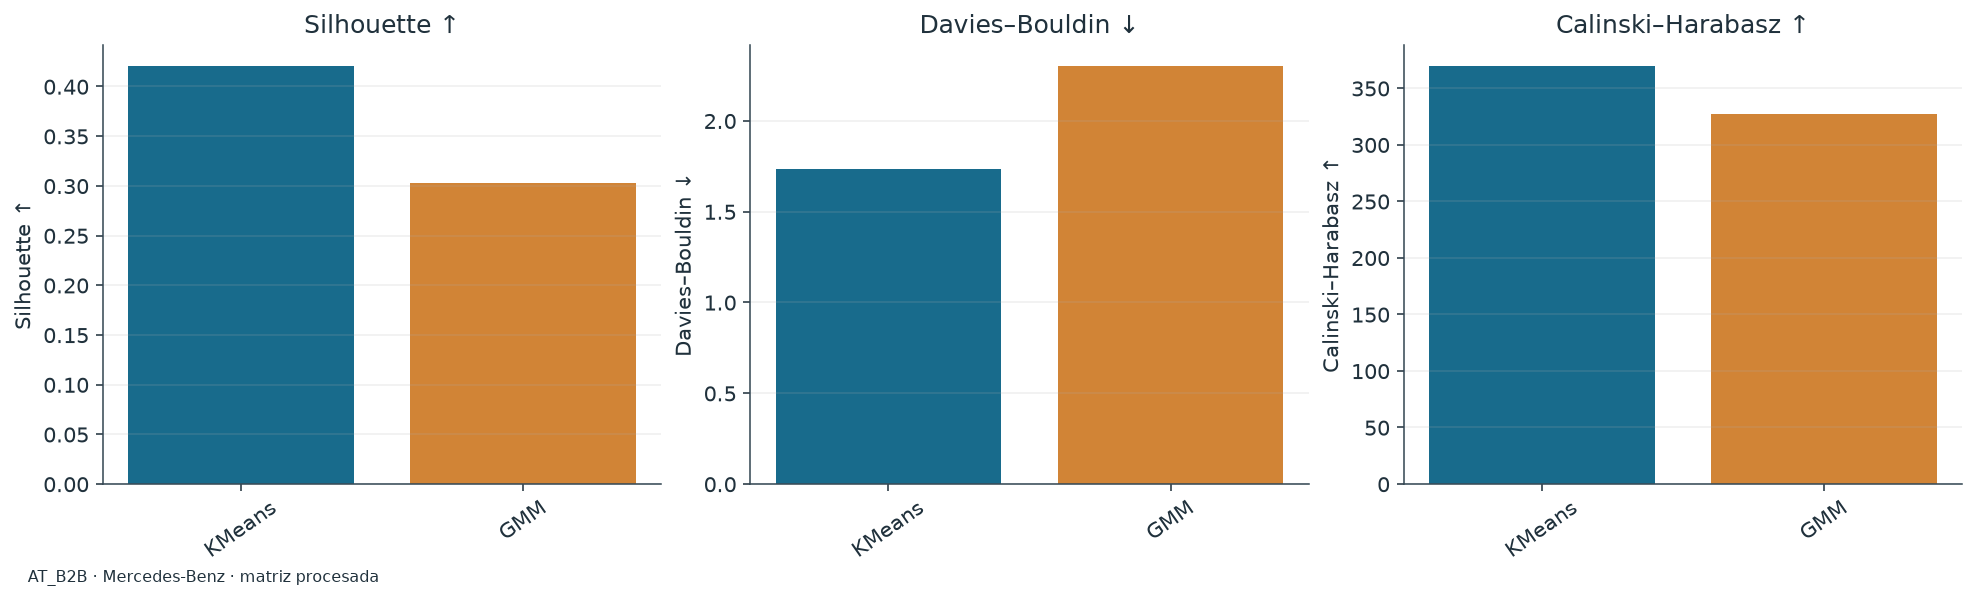

AT_B2C · comparación en la misma representación


,Algoritmo,n_clusters,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,WCSS en X original ↓,Convergencia
0,KMeans,6,0.1216,2.0397,9090.1902,1.132626e+06,True
1,GMM,6,0.0414,3.3640,4479.3618,1.333732e+06,True


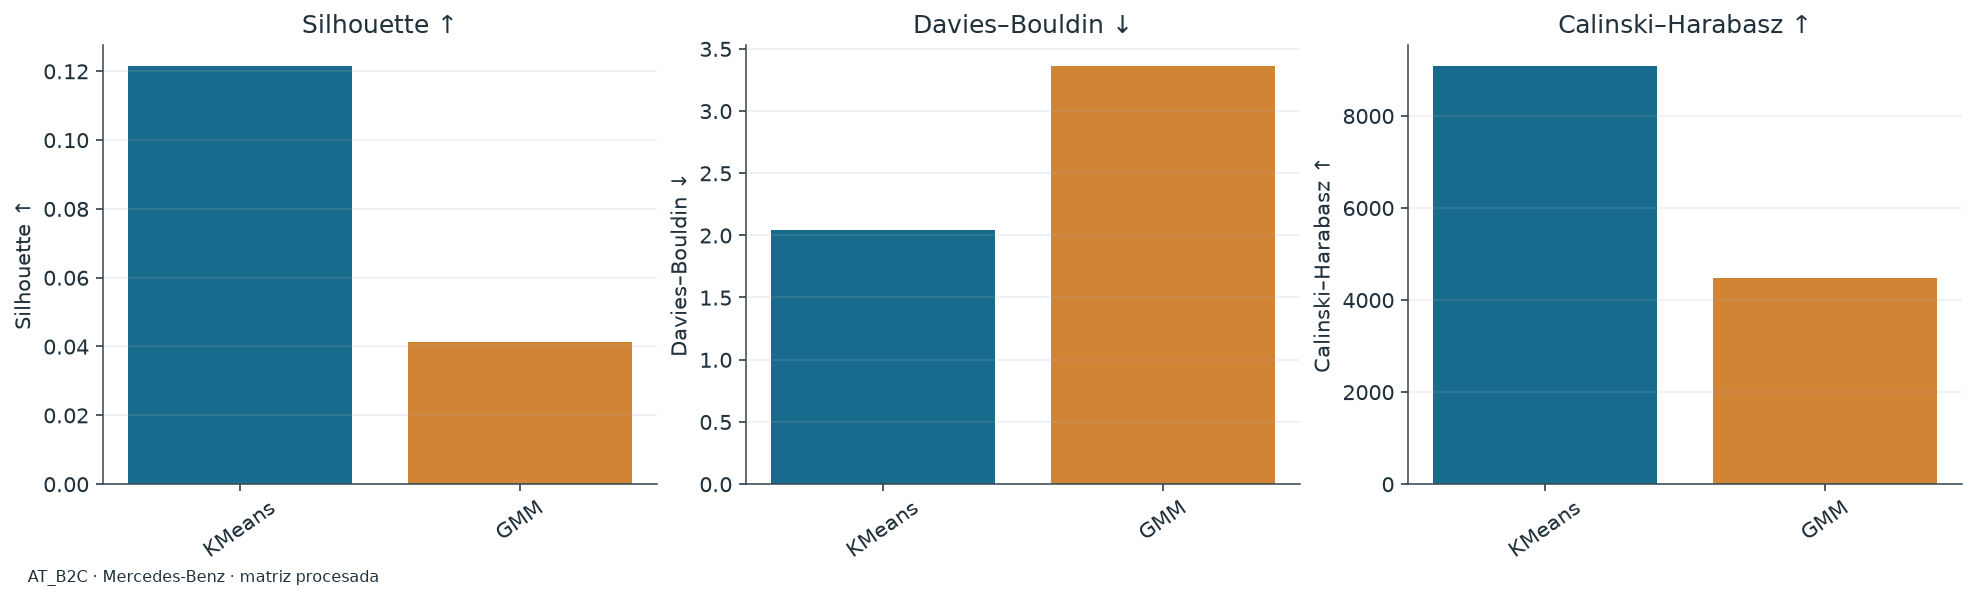

CH_B2B · comparación en la misma representación


,Algoritmo,n_clusters,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,WCSS en X original ↓,Convergencia
0,KMeans,2,0.5199,1.3472,485.9633,38708.4308,True
1,GMM,2,0.3850,2.1983,404.1809,39639.1870,True


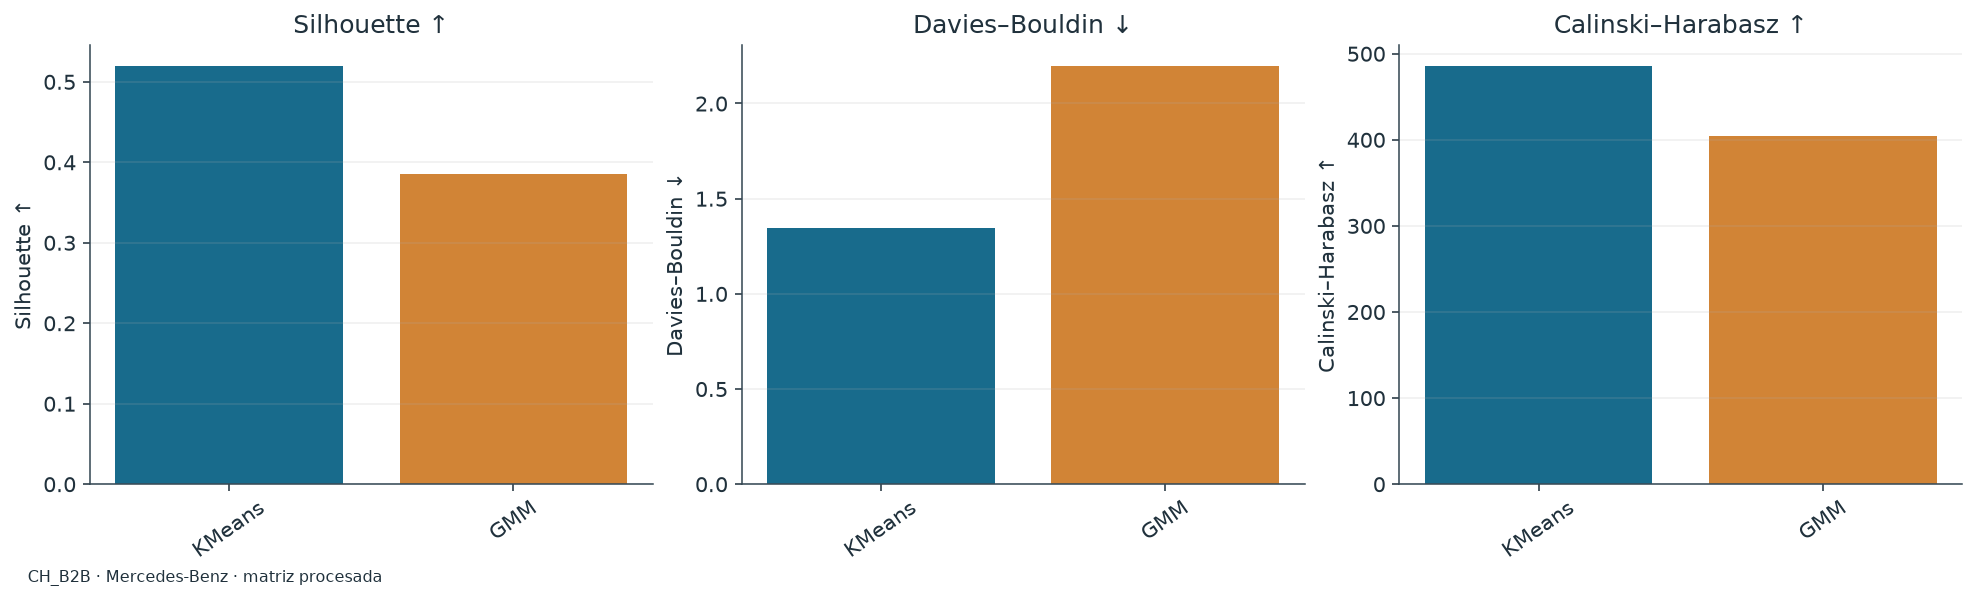

CH_B2C · comparación en la misma representación


,Algoritmo,n_clusters,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,WCSS en X original ↓,Convergencia
0,KMeans,5,0.1140,2.1976,16019.2263,2.129531e+06,True
1,GMM,5,0.0535,3.7183,8734.8753,2.405533e+06,True


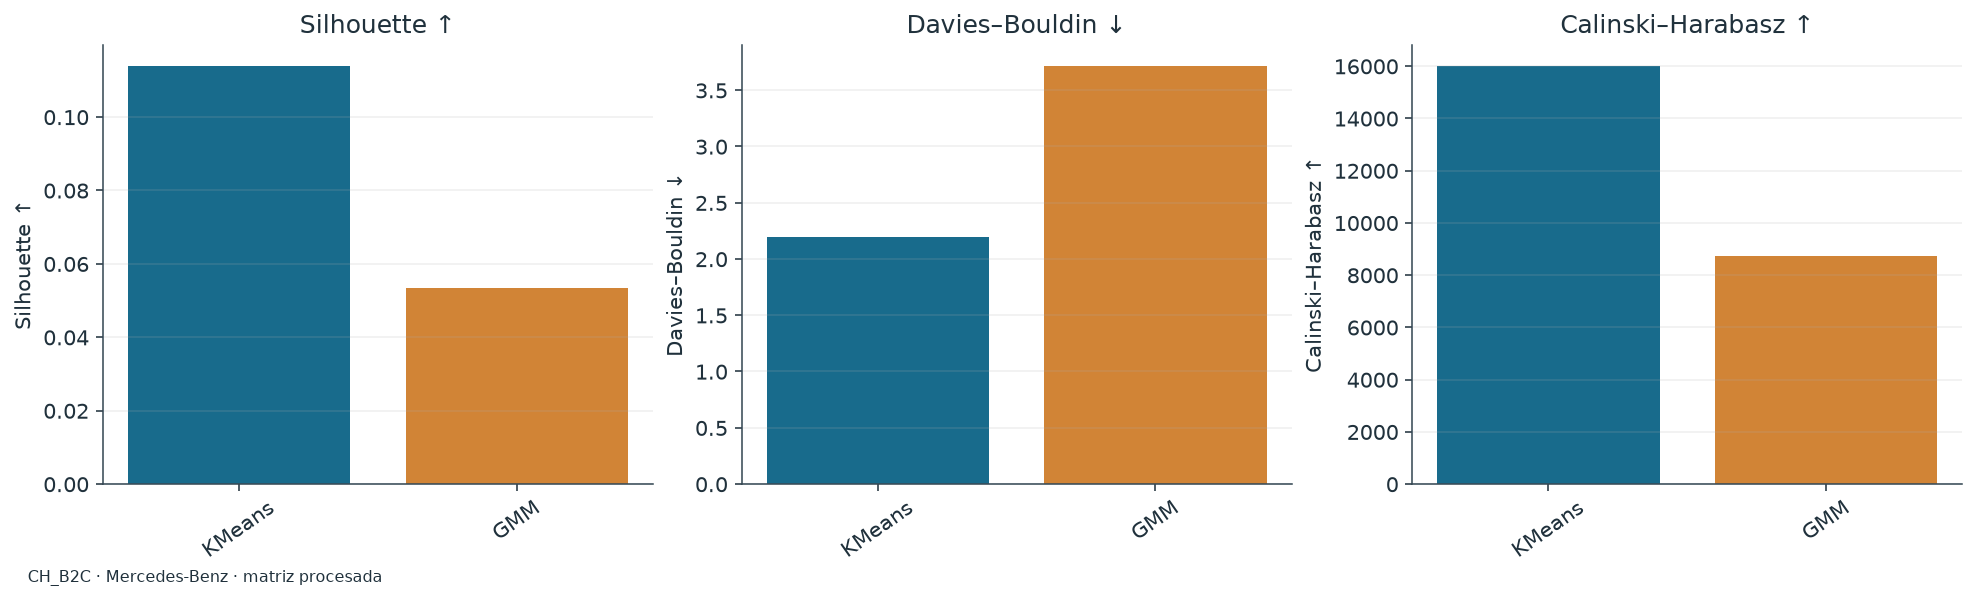

In [16]:
for segment, context in analyses.items():
    comparison = compare_algorithms(context["data"],context["model"].n_clusters,kmeans_model=context["model"],
        random_state=SEED,covariance_type=GMM_COVARIANCE_TYPE,silhouette_sample_size=SILHOUETTE_SAMPLE_SIZE)
    context["comparison"] = comparison
    display_table(comparison.table[["algorithm","n_clusters","silhouette","davies_bouldin","calinski_harabasz","within_ss","converged"]],
        segment+" · comparación en la misma representación")
    plot_comparison(comparison.table)
    show_figures(segment)


## Acuerdo de particiones y listas de campaña

ARI y NMI no requieren alinear etiquetas. Para medir qué clientes conservaría una audiencia, se alinea GMM a K-Means con asignación húngara. Jaccard compara listas; retención mide clientes originales que continúan. La referencia no es verdad terreno y la alineación optimiza la coincidencia.


In [17]:
for segment, context in analyses.items():
    comparison = context["comparison"]
    aligned,mapping = align_labels(context["labels"],comparison.labels["GMM"])
    overlap = audience_overlap(context["labels"],aligned)
    context.update(aligned_gmm=aligned,gmm_mapping=mapping,overlap=overlap)
    display_table(pd.DataFrame([dict(ARI=comparison.ari.loc["KMeans","GMM"],NMI=comparison.nmi.loc["KMeans","GMM"],
        aligned_disagreement=float((aligned!=context["labels"]).mean()))]),segment+" · dependencia del algoritmo")
    display_table(overlap,segment+" · continuidad de las audiencias")
    keep_table(segment,"continuidad de audiencias",overlap)


AT_B2B · dependencia del algoritmo


,ARI,NMI,aligned_disagreement
0,0.5315,0.4464,0.0944


AT_B2B · continuidad de las audiencias


,Cluster,reference_clients,alternative_clients,common_clients,audience_jaccard,retained_fraction,alternative_overlap
0,0,2297,2059,2059,0.8964,0.8964,1.000
1,1,225,463,225,0.4860,1.0000,0.486


AT_B2C · dependencia del algoritmo


...

,Cluster,reference_clients,alternative_clients,common_clients,audience_jaccard,retained_fraction,alternative_overlap
0,0,2864,2602,2602,0.9085,0.9085,1.0000
1,1,135,397,135,0.3401,1.0000,0.3401


CH_B2C · dependencia del algoritmo


,ARI,NMI,aligned_disagreement
0,0.2463,0.3034,0.5004


CH_B2C · continuidad de las audiencias


,Cluster,reference_clients,alternative_clients,common_clients,audience_jaccard,retained_fraction,alternative_overlap
0,0,27389,10646,5993,0.1870,0.2188,0.5629
1,1,66897,50414,29107,0.3300,0.4351,0.5774
2,2,53360,46156,34948,0.5413,0.6549,0.7572
3,3,33651,55943,20492,0.2965,0.6090,0.3663
4,4,8582,26720,4319,0.1394,0.5033,0.1616


## Pertenencias compartidas y baja densidad

Los componentes con p≥0.20 son candidatos simultáneos, sin que los clusters duros se solapen. La tabla de pares usa identificadores locales de componentes GMM; no son los IDs de 03. La tabla anterior de audiencias sí utiliza la correspondencia alineada. p máxima<0.70 o diferencia entre las dos mayores≤0.20 activa una alerta. Son posteriores condicionados al GMM, no probabilidades calibradas de respuesta a campaña. Una densidad baja y un posterior concentrado pueden coexistir.


AT_B2B · masa posterior compartida


,cluster_a,cluster_b,mean_shared_posterior,n_joint_candidates,membership_threshold
0,0,1,0.0,0,0.2


AT_B2B · ejemplos con mayor ambigüedad


,Cliente,aligned_cluster,Posterior máximo,Entropía normalizada,Componentes candidatos,low_density
1717,204223,0,1.0,0.0,1,False
578,68480,0,1.0,0.0,1,False
212,31039,0,1.0,0.0,1,False
579,68646,0,1.0,0.0,1,False
1150,136565,0,1.0,0.0,1,False


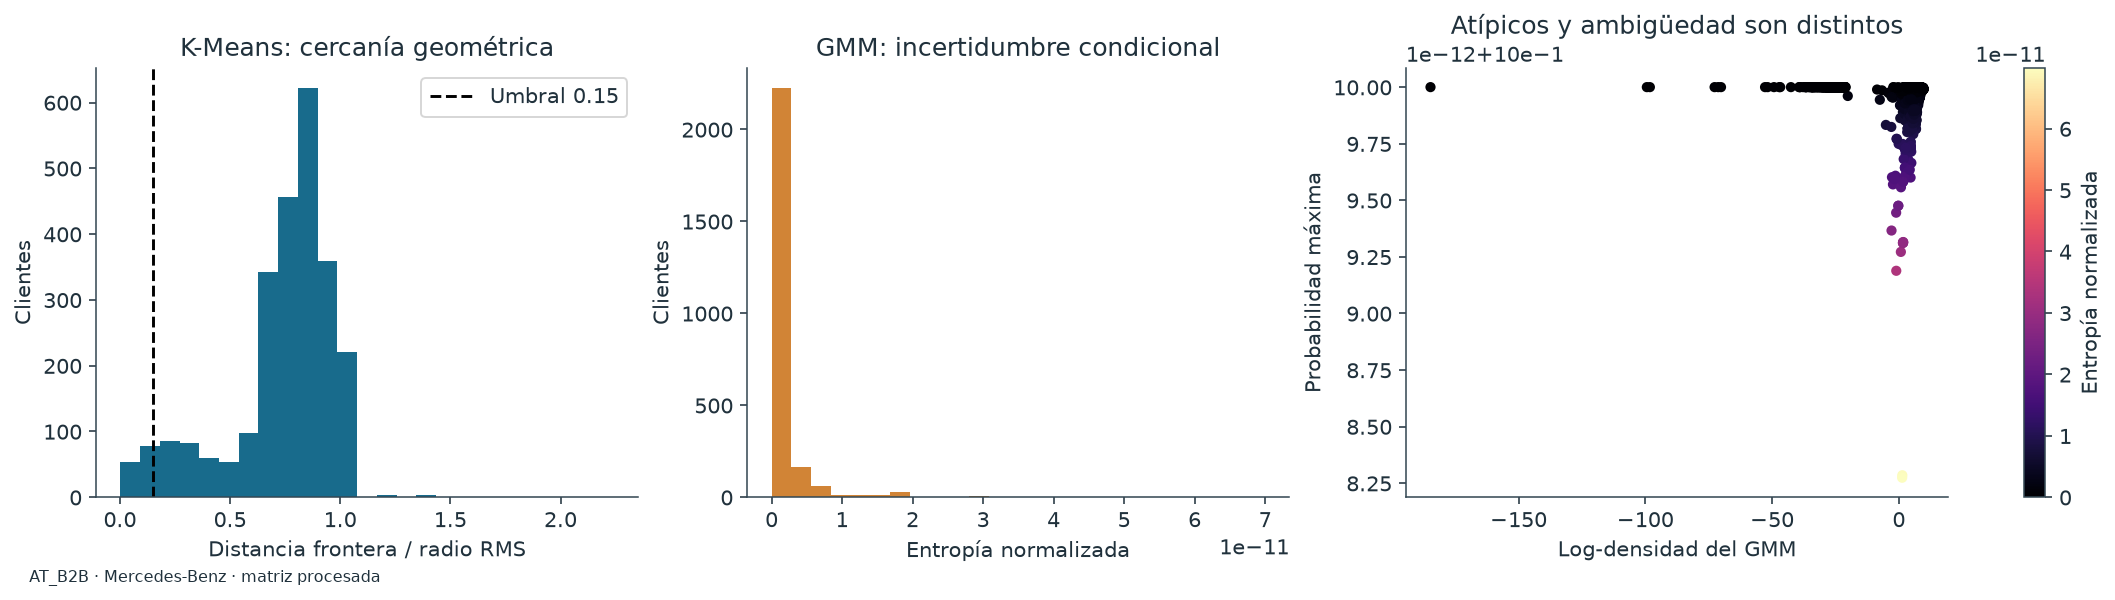

AT_B2C · masa posterior compartida


,cluster_a,cluster_b,mean_shared_posterior,n_joint_candidates,membership_threshold
10,2,4,0.0126,2560,0.2
6,1,3,0.0105,1589,0.2
9,2,3,0.0009,163,0.2
3,0,4,0.0009,185,0.2
5,1,2,0.0009,144,0.2
12,3,4,0.0008,118,0.2
0,0,1,0.0007,158,0.2
1,0,2,0.0007,127,0.2
14,4,5,0.0001,25,0.2
11,2,5,0.0001,19,0.2


AT_B2C · ejemplos con mayor ambigüedad


,Cliente,aligned_cluster,Posterior máximo,Entropía normalizada,Componentes candidatos,low_density
14888,42403,4,0.3498,0.6125,3,True
66475,187571,0,0.3723,0.6112,3,False
89667,253447,5,0.3724,0.6081,3,True
33109,93581,3,0.3845,0.6060,3,False
42264,119590,0,0.3913,0.6053,3,False


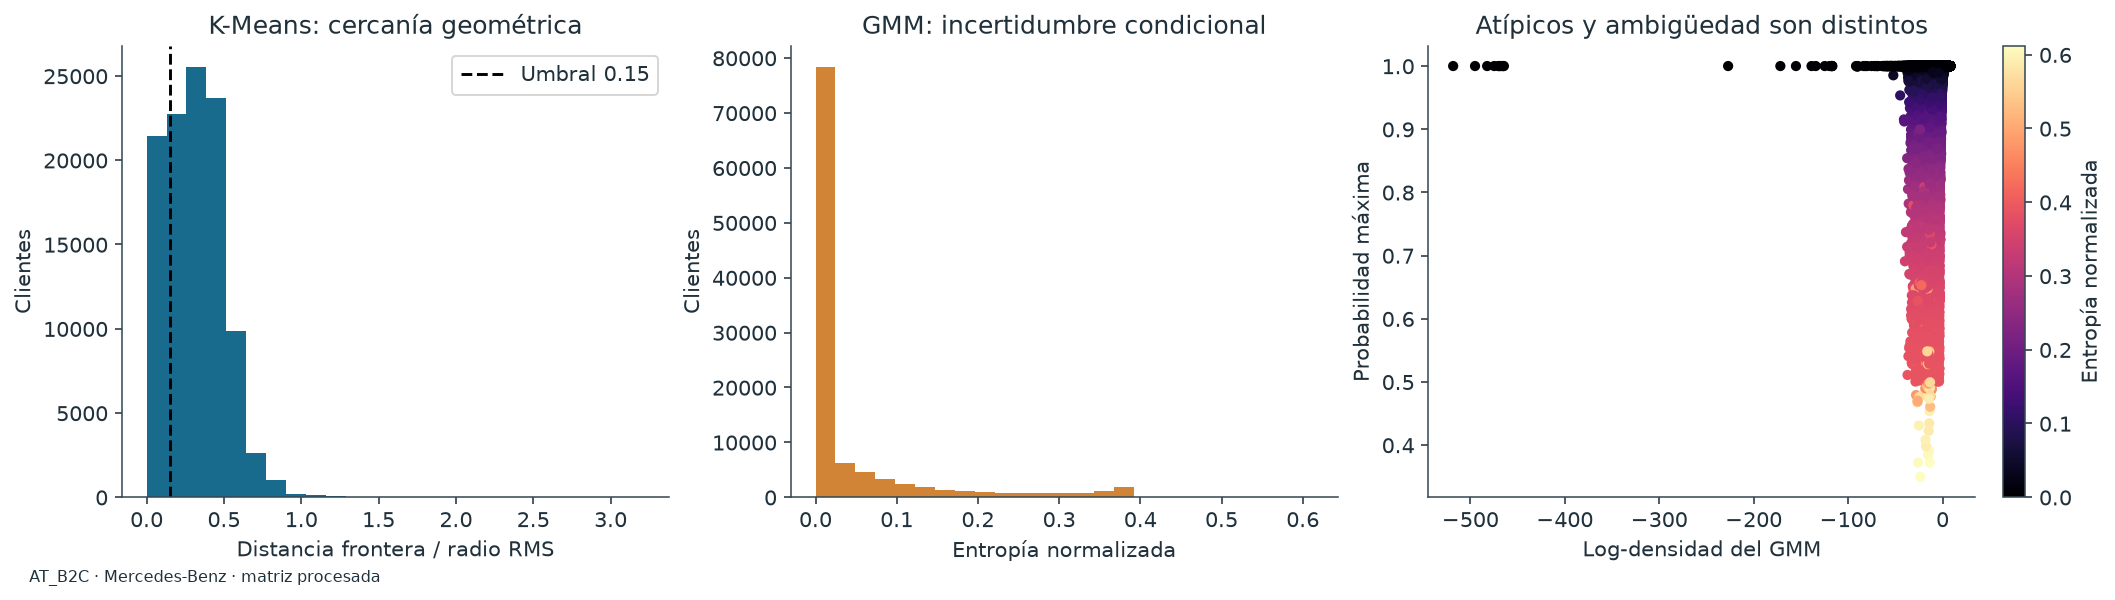

CH_B2B · masa posterior compartida


,cluster_a,cluster_b,mean_shared_posterior,n_joint_candidates,membership_threshold
0,0,1,0.0,0,0.2


CH_B2B · ejemplos con mayor ambigüedad


,Cliente,aligned_cluster,Posterior máximo,Entropía normalizada,Componentes candidatos,low_density
269,25271,0,1.0,0.0002,1,False
268,25270,0,1.0,0.0002,1,False
267,25269,0,1.0,0.0002,1,False
143,15012,0,1.0,0.0001,1,False
1542,150642,0,1.0,0.0001,1,False


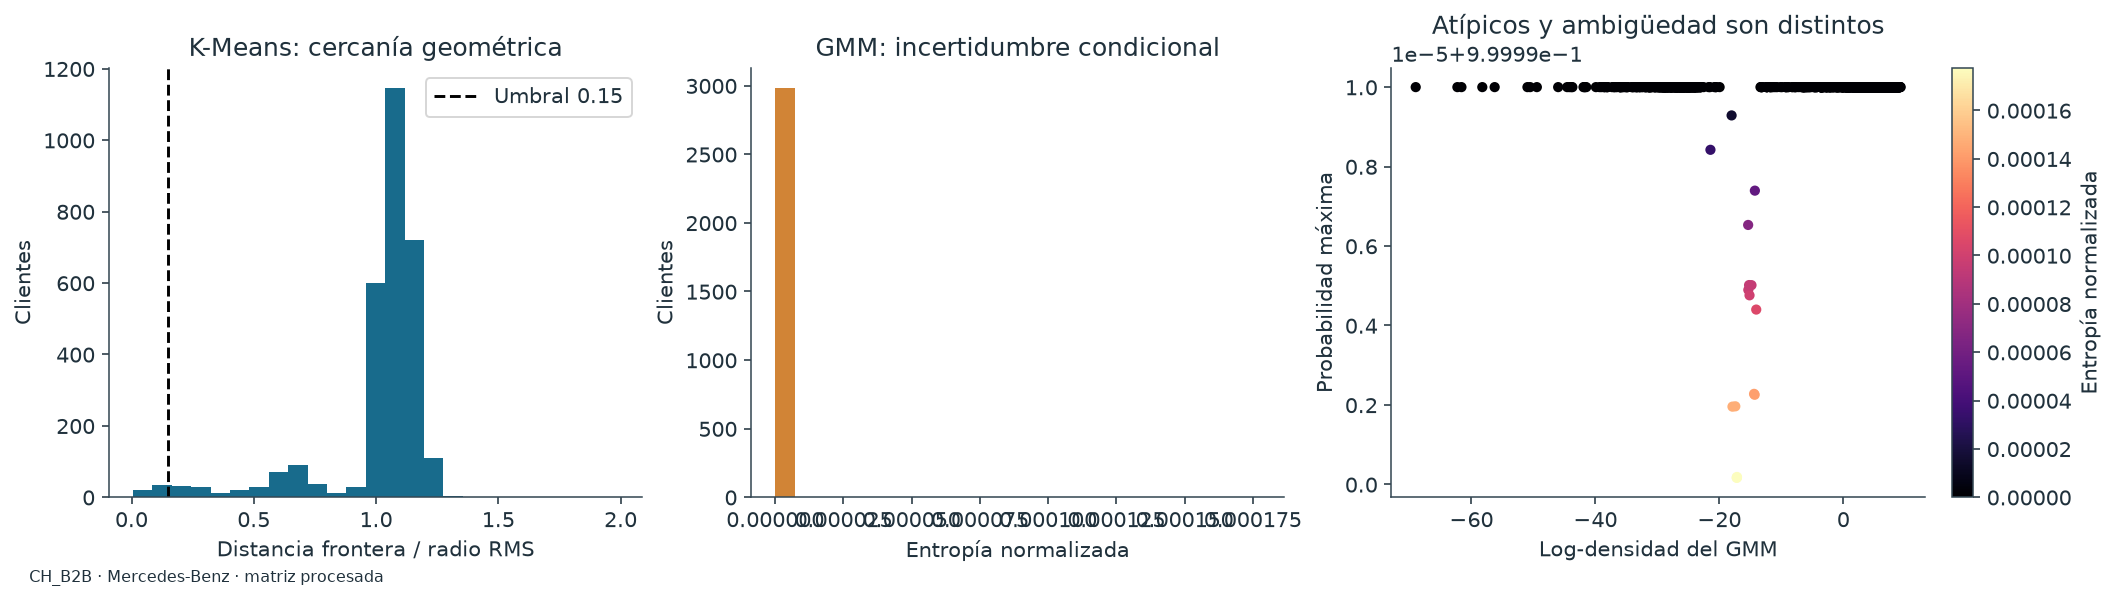

CH_B2C · masa posterior compartida


,cluster_a,cluster_b,mean_shared_posterior,n_joint_candidates,membership_threshold
1,0,2,0.0026,840,0.2
8,2,4,0.0006,215,0.2
2,0,3,0.0005,158,0.2
4,1,2,0.0003,125,0.2
3,0,4,0.0003,103,0.2
0,0,1,0.0003,105,0.2
7,2,3,0.0002,61,0.2
5,1,3,0.0001,39,0.2
9,3,4,0.0001,20,0.2
6,1,4,0.0000,0,0.2


CH_B2C · ejemplos con mayor ambigüedad


,Cliente,aligned_cluster,Posterior máximo,Entropía normalizada,Componentes candidatos,low_density
159230,253699,2,0.4216,0.6686,3,False
73856,117422,3,0.4110,0.6655,3,False
143628,228959,1,0.4502,0.6627,3,False
118294,188569,3,0.4640,0.6547,3,False
8285,12952,2,0.4198,0.6441,2,False


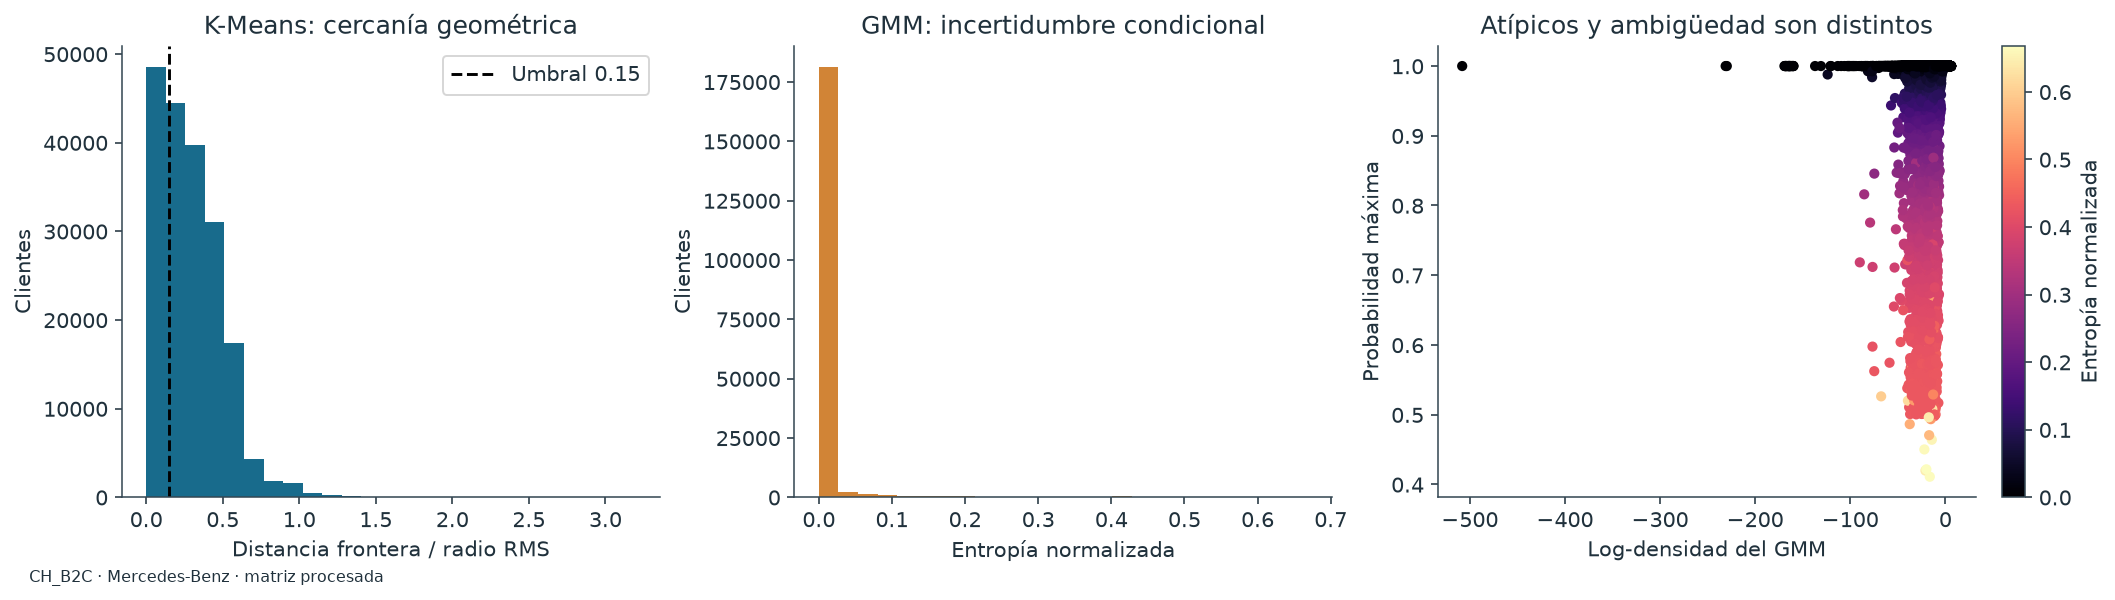

In [18]:
for segment, context in analyses.items():
    memberships = gmm_memberships(context["data"],context["comparison"].models["GMM"],confidence_threshold=.7,
        gap_threshold=.2,membership_threshold=.2,low_density_quantile=.05)
    memberships["aligned_cluster"] = context["aligned_gmm"]
    memberships["model_disagreement"] = context["aligned_gmm"] != context["labels"]
    context["memberships"] = memberships
    pairs = membership_overlap(memberships,threshold=.2)
    display_table(pairs.sort_values("mean_shared_posterior",ascending=False),segment+" · masa posterior compartida")
    display_table(memberships.sort_values("normalized_entropy",ascending=False)[
        ["client_id","aligned_cluster","max_probability","normalized_entropy","n_candidate_clusters","low_density"]],
        segment+" · ejemplos con mayor ambigüedad",max_rows=5)
    plot_ambiguity(context["clients"],memberships)
    show_figures(segment)


## Barrido GMM separado de la comparación obligatoria

Sobre una muestra común de hasta 20.000 filas se prueban diagonal/esférica y regularización. EXTENDED_SWEEP amplía k y covarianzas, con coste O(k·p²) para completas. BIC/AIC se minimizan sobre esta misma muestra; no alteran el k de la comparación principal ni se comparan con otra matriz. Fallos y falta de convergencia permanecen visibles.


In [19]:
for segment, context in analyses.items():
    data = context["data"]
    positions = evaluation_indices(data.n_samples,HYPERPARAMETER_MAX_SAMPLES,SEED)
    frame = pd.DataFrame(data.X[positions],columns=data.feature_names)
    frame.insert(0,"client_id",data.client_ids.iloc[positions].to_numpy())
    covariance = ("diag","spherical","full","tied") if EXTENDED_SWEEP else ("diag","spherical")
    candidates = range(2,9) if EXTENDED_SWEEP else [context["model"].n_clusters]
    context["sweep_data"] = load_features(frame)
    grid = sweep_baselines(context["sweep_data"],candidates,seeds=(SEED,SEED+1),kmeans_n_init=(),
        covariance_types=covariance,reg_covars=(1e-5,1e-3))
    display_table(grid[["k","covariance_type","reg_covar","seed","bic","aic","silhouette","converged","status"]],
        f"{segment} · {len(positions):,} filas del estudio GMM")
    keep_table(segment,"barrido GMM",grid)


AT_B2B · 2,522 filas del estudio GMM


,k,covariance_type,reg_covar,seed,BIC ↓,AIC ↓,Silhouette ↑,Convergencia,Estado
0,2,diag,0.000,42,20117.5981,19761.7969,0.3404,True,ok
1,2,diag,0.000,43,1334.2509,978.4497,0.3027,True,ok
2,2,diag,0.001,42,49959.2260,49603.4247,0.3404,True,ok
3,2,diag,0.001,43,39262.5672,38906.7660,0.3027,True,ok
4,2,spherical,0.000,42,97982.2501,97789.7675,0.3735,True,ok
5,2,spherical,0.000,43,97982.2949,97789.8122,0.3698,True,ok
6,2,spherical,0.001,42,97982.5099,97790.0273,0.3735,True,ok
7,2,spherical,0.001,43,97982.2205,97789.7379,0.3698,True,ok


AT_B2C · 20,000 filas del estudio GMM


,k,covariance_type,reg_covar,seed,BIC ↓,AIC ↓,Silhouette ↑,Convergencia,Estado
0,6,diag,0.000,42,213553.8583,212091.7131,0.0382,True,ok
1,6,diag,0.000,43,342377.3502,340915.2050,0.0821,True,ok
2,6,diag,0.001,42,413246.9814,411784.8362,0.0482,True,ok
3,6,diag,0.001,43,426021.3434,424559.1982,0.0578,True,ok
4,6,spherical,0.000,42,770204.6205,769406.3682,0.0919,True,ok
5,6,spherical,0.000,43,770365.3257,769567.0734,0.0985,True,ok
6,6,spherical,0.001,42,770213.7748,769415.5225,0.0920,True,ok
7,6,spherical,0.001,43,770367.5139,769569.2616,0.0992,True,ok


CH_B2B · 2,999 filas del estudio GMM


,k,covariance_type,reg_covar,seed,BIC ↓,AIC ↓,Silhouette ↑,Convergencia,Estado
0,2,diag,0.000,42,-1635.3084,-2001.6765,0.3850,True,ok
1,2,diag,0.000,43,-1635.3084,-2001.6765,0.3850,True,ok
2,2,diag,0.001,42,46246.2372,45879.8691,0.3807,True,ok
3,2,diag,0.001,43,46246.2372,45879.8691,0.3807,True,ok
4,2,spherical,0.000,42,114176.0777,113977.8785,0.3523,True,ok
5,2,spherical,0.000,43,114176.0777,113977.8785,0.3523,True,ok
6,2,spherical,0.001,42,114176.3514,113978.1523,0.3534,True,ok
7,2,spherical,0.001,43,114176.3514,113978.1523,0.3534,True,ok


CH_B2C · 20,000 filas del estudio GMM


,k,covariance_type,reg_covar,seed,BIC ↓,AIC ↓,Silhouette ↑,Convergencia,Estado
0,5,diag,0.000,42,335342.5860,334125.4489,0.0435,True,ok
1,5,diag,0.000,43,335342.8415,334125.7045,0.0436,True,ok
2,5,diag,0.001,42,472212.1310,470994.9940,0.0415,True,ok
3,5,diag,0.001,43,501693.8337,500476.6967,0.0418,True,ok
4,5,spherical,0.000,42,784625.0887,783961.1957,0.1024,True,ok
5,5,spherical,0.000,43,783701.9731,783038.0802,0.0511,True,ok
6,5,spherical,0.001,42,784619.8804,783955.9874,0.1025,True,ok
7,5,spherical,0.001,43,783724.2620,783060.3690,0.0521,True,ok


## Agglomerative: comparación secundaria en muestra común

El clustering jerárquico fusiona grupos según Ward (incremento de WCSS), average o complete (distancia media o máxima). Para acotar su coste cuadrático se usa una muestra uniforme de hasta 3.000 filas, semilla 42. Todos los algoritmos de esta tabla se ajustan desde cero sobre exactamente esa submatriz y el k de 03: es un experimento distinto de la comparación principal, cuyo baseline no se sustituye. No se extrapolan etiquetas jerárquicas a clientes fuera de la muestra.


AT_B2B · comparación en submatriz común


,Algoritmo,Clientes de ajuste,n_clusters,Grupo menor (clientes),Grupo mínimo,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,WCSS en X original ↓
0,KMeans,2522,2,225,0.0892,0.4210,1.7345,369.9884,32986.8457
1,GMM,2522,2,463,0.1836,0.3027,2.3039,327.3069,33481.3227
2,Agg ward,2522,2,861,0.3414,0.1839,2.5978,298.0041,33829.4752
3,Agg average,2522,2,1,0.0004,0.8778,0.0854,111.2678,36230.2923
4,Agg complete,2522,2,3,0.0012,0.8163,0.6824,115.9674,36165.6981


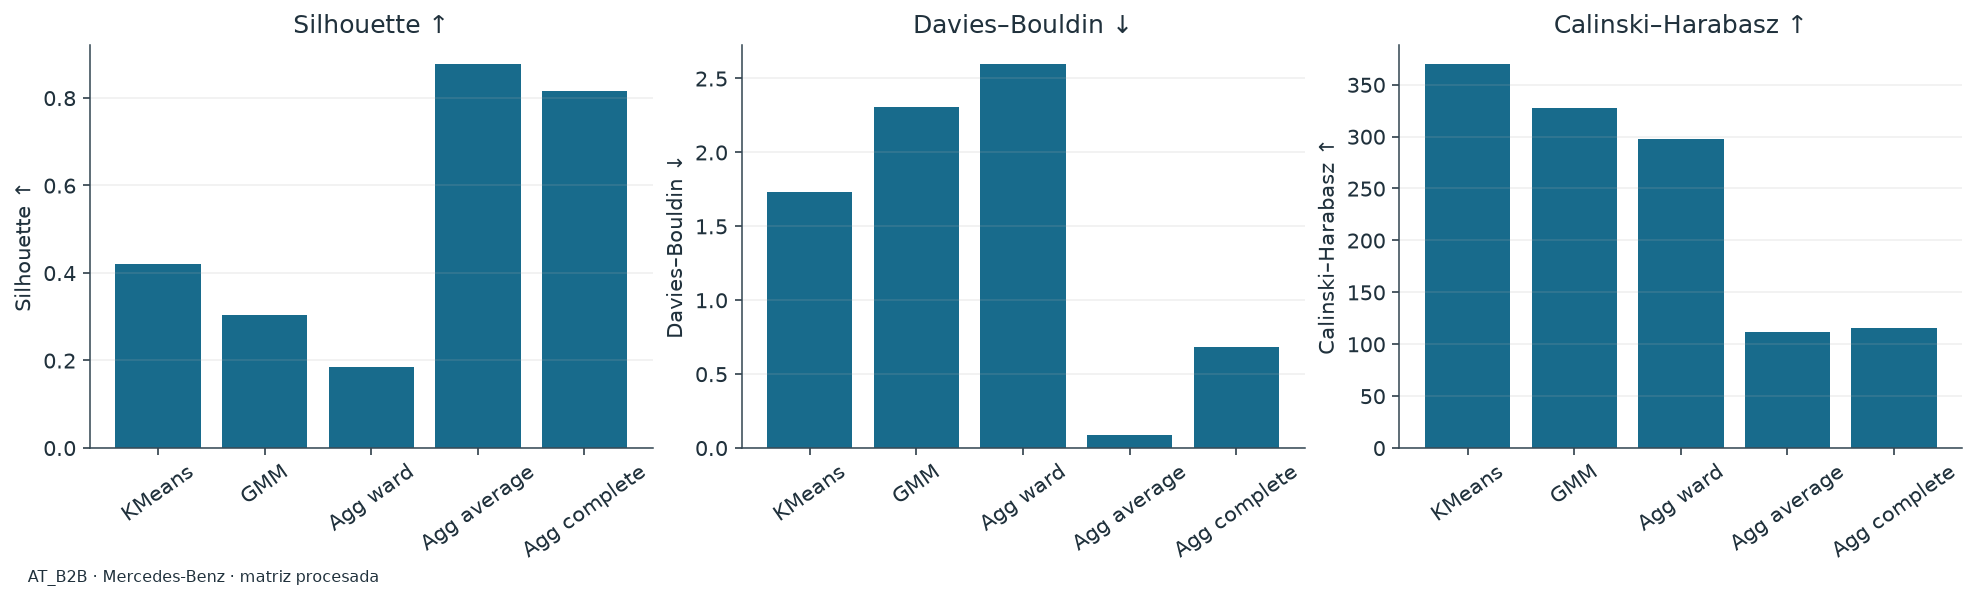

AT_B2C · comparación en submatriz común


,Algoritmo,Clientes de ajuste,n_clusters,Grupo menor (clientes),Grupo mínimo,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,WCSS en X original ↓
0,KMeans,3000,6,226,0.0753,0.1130,2.0196,259.6236,30206.2145
1,GMM,3000,6,68,0.0227,0.0367,2.9549,116.9754,36226.0701
2,Agg ward,3000,6,212,0.0707,0.0905,2.3528,205.8141,32226.2916
3,Agg average,3000,6,1,0.0003,0.4311,0.8596,63.3096,39162.2926
4,Agg complete,3000,6,2,0.0007,0.4308,0.9812,67.8028,38898.3192


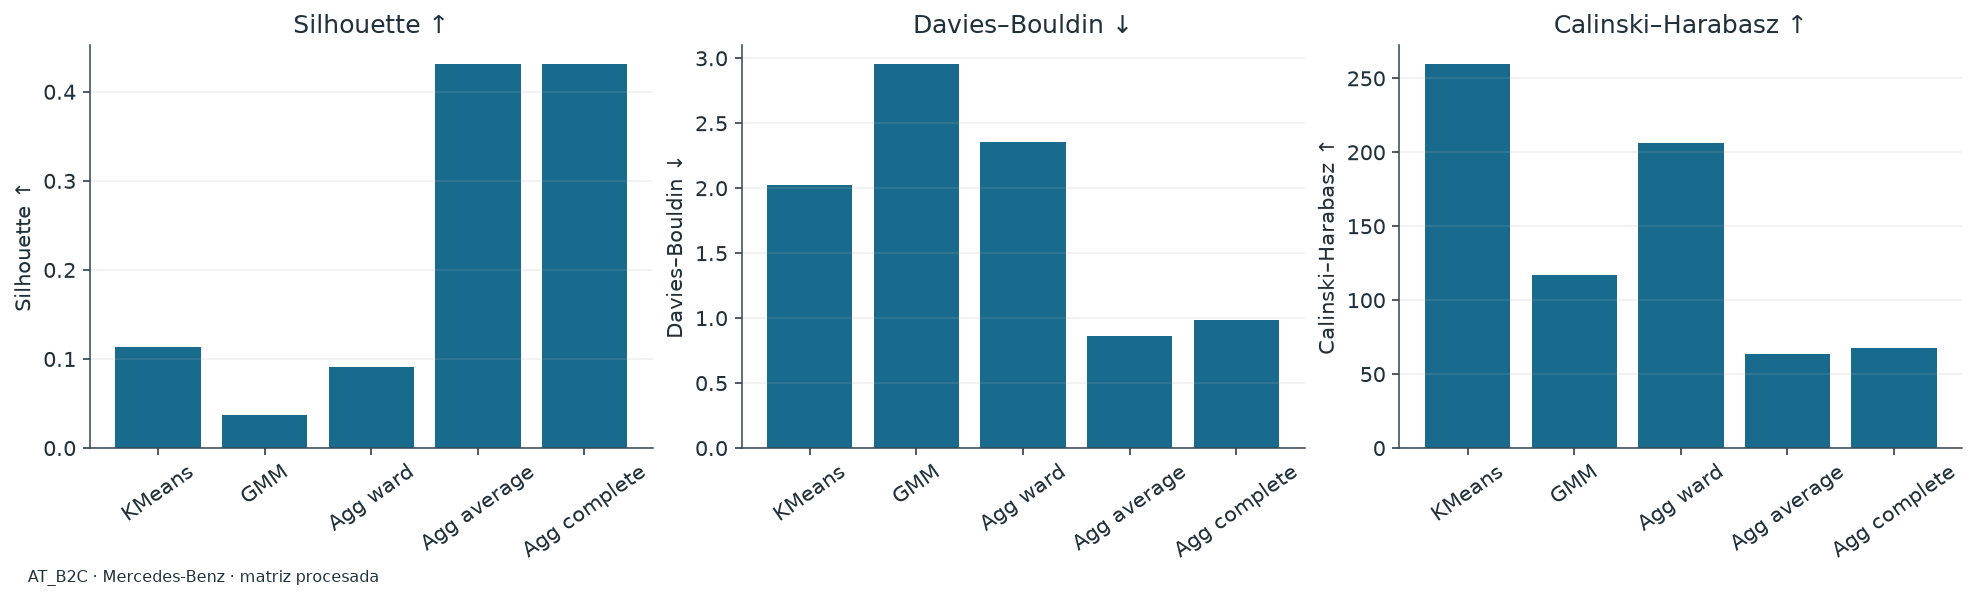

CH_B2B · comparación en submatriz común


,Algoritmo,Clientes de ajuste,n_clusters,Grupo menor (clientes),Grupo mínimo,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,WCSS en X original ↓
0,KMeans,2999,2,135,0.0450,0.5199,1.3472,485.9633,38708.4308
1,GMM,2999,2,397,0.1324,0.3850,2.1983,404.1809,39639.1870
2,Agg ward,2999,2,77,0.0257,0.5555,1.0916,419.4696,39461.8012
3,Agg average,2999,2,1,0.0003,0.7384,0.1827,23.3801,44636.7810
4,Agg complete,2999,2,4,0.0013,0.7136,0.5646,69.1226,43970.8589


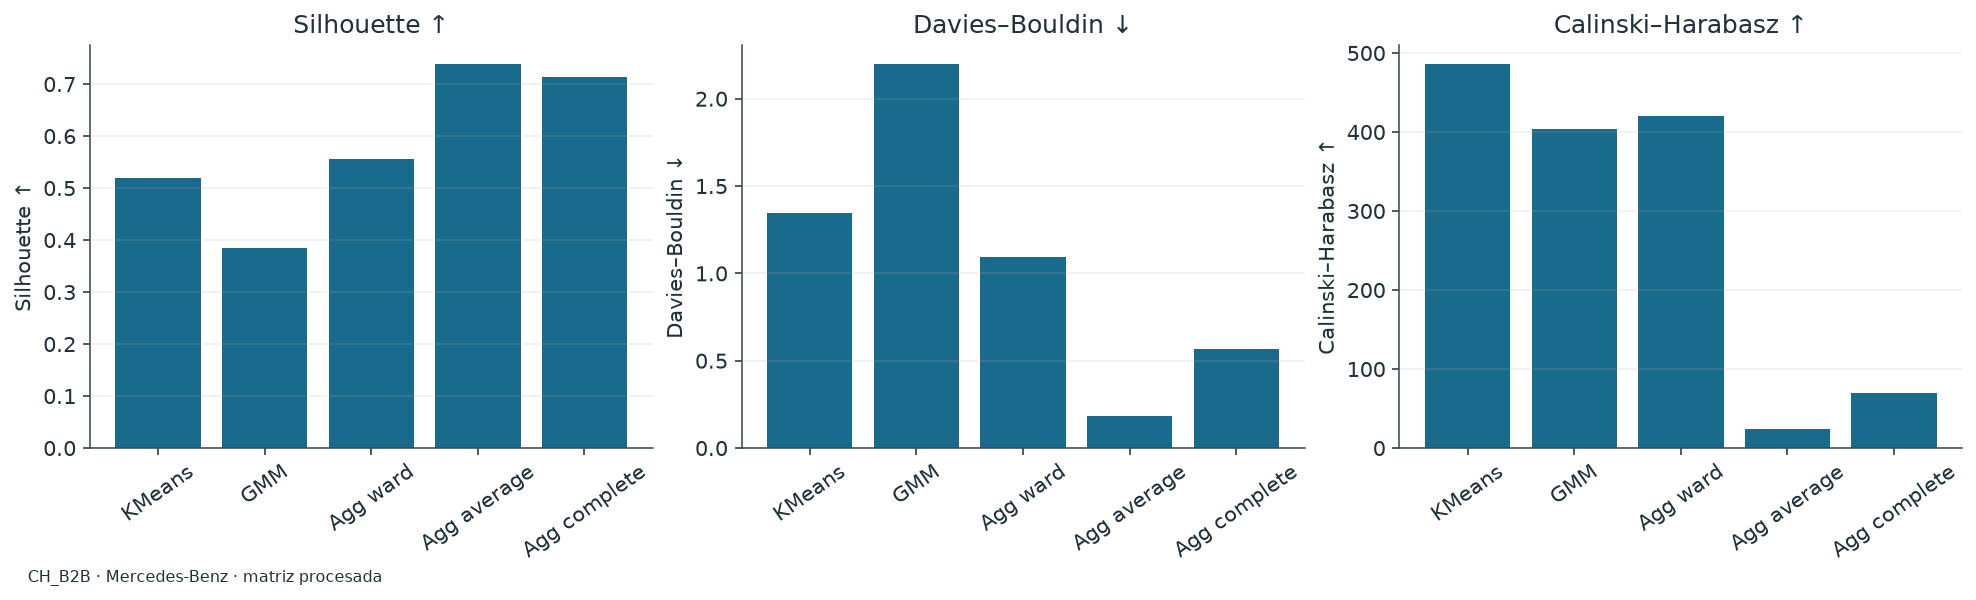

CH_B2C · comparación en submatriz común


,Algoritmo,Clientes de ajuste,n_clusters,Grupo menor (clientes),Grupo mínimo,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,WCSS en X original ↓
0,KMeans,3000,5,134,0.0447,0.1074,2.1618,263.4248,33225.2603
1,GMM,3000,5,107,0.0357,0.0457,3.0617,148.5757,37477.7786
2,Agg ward,3000,5,123,0.0410,0.1055,2.1894,207.0318,35185.6174
3,Agg average,3000,5,1,0.0003,0.5782,0.5978,50.9053,42055.3356
4,Agg complete,3000,5,1,0.0003,0.1497,1.8234,79.1388,40621.1219


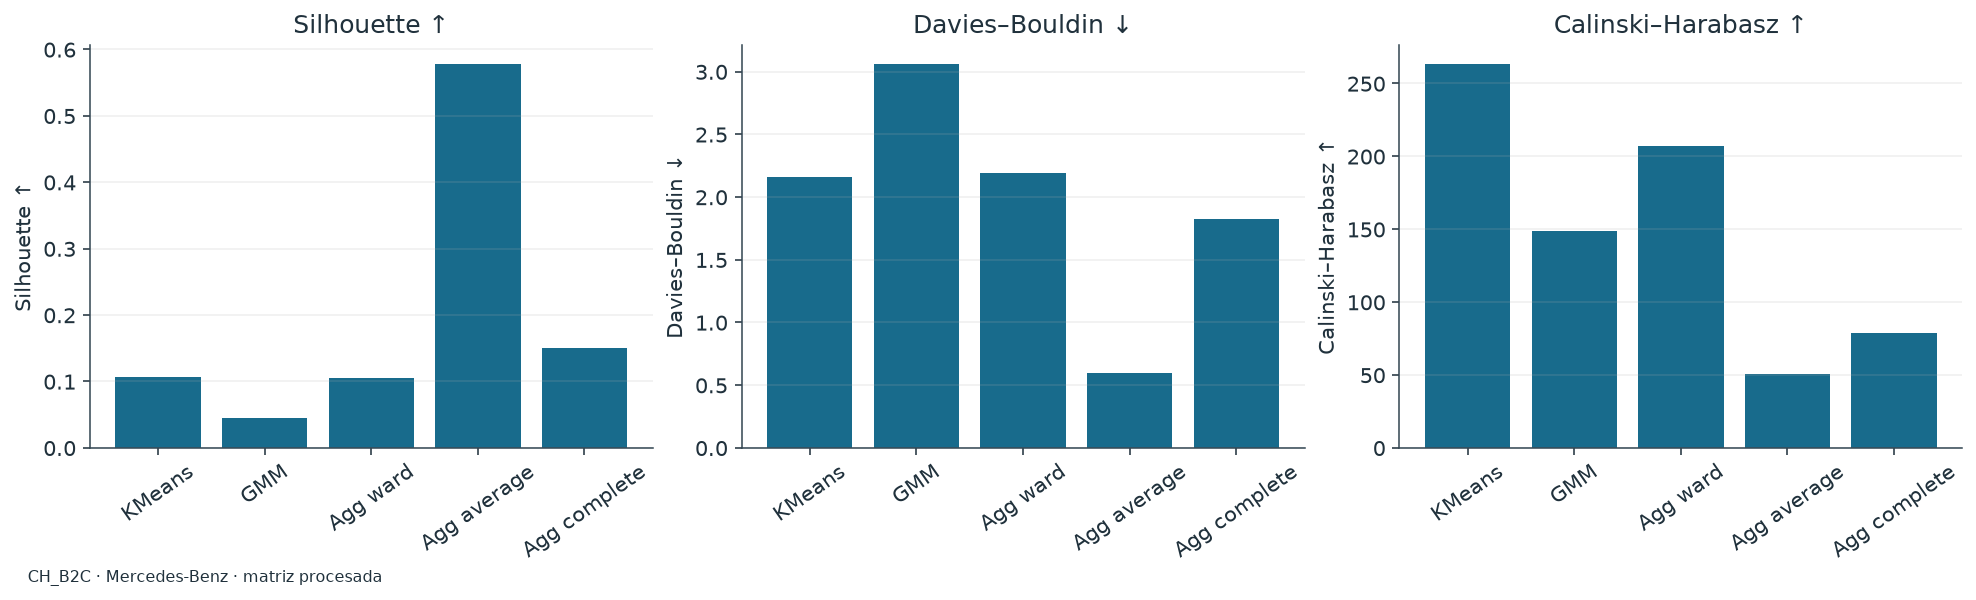

In [20]:
for segment, context in analyses.items():
    subset, positions, hierarchy = hierarchical_benchmark(context["data"],context["model"].n_clusters,
        max_samples=HIERARCHICAL_MAX_SAMPLES,random_state=SEED,silhouette_sample_size=SILHOUETTE_SAMPLE_SIZE)
    context.update(hierarchy=hierarchy,hierarchy_data=subset,hierarchy_positions=positions)
    display_table(hierarchy.table[["algorithm","fit_clients","n_clusters","min_cluster_size","min_cluster_fraction",
        "silhouette","davies_bouldin","calinski_harabasz","within_ss"]],
        segment+" · comparación en submatriz común")
    plot_comparison(hierarchy.table)
    show_figures(segment)
    assignments = subset.assignments(hierarchy.labels["KMeans"])
    for name, labels in hierarchy.labels.items():
        assignments[name] = labels
    keep_table(segment,"asignaciones jerárquicas solo en muestra",assignments)


## Sensibilidad al enlace jerárquico

ARI compara todas las particiones de esta misma muestra sin alinear sus números de cluster. Un Silhouette muy alto puede coexistir con un grupo formado por muy pocos casos extremos: contrastar siempre tamaños y CH, y no proponer una campaña por ese score. La dependencia del enlace revela sensibilidad a la forma y a observaciones alejadas. Estos resultados son condicionales a la muestra; no miden estabilidad poblacional ni sustituyen el Jackknife de 07.


AT_B2B · ARI en muestra común


,KMeans,GMM,Agg ward,Agg average,Agg complete
KMeans,1.0000,0.5315,0.1889,0.0073,0.0217
GMM,0.5315,1.0000,0.4039,0.0027,0.0082
Agg ward,0.1889,0.4039,1.0000,0.0007,0.0022
Agg average,0.0073,0.0027,0.0007,1.0000,0.4993
Agg complete,0.0217,0.0082,0.0022,0.4993,1.0000


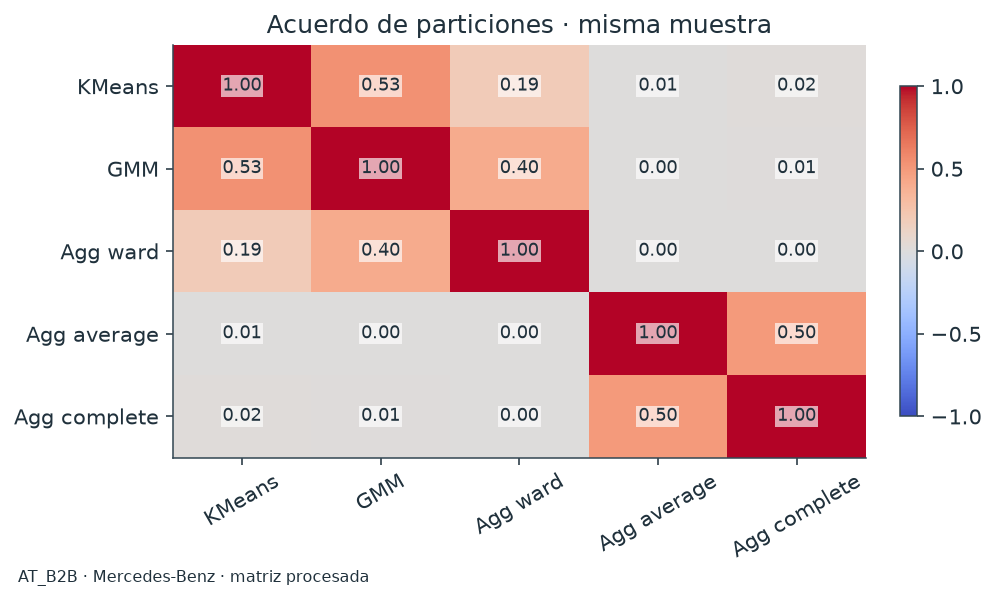

AT_B2C · ARI en muestra común


,KMeans,GMM,Agg ward,Agg average,Agg complete
KMeans,1.0000,0.2217,0.3933,0.0106,0.0118
GMM,0.2217,1.0000,0.1841,0.0178,0.0195
Agg ward,0.3933,0.1841,1.0000,0.0089,0.0093
Agg average,0.0106,0.0178,0.0089,1.0000,0.8195
Agg complete,0.0118,0.0195,0.0093,0.8195,1.0000


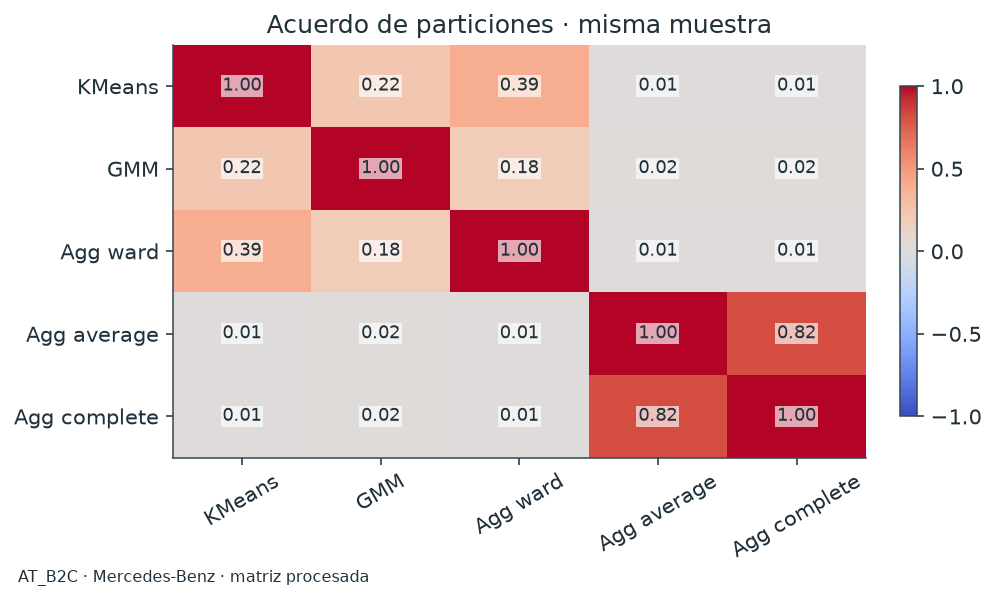

CH_B2B · ARI en muestra común


,KMeans,GMM,Agg ward,Agg average,Agg complete
KMeans,1.0000,0.4226,0.6822,0.0134,0.0113
GMM,0.4226,1.0000,0.2575,0.0037,0.0147
Agg ward,0.6822,0.2575,1.0000,0.0243,-0.0025
Agg average,0.0134,0.0037,0.0243,1.0000,-0.0005
Agg complete,0.0113,0.0147,-0.0025,-0.0005,1.0000


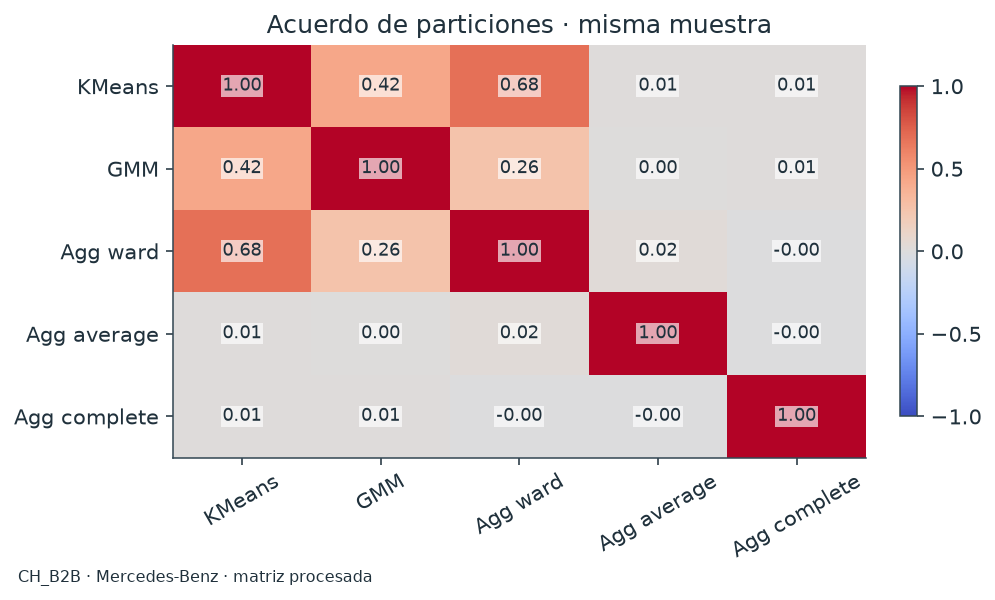

CH_B2C · ARI en muestra común


,KMeans,GMM,Agg ward,Agg average,Agg complete
KMeans,1.0000,0.1610,0.2839,0.0004,0.0395
GMM,0.1610,1.0000,0.3961,0.0060,0.0843
Agg ward,0.2839,0.3961,1.0000,-0.0024,0.0391
Agg average,0.0004,0.0060,-0.0024,1.0000,0.0488
Agg complete,0.0395,0.0843,0.0391,0.0488,1.0000


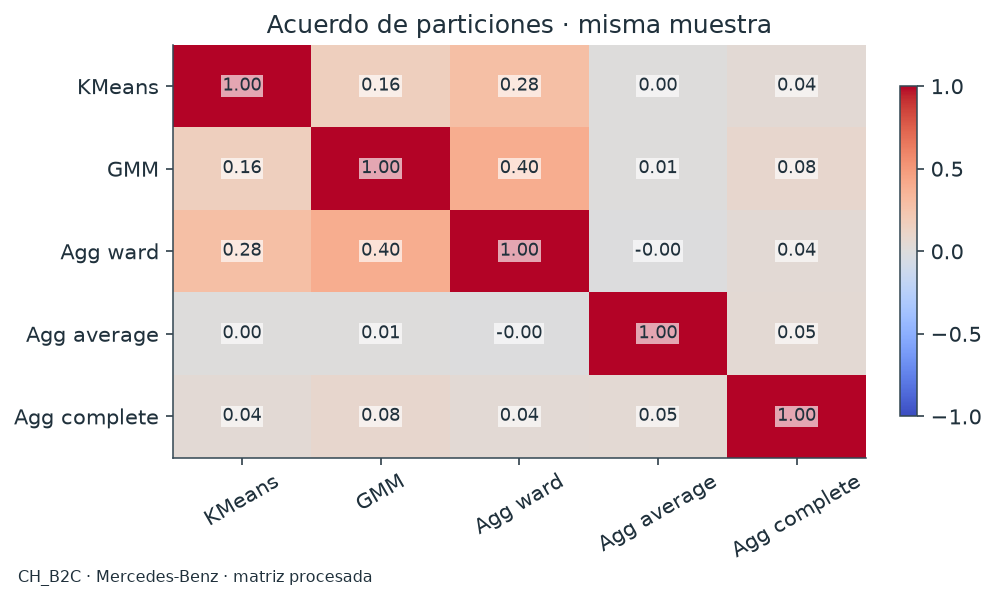

In [21]:
for segment, context in analyses.items():
    hierarchy = context["hierarchy"]
    display_table(hierarchy.ari,segment+" · ARI en muestra común")
    plot_heatmap(hierarchy.ari,"Acuerdo de particiones · misma muestra",vmin=-1,vmax=1,cmap="coolwarm")
    show_figures(segment)
    context["hierarchy_ward_ari"] = float(hierarchy.ari.loc["KMeans","Agg ward"])
    small = hierarchy.table.loc[hierarchy.table["min_cluster_fraction"]<.02]
    context["hierarchy_small_groups"] = "; ".join(
        f"{row.algorithm}: grupo menor {row.min_cluster_size} ({row.min_cluster_fraction:.2%})"
        for row in small.itertuples()) or "Ningún algoritmo produce grupos por debajo del 2 % en esta muestra."
    context["entry"]["hierarchical_benchmark"] = dict(n_samples=context["hierarchy_data"].n_samples,
        seed=SEED,k=context["model"].n_clusters,ward_ari=context["hierarchy_ward_ari"],
        population_predictions=False)


## DBSCAN: regiones densas y clientes sin asignación

DBSCAN no fija k: utiliza eps y min_samples para conectar regiones densas y marca ruido con −1. Se reutiliza exactamente la muestra común del benchmark anterior, ya transformada con los parámetros de 03. Se barren min_samples=10/30/60 y radios en cuantiles 0.50/0.75/0.90 de la distancia a su vecino correspondiente (incluido el propio punto). El muestreo cambia la densidad: estos radios no se trasladan automáticamente a toda la población. No se extrapolan sus etiquetas fuera de la muestra ni se exige que reproduzca el k de K-Means.


AT_B2B · barrido de densidad y cobertura


,min_samples,Cuantil del radio,eps,n_clusters,Cobertura,Fracción de ruido,Grupo menor (clientes),Clientes núcleo,Clientes de borde,Estado
0,10,0.50,1.0250,39,0.5821,0.4179,10,1261,207,ok
1,10,0.75,1.8375,8,0.7871,0.2129,13,1891,94,ok
2,10,0.90,3.1167,2,0.9441,0.0559,180,2269,112,ok
3,30,0.50,1.5589,10,0.6792,0.3208,30,1259,454,ok
4,30,0.75,2.3369,1,0.8057,0.1943,2032,1891,141,one_cluster
5,30,0.90,3.6885,1,0.9603,0.0397,2422,2269,153,one_cluster
6,60,0.50,2.0247,4,0.6923,0.3077,113,1262,484,ok
7,60,0.75,2.8223,1,0.8152,0.1848,2056,1890,166,one_cluster
8,60,0.90,4.1046,1,0.9683,0.0317,2442,2269,173,one_cluster


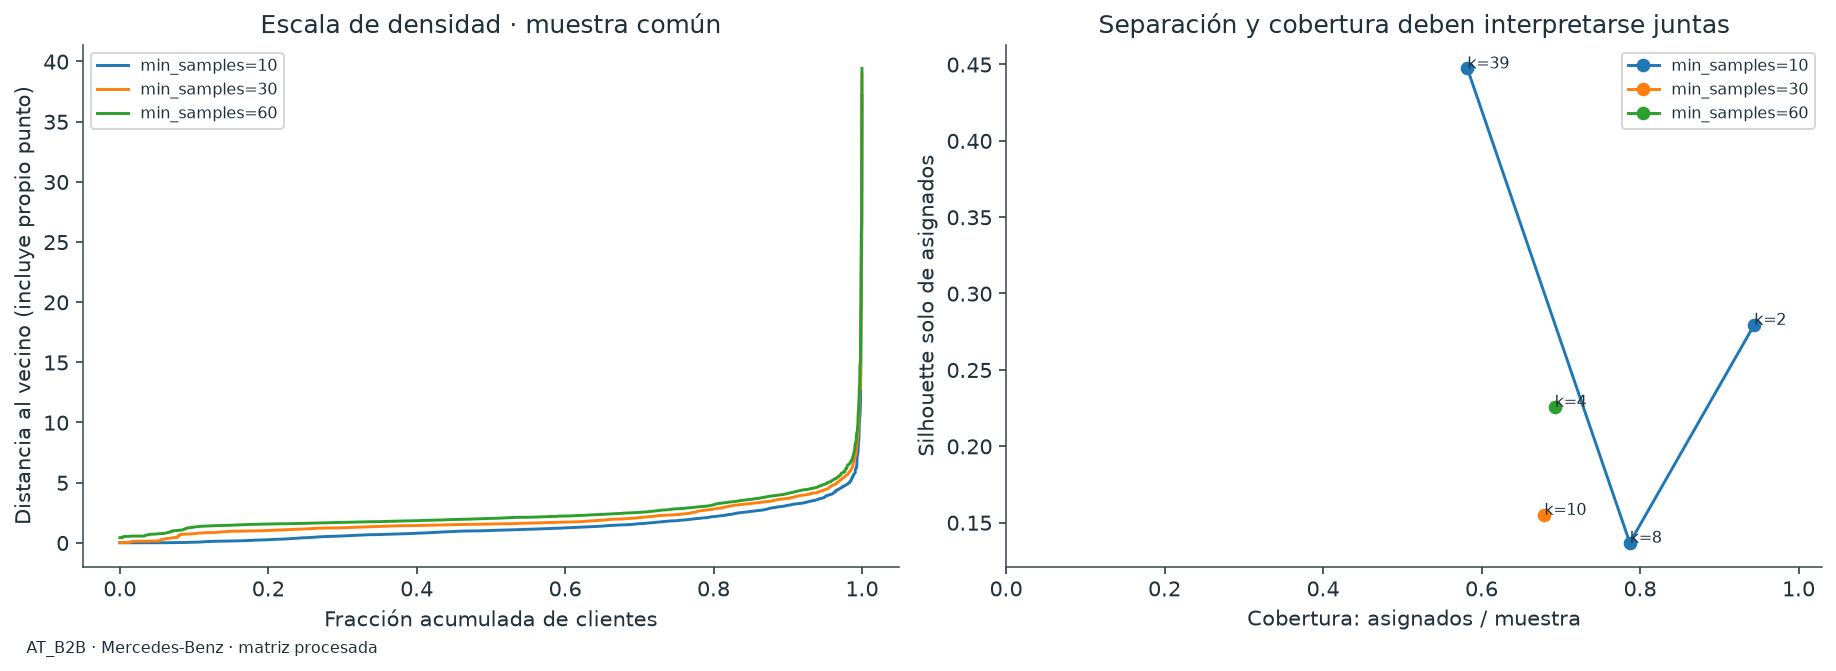

AT_B2C · barrido de densidad y cobertura


,min_samples,Cuantil del radio,eps,n_clusters,Cobertura,Fracción de ruido,Grupo menor (clientes),Clientes núcleo,Clientes de borde,Estado
0,10,0.50,2.0166,8,0.6840,0.3160,9,1500,552,ok
1,10,0.75,2.5457,1,0.8810,0.1190,2643,2250,393,one_cluster
2,10,0.90,3.1484,1,0.9553,0.0447,2866,2700,166,one_cluster
3,30,0.50,2.4512,1,0.7803,0.2197,2341,1500,841,one_cluster
4,30,0.75,2.9829,1,0.9203,0.0797,2761,2250,511,one_cluster
5,30,0.90,3.6217,1,0.9700,0.0300,2910,2700,210,one_cluster
6,60,0.50,2.7182,1,0.8193,0.1807,2458,1500,958,one_cluster
7,60,0.75,3.2758,1,0.9373,0.0627,2812,2250,562,one_cluster
8,60,0.90,3.9462,1,0.9747,0.0253,2924,2700,224,one_cluster


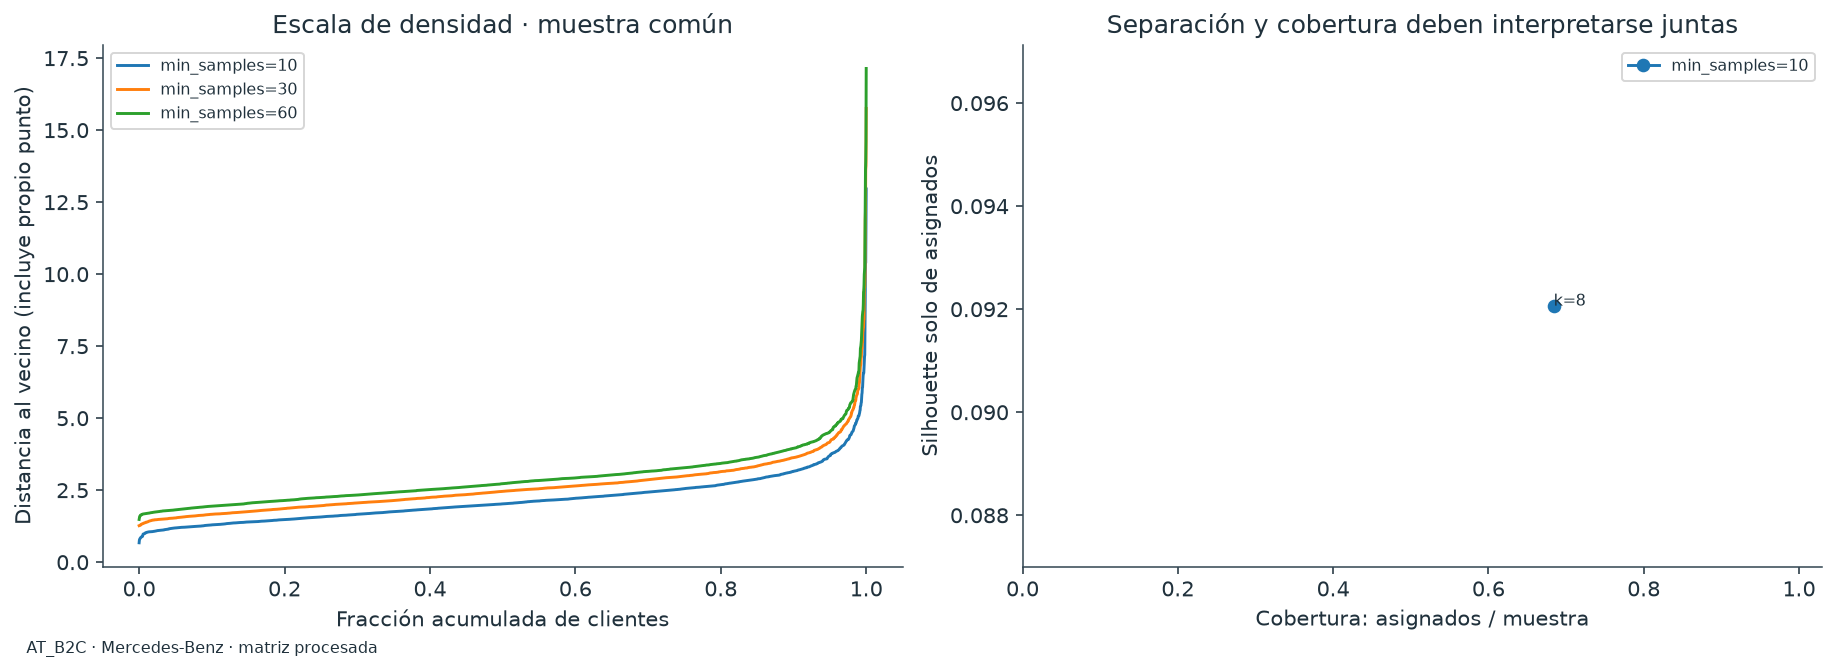

CH_B2B · barrido de densidad y cobertura


,min_samples,Cuantil del radio,eps,n_clusters,Cobertura,Fracción de ruido,Grupo menor (clientes),Clientes núcleo,Clientes de borde,Estado
0,10,0.50,1.2433,43,0.5959,0.4041,10,1499,288,ok
1,10,0.75,1.8622,7,0.8069,0.1931,10,2249,171,ok
2,10,0.90,3.2397,5,0.9376,0.0624,15,2699,113,ok
3,30,0.50,1.7741,6,0.6706,0.3294,35,1500,511,ok
4,30,0.75,2.3246,2,0.8153,0.1847,36,2249,196,ok
5,30,0.90,4.0286,1,0.9527,0.0473,2857,2699,158,one_cluster
6,60,0.50,2.1157,1,0.7583,0.2417,2274,1500,774,one_cluster
7,60,0.75,2.6610,1,0.8156,0.1844,2446,2251,195,one_cluster
8,60,0.90,4.4780,1,0.9547,0.0453,2863,2699,164,one_cluster


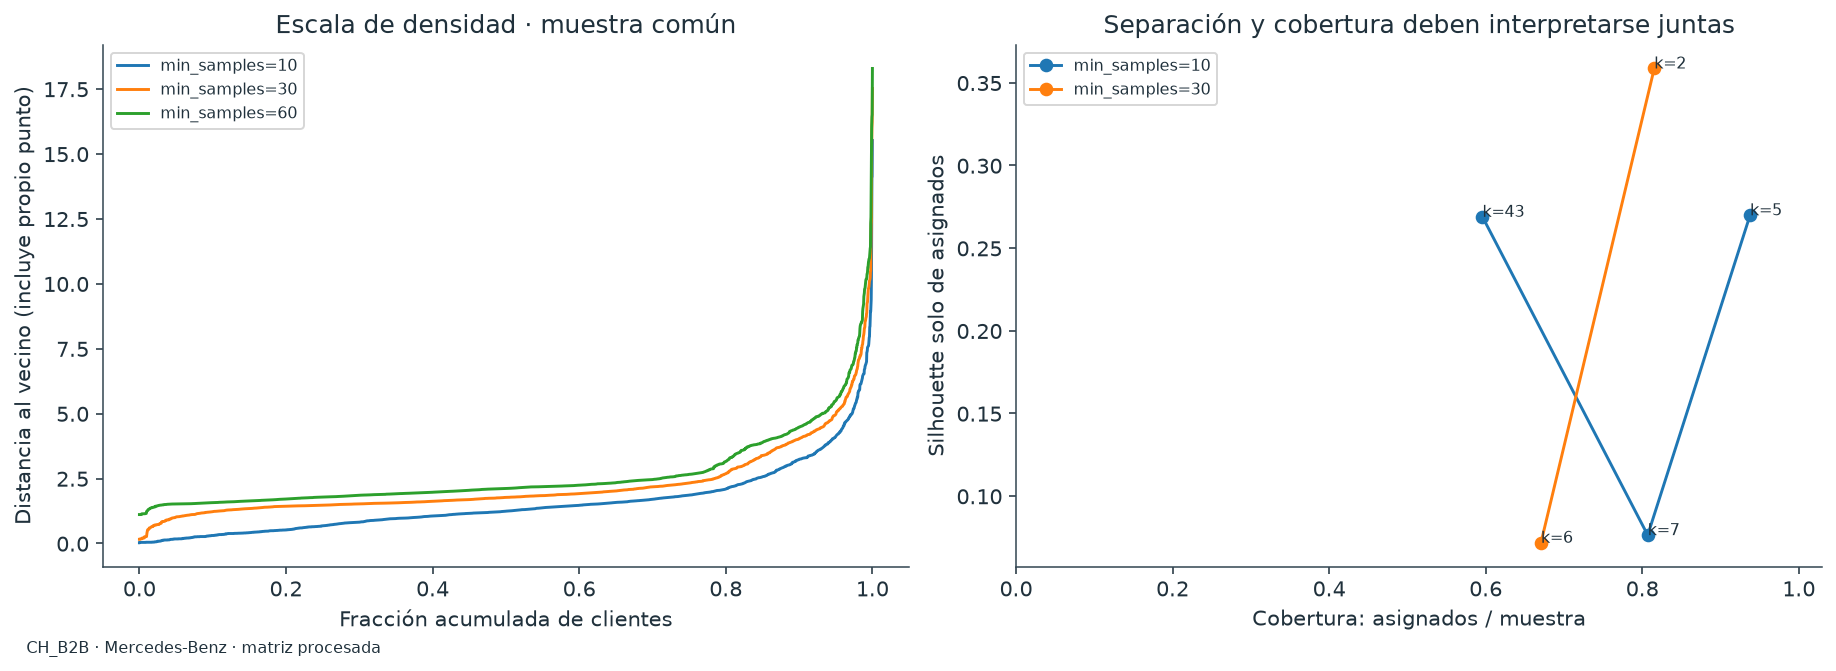

CH_B2C · barrido de densidad y cobertura


,min_samples,Cuantil del radio,eps,n_clusters,Cobertura,Fracción de ruido,Grupo menor (clientes),Clientes núcleo,Clientes de borde,Estado
0,10,0.50,2.0440,4,0.6813,0.3187,108,1500,544,ok
1,10,0.75,2.5559,2,0.8840,0.1160,10,2250,402,ok
2,10,0.90,3.1630,1,0.9617,0.0383,2885,2700,185,one_cluster
3,30,0.50,2.4669,1,0.7823,0.2177,2347,1500,847,one_cluster
4,30,0.75,2.9824,1,0.9160,0.0840,2748,2250,498,one_cluster
5,30,0.90,3.6772,1,0.9740,0.0260,2922,2700,222,one_cluster
6,60,0.50,2.7472,1,0.8343,0.1657,2503,1500,1003,one_cluster
7,60,0.75,3.2731,1,0.9340,0.0660,2802,2250,552,one_cluster
8,60,0.90,4.0334,1,0.9813,0.0187,2944,2700,244,one_cluster


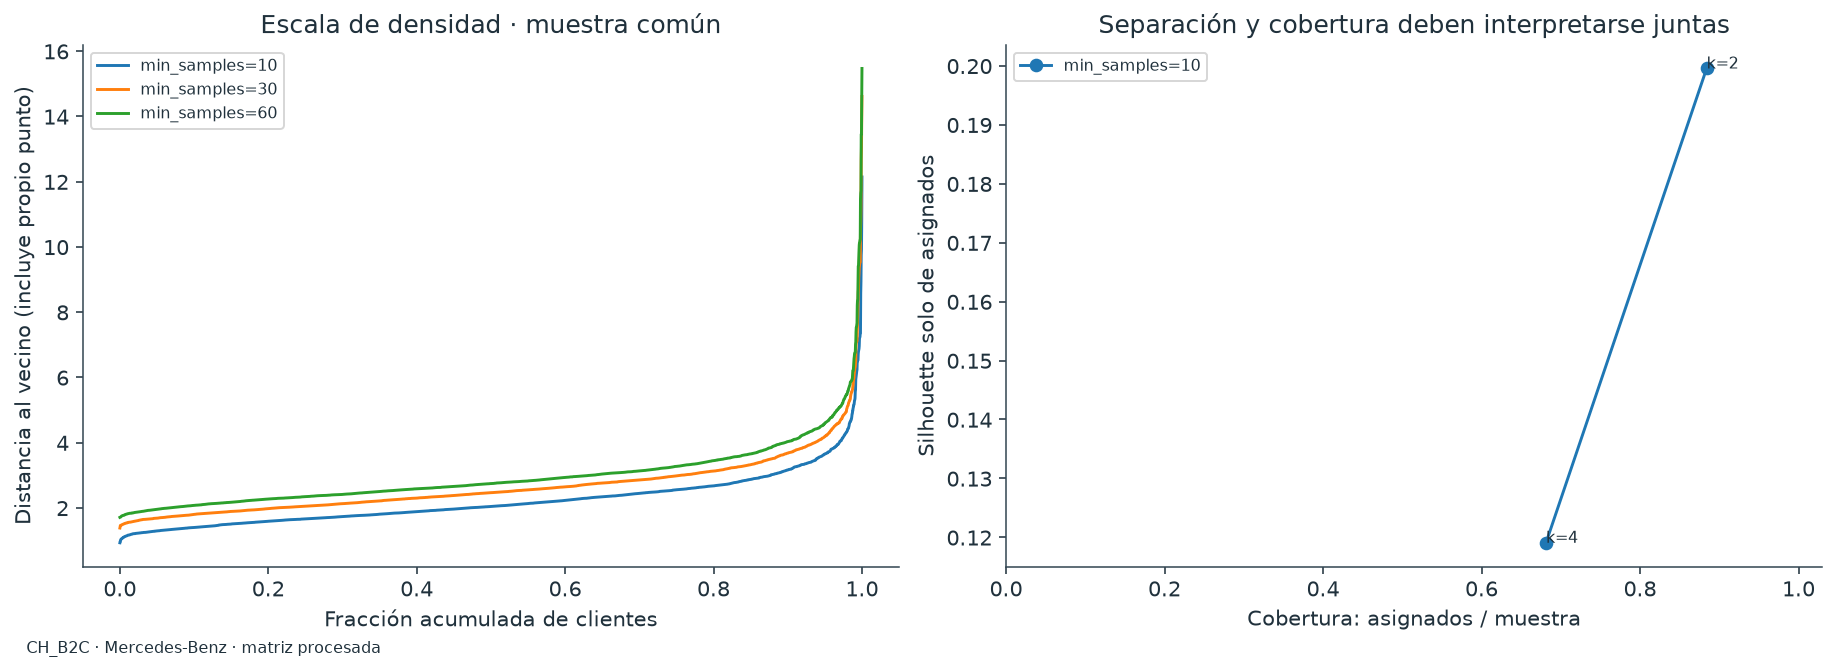

In [22]:
for segment, context in analyses.items():
    density = sweep_dbscan(context["hierarchy_data"],context["hierarchy"].labels["KMeans"],
        min_samples_values=DBSCAN_MIN_SAMPLES,eps_quantiles=DBSCAN_EPS_QUANTILES,
        random_state=SEED,silhouette_sample_size=SILHOUETTE_SAMPLE_SIZE)
    context["density"] = density
    display_table(density.table.reindex(columns=["min_samples","eps_quantile","eps","n_clusters",
        "coverage","noise_fraction","min_cluster_size","core_clients","border_clients","status"]),
        segment+" · barrido de densidad y cobertura",max_rows=30)
    plot_density_sweep(density)
    show_figures(segment)
    keep_table(segment,"barrido DBSCAN",density.table)


## DBSCAN: métricas condicionadas a cobertura

El ruido no se considera un cluster comercial. Silhouette, DB y CH se calculan solo en clientes asignados; K-Means se evalúa sobre esas mismas filas y la misma intersección de anclas. Las configuraciones con todo ruido o un único cluster no tienen índices de separación válidos. ARI sobre asignados mide acuerdo donde DBSCAN decide; ARI incluyendo −1 se muestra aparte y agrupa todo el ruido artificialmente. No comparar scores entre coberturas distintas como si fueran la misma tarea. Ninguna configuración sustituye automáticamente el modelo de referencia.


In [23]:
for segment, context in analyses.items():
    table = context["density"].table
    columns = ["min_samples","eps_quantile","coverage","n_clusters","assigned_silhouette",
        "kmeans_on_assigned_silhouette","assigned_davies_bouldin","assigned_calinski_harabasz",
        "ari_assigned","ari_including_noise","silhouette_n","status"]
    display_table(table.reindex(columns=columns),segment+" · separación sobre asignados, no sobre toda la muestra",max_rows=30)
    assignments = context["hierarchy_data"].assignments(context["hierarchy"].labels["KMeans"])
    for key, labels in context["density"].labels.items():
        assignments[f"DBSCAN_min{key[0]}_q{key[1]}"] = labels
    keep_table(segment,"DBSCAN con claves solo de la muestra común",assignments)
    context["entry"]["dbscan_study"] = dict(n_samples=len(assignments),seed=SEED,
        configurations=len(table),evaluable_multicluster=int(table["status"].eq("ok").sum()),
        population_predictions=False)


AT_B2B · separación sobre asignados, no sobre toda la muestra


,min_samples,Cuantil del radio,Cobertura,n_clusters,Silhouette de asignados,Silhouette K-Means en mismos clientes,DB de asignados,CH de asignados,ARI sobre asignados,ARI incluyendo ruido,Anclas de Silhouette,Estado
0,10,0.50,0.5821,39,0.4473,NaN,0.9264,340.8503,NaN,-0.0780,1161,ok
1,10,0.75,0.7871,8,0.1367,NaN,1.1820,152.8815,NaN,0.1148,1574,ok
2,10,0.90,0.9441,2,0.2795,0.3070,1.8457,218.7528,0.5269,0.6353,1887,ok
3,30,0.50,0.6792,10,0.1550,NaN,1.0150,200.0683,NaN,0.0067,1361,ok
4,30,0.75,0.8057,1,NaN,NaN,NaN,NaN,NaN,0.4969,1612,one_cluster
5,30,0.90,0.9603,1,NaN,0.3119,NaN,NaN,NaN,0.4607,1918,one_cluster
6,60,0.50,0.6923,4,0.2258,NaN,1.3383,280.5638,NaN,0.0520,1380,ok
7,60,0.75,0.8152,1,NaN,NaN,NaN,NaN,NaN,0.5275,1627,one_cluster
8,60,0.90,0.9683,1,NaN,0.3181,NaN,NaN,NaN,0.4208,1935,one_cluster


AT_B2C · separación sobre asignados, no sobre toda la muestra


,min_samples,Cuantil del radio,Cobertura,n_clusters,Silhouette de asignados,Silhouette K-Means en mismos clientes,DB de asignados,CH de asignados,ARI sobre asignados,ARI incluyendo ruido,Anclas de Silhouette,Estado
0,10,0.50,0.6840,8,0.0921,0.1428,1.7789,117.2813,0.3452,0.2219,1371,ok
1,10,0.75,0.8810,1,NaN,0.1337,NaN,NaN,NaN,0.0717,1768,one_cluster
2,10,0.90,0.9553,1,NaN,0.1287,NaN,NaN,NaN,0.0287,1916,one_cluster
3,30,0.50,0.7803,1,NaN,0.1328,NaN,NaN,NaN,0.1113,1560,one_cluster
4,30,0.75,0.9203,1,NaN,0.1301,NaN,NaN,NaN,0.0528,1852,one_cluster
5,30,0.90,0.9700,1,NaN,0.1270,NaN,NaN,NaN,0.0187,1941,one_cluster
6,60,0.50,0.8193,1,NaN,0.1287,NaN,NaN,NaN,0.1061,1646,one_cluster
7,60,0.75,0.9373,1,NaN,0.1300,NaN,NaN,NaN,0.0411,1885,one_cluster
8,60,0.90,0.9747,1,NaN,0.1253,NaN,NaN,NaN,0.0167,1954,one_cluster


CH_B2B · separación sobre asignados, no sobre toda la muestra


,min_samples,Cuantil del radio,Cobertura,n_clusters,Silhouette de asignados,Silhouette K-Means en mismos clientes,DB de asignados,CH de asignados,ARI sobre asignados,ARI incluyendo ruido,Anclas de Silhouette,Estado
0,10,0.50,0.5959,43,0.2689,NaN,0.9748,105.0929,NaN,-0.0424,1200,ok
1,10,0.75,0.8069,7,0.0764,NaN,1.0337,70.4220,NaN,0.1695,1620,ok
2,10,0.90,0.9376,5,0.2699,0.3752,1.4391,99.3243,0.171,0.4411,1871,ok
3,30,0.50,0.6706,6,0.0718,NaN,1.4210,120.2019,NaN,0.0255,1344,ok
4,30,0.75,0.8153,2,0.3587,NaN,0.7565,123.2966,NaN,0.2609,1639,ok
5,30,0.90,0.9527,1,NaN,0.3922,NaN,NaN,NaN,0.6494,1911,one_cluster
6,60,0.50,0.7583,1,NaN,NaN,NaN,NaN,NaN,0.1886,1534,one_cluster
7,60,0.75,0.8156,1,NaN,NaN,NaN,NaN,NaN,0.2839,1642,one_cluster
8,60,0.90,0.9547,1,NaN,0.3514,NaN,NaN,NaN,0.7716,1910,one_cluster


CH_B2C · separación sobre asignados, no sobre toda la muestra


,min_samples,Cuantil del radio,Cobertura,n_clusters,Silhouette de asignados,Silhouette K-Means en mismos clientes,DB de asignados,CH de asignados,ARI sobre asignados,ARI incluyendo ruido,Anclas de Silhouette,Estado
0,10,0.50,0.6813,4,0.1191,0.1309,2.2374,227.8648,0.2517,0.1484,1353,ok
1,10,0.75,0.8840,2,0.1996,0.1225,1.0941,17.9930,-0.0013,0.0275,1751,ok
2,10,0.90,0.9617,1,NaN,0.1184,NaN,NaN,NaN,0.0118,1918,one_cluster
3,30,0.50,0.7823,1,NaN,0.1185,NaN,NaN,NaN,0.0562,1549,one_cluster
4,30,0.75,0.9160,1,NaN,0.1200,NaN,NaN,NaN,0.0277,1819,one_cluster
5,30,0.90,0.9740,1,NaN,0.1172,NaN,NaN,NaN,0.0074,1942,one_cluster
6,60,0.50,0.8343,1,NaN,0.1174,NaN,NaN,NaN,0.0515,1648,one_cluster
7,60,0.75,0.9340,1,NaN,0.1174,NaN,NaN,NaN,0.0273,1858,one_cluster
8,60,0.90,0.9813,1,NaN,0.1156,NaN,NaN,NaN,0.0056,1961,one_cluster


## Sparse K-Means: pesos globales por variable

Se maximiza BCSS ponderada, w≥0, ||w||₂≤1, ||w||₁≤s, alternando K-Means sobre X·√w y soft-thresholding. El peso es global, no por cliente. Se incluye s=1 y √p para cubrir ambos extremos. La geometría ponderada es un experimento diferenciado; la optimización es local.


In [24]:
for segment, context in analyses.items():
    data = context["sweep_data"]
    values = sorted(set([1.,*np.clip(np.sqrt(data.n_features)*np.array([.35,.65,1.]),1.,np.sqrt(data.n_features))]))
    grid = sweep_sparse(data,[context["model"].n_clusters],values,seeds=(SEED,SEED+1),n_restarts=SPARSE_RESTARTS)
    context.update(sparse_grid=grid,s_values=values)
    display_table(grid.summary,segment+" · sensibilidad a la restricción de pesos")
    keep_table(segment,"barrido sparse",grid.runs)


AT_B2B · sensibilidad a la restricción de pesos


,k,Restricción s,original_silhouette,original_db,original_ch,weighted_silhouette,active_features_mean,ARI entre semillas ↑,weight_cosine_mean,successful_runs,requested_runs,all_converged
0,2,1.0000,0.3317,1.9124,321.8225,1.0000,1.0,1.0,1.0,2,2,True
1,2,1.3555,0.3317,1.9124,321.8225,0.8759,5.0,1.0,1.0,2,2,True
2,2,2.5174,0.3354,1.9110,331.1879,0.7756,15.0,1.0,1.0,2,2,True
3,2,3.8730,0.3354,1.9110,331.1879,0.7756,15.0,1.0,1.0,2,2,True


AT_B2C · sensibilidad a la restricción de pesos


,k,Restricción s,original_silhouette,original_db,original_ch,weighted_silhouette,active_features_mean,ARI entre semillas ↑,weight_cosine_mean,successful_runs,requested_runs,all_converged
0,6,1.0000,0.0191,6.9287,356.9800,0.7678,1.0,1.0,1.0,2,2,True
1,6,1.3555,0.0625,3.5858,627.5171,0.8452,2.0,1.0,1.0,2,2,True
2,6,2.5174,0.1211,2.0614,1637.6150,0.3848,9.0,1.0,1.0,2,2,True
3,6,3.8730,0.1215,2.0570,1648.9100,0.3328,15.0,1.0,1.0,2,2,True


CH_B2B · sensibilidad a la restricción de pesos


,k,Restricción s,original_silhouette,original_db,original_ch,weighted_silhouette,active_features_mean,ARI entre semillas ↑,weight_cosine_mean,successful_runs,requested_runs,all_converged
0,2,1.0000,0.4072,1.7563,403.1101,1.0000,1.0,1.0,1.0,2,2,True
1,2,1.3555,0.4072,1.7563,403.1101,0.9346,4.0,1.0,1.0,2,2,True
2,2,2.5174,0.5413,1.1654,459.5872,0.8671,15.0,1.0,1.0,2,2,True
3,2,3.8730,0.5413,1.1654,459.5872,0.8671,15.0,1.0,1.0,2,2,True


CH_B2C · sensibilidad a la restricción de pesos


,k,Restricción s,original_silhouette,original_db,original_ch,weighted_silhouette,active_features_mean,ARI entre semillas ↑,weight_cosine_mean,successful_runs,requested_runs,all_converged
0,5,1.0000,0.0262,4.8231,448.1909,0.7937,1.0,1.0000,1.000,2,2,True
1,5,1.3555,0.0504,4.0012,959.3813,0.7939,2.0,1.0000,1.000,2,2,True
2,5,2.5174,0.1135,2.2499,1620.3479,0.3840,15.0,0.3483,0.808,2,2,True
3,5,3.8730,0.1135,2.2499,1620.3479,0.3840,15.0,0.3483,0.808,2,2,True


## Propuesta de sparsidad por permutaciones

Gap(s)=log BCSS(s)−media log BCSS nula(s). Se permutan columnas de forma independiente, conservando marginales; las mismas permutaciones sirven para cada s. Se propone el menor s dentro de una dispersión nula ajustada del máximo. Cinco permutaciones limitan la precisión; ni esa dispersión ni el SE Monte Carlo son un IC del modelo.


In [25]:
for segment, context in analyses.items():
    gap = sparse_gap_curve(context["sweep_data"],context["model"].n_clusters,context["s_values"],
        n_permutations=N_PERMUTATIONS,random_state=SEED,n_restarts=2)
    value = float(gap.loc[gap["suggested"],"l1_bound"].iloc[0])
    key = (context["model"].n_clusters,value,SEED)
    if key not in context["sparse_grid"].models:
        raise ValueError("La propuesta no tiene ajuste sparse válido; revisar fallos del barrido.")
    context["sparse_model"] = context["sparse_grid"].models[key]
    context["chosen_s"] = value
    display_table(gap,segment+" · gap y precisión Monte Carlo")


AT_B2B · gap y precisión Monte Carlo


,k,Restricción s,gap,mc_se,gap_spread,n_permutations,Estado,warning,suggested
0,2,1.0000,0.0000,0.0,0.0,5,ok,,False
1,2,1.3555,0.0418,0.0,0.0,5,ok,,False
2,2,2.5174,0.0471,0.0,0.0,5,ok,,True
3,2,3.8730,0.0471,0.0,0.0,5,ok,,False


C:\Users\josem\Documents\TRABAJOS\Malackathon 2026\.venv-ml\Lib\site-packages\sklearn\base.py:1389: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (6). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
AT_B2C · gap y precisión Monte Carlo


,k,Restricción s,gap,mc_se,gap_spread,n_permutations,Estado,warning,suggested
0,6,1.0000,NaN,NaN,NaN,5,fit_failed,La ponderación colapsa clusters; revisar k/s o filas distintas activas.,False
1,6,1.3555,-0.0138,0.0037,0.0091,5,ok,,False
2,6,2.5174,0.0514,0.0034,0.0084,5,ok,,True
3,6,3.8730,0.0532,0.0034,0.0084,5,ok,,False


CH_B2B · gap y precisión Monte Carlo


,k,Restricción s,gap,mc_se,gap_spread,n_permutations,Estado,warning,suggested
0,2,1.0000,0.0000,0.0,0.0,5,ok,,False
1,2,1.3555,0.0590,0.0,0.0,5,ok,,True
2,2,2.5174,0.0423,0.0,0.0,5,ok,,False
3,2,3.8730,0.0423,0.0,0.0,5,ok,,False


C:\Users\josem\Documents\TRABAJOS\Malackathon 2026\.venv-ml\Lib\site-packages\sklearn\base.py:1389: ConvergenceWarning: Number of distinct clusters (3) found smaller than n_clusters (5). Possibly due to duplicate points in X.
  return fit_method(estimator, *args, **kwargs)
CH_B2C · gap y precisión Monte Carlo


,k,Restricción s,gap,mc_se,gap_spread,n_permutations,Estado,warning,suggested
0,5,1.0000,NaN,NaN,NaN,5,fit_failed,La ponderación colapsa clusters; revisar k/s o filas distintas activas.,False
1,5,1.3555,0.0036,0.0072,0.0176,5,ok,,False
2,5,2.5174,0.0459,0.0022,0.0054,5,ok,,True
3,5,3.8730,0.0459,0.0022,0.0054,5,ok,,False


## Evaluar la partición ponderada sobre toda la población

La partición sparse se aprende en la muestra de hasta 20.000 filas anterior y se aplica después a toda X. Esta tabla evalúa las tres particiones en X de modelado completa y con las mismas filas de Silhouette, pero declara sus distintos tamaños de ajuste; no sustituye la comparación principal. Un cambio de pesos no implica una mejor campaña. Si el límite L1 queda holgado, no se ha forzado selección de variables; se muestra concentración del peso y variables activas.


AT_B2B · concentración de pesos


,Feature,Peso,distance_weight_share
2,is_current_vehicle,0.9469,0.5697
10,has_telemetry_active,0.2212,0.1331
6,workshop_visits_warranty_goodwill,0.1740,0.1047
14,operating_hours_total,0.1211,0.0729
5,workshop_frequency_yearly,0.0786,0.0473


AT_B2B · evaluación en X de modelado completa; tamaños de ajuste indicados


,Algoritmo,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,WCSS en X original ↓,Clientes de ajuste
0,KMeans,0.4210,1.7345,369.9884,32986.8457,2522
1,GMM,0.3027,2.3039,327.3069,33481.3227,2522
2,Sparse KMeans,0.3354,1.9110,331.1879,33435.7481,2522


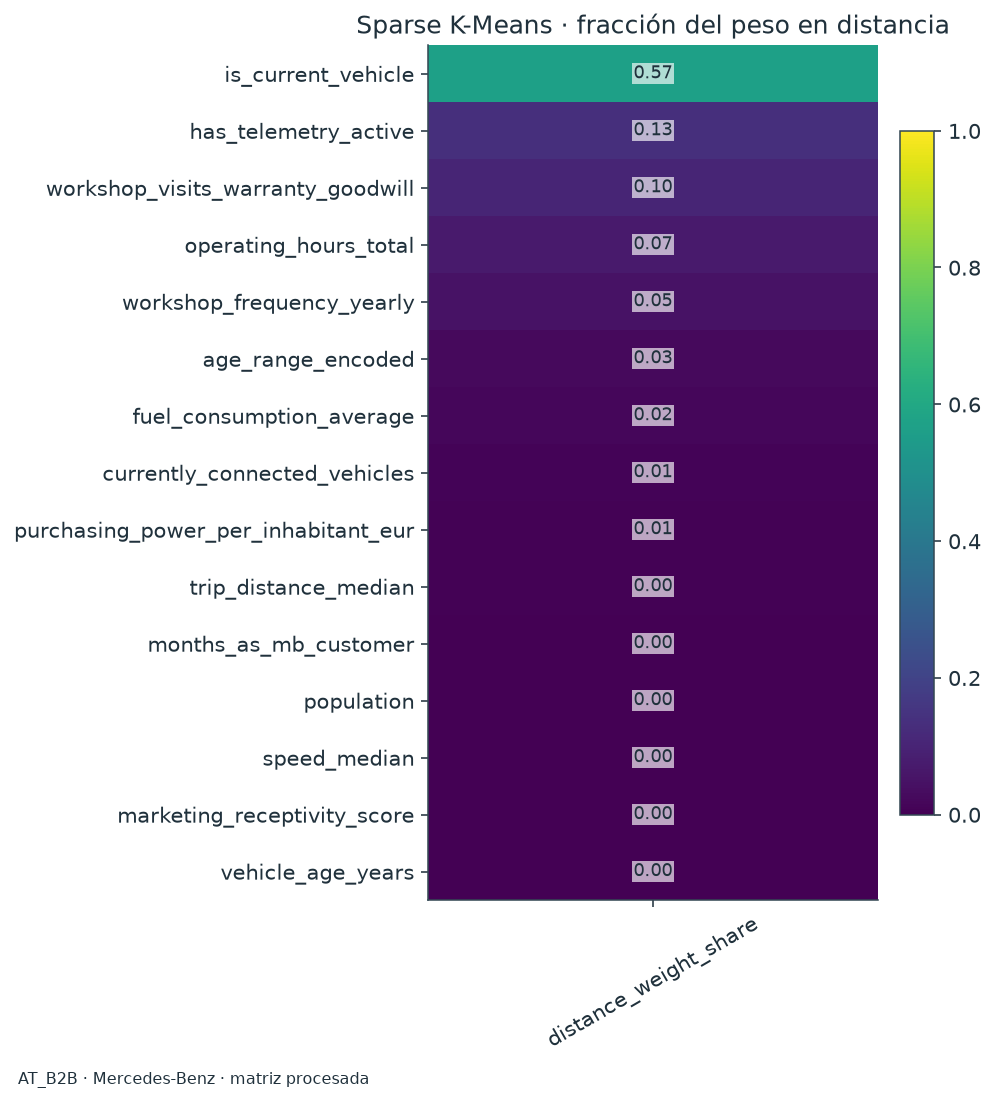

AT_B2C · concentración de pesos


,Feature,Peso,distance_weight_share
4,currently_connected_vehicles,0.5101,0.2026
7,marketing_receptivity_score,0.4810,0.1911
9,population,0.4085,0.1623
2,is_current_vehicle,0.3951,0.1569
6,workshop_visits_warranty_goodwill,0.3151,0.1251


AT_B2C · evaluación en X de modelado completa; tamaños de ajuste indicados


,Algoritmo,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,WCSS en X original ↓,Clientes de ajuste
0,KMeans,0.1216,2.0397,9090.1902,1.132626e+06,107450
1,GMM,0.0414,3.3640,4479.3618,1.333732e+06,107450
2,Sparse KMeans,0.1210,2.0669,8777.8074,1.144316e+06,20000


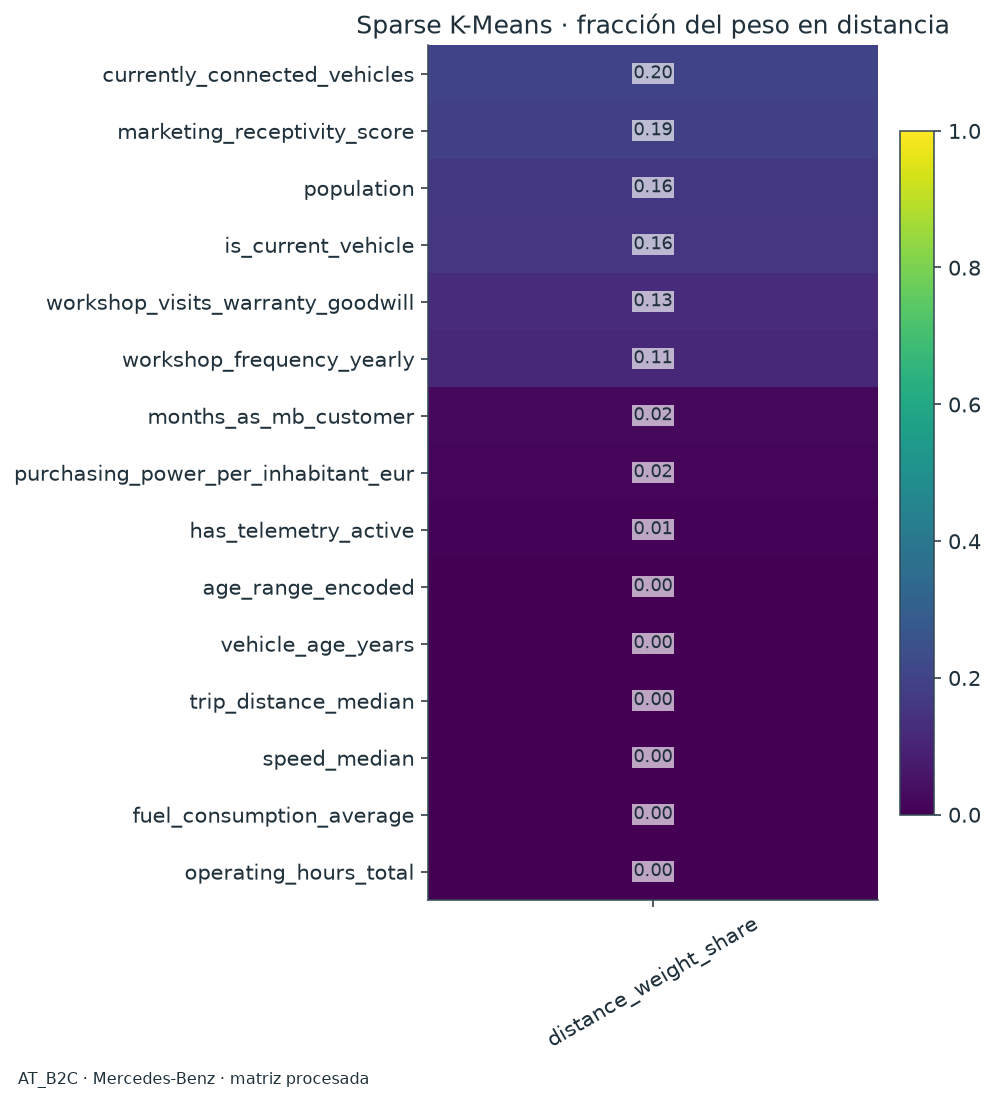

CH_B2B · concentración de pesos


,Feature,Peso,distance_weight_share
2,is_current_vehicle,0.9754,0.7196
10,has_telemetry_active,0.1377,0.1016
6,workshop_visits_warranty_goodwill,0.1328,0.0980
5,workshop_frequency_yearly,0.1096,0.0809
1,vehicle_age_years,0.0000,0.0000


CH_B2B · evaluación en X de modelado completa; tamaños de ajuste indicados


,Algoritmo,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,WCSS en X original ↓,Clientes de ajuste
0,KMeans,0.5199,1.3472,485.9633,38708.4308,2999
1,GMM,0.3850,2.1983,404.1809,39639.1870,2999
2,Sparse KMeans,0.4072,1.7563,403.1101,39651.6698,2999


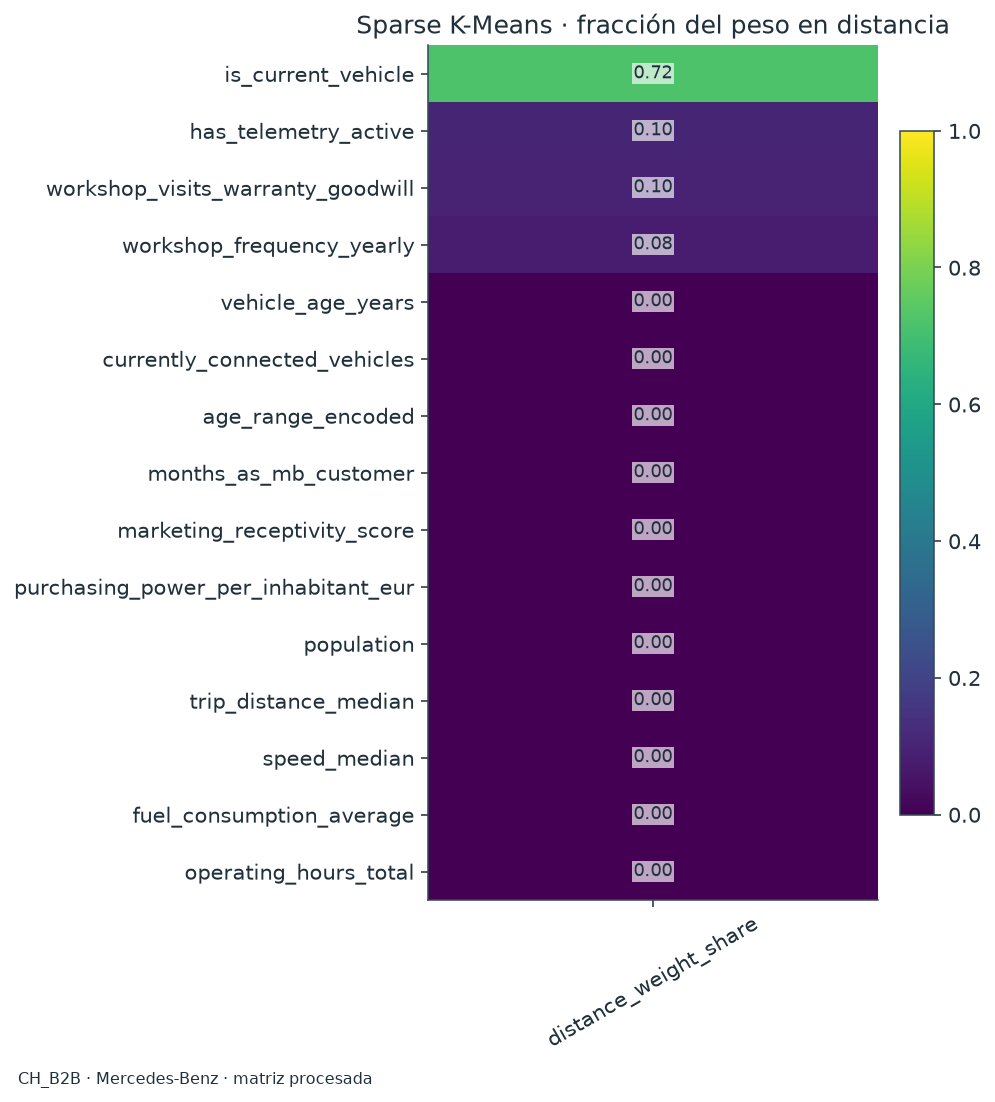

CH_B2C · concentración de pesos


,Feature,Peso,distance_weight_share
4,currently_connected_vehicles,0.5458,0.2298
7,marketing_receptivity_score,0.5111,0.2152
2,is_current_vehicle,0.4885,0.2057
6,workshop_visits_warranty_goodwill,0.3173,0.1336
5,workshop_frequency_yearly,0.3000,0.1263


CH_B2C · evaluación en X de modelado completa; tamaños de ajuste indicados


,Algoritmo,Silhouette ↑,Davies–Bouldin ↓,Calinski–Harabasz ↑,WCSS en X original ↓,Clientes de ajuste
0,KMeans,0.1140,2.1976,16019.2263,2.129531e+06,189879
1,GMM,0.0535,3.7183,8734.8753,2.405533e+06,189879
2,Sparse KMeans,0.1143,2.2475,15384.1142,2.151049e+06,20000


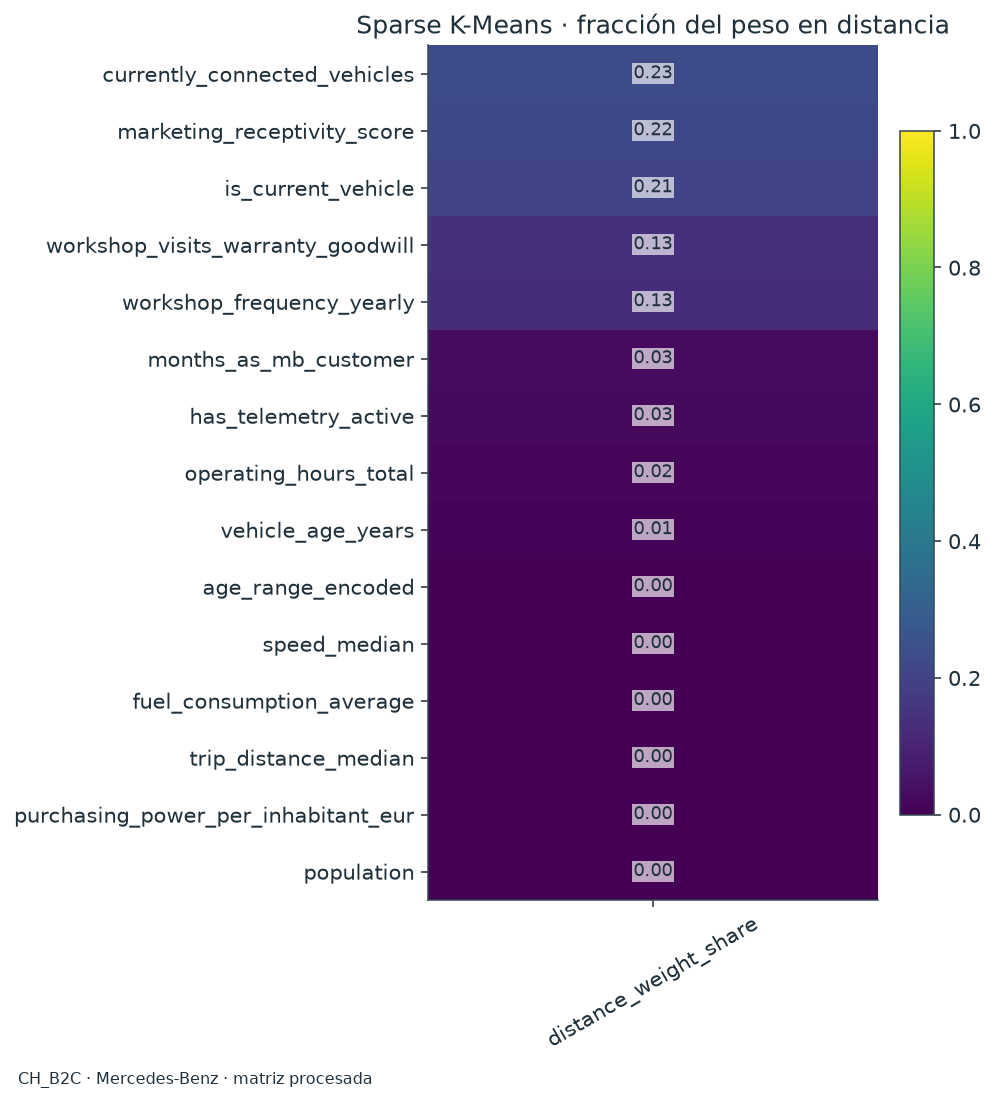

In [26]:
for segment, context in analyses.items():
    data, sparse_model = context["data"],context["sparse_model"]
    sparse_labels = sparse_model.predict(data.X)
    scores = partition_scores(data.X,sparse_labels,sample_size=SILHOUETTE_SAMPLE_SIZE,random_state=SEED)
    weights = pd.DataFrame({"feature":data.feature_names,"weight":sparse_model.weights_,
        "distance_weight_share":sparse_model.weights_/sparse_model.weights_.sum()}).sort_values("weight",ascending=False)
    display_table(weights.head(5),segment+" · concentración de pesos")
    context["sparse_ari"] = float(adjusted_rand_score(context["labels"],sparse_labels))
    context["sparse_weights"] = weights
    context["sparse_scores"] = scores
    keep_table(segment,"pesos sparse",weights)
    table = context["comparison"].table[["algorithm","silhouette","davies_bouldin","calinski_harabasz","within_ss"]].copy()
    table["fit_clients"] = data.n_samples
    row = {"algorithm":"Sparse KMeans",**{name:scores[name] for name in
        ("silhouette","davies_bouldin","calinski_harabasz","within_ss")},
        "fit_clients":context["sweep_data"].n_samples}
    table = pd.concat([table,pd.DataFrame([row])],ignore_index=True)
    display_table(table,segment+" · evaluación en X de modelado completa; tamaños de ajuste indicados")
    keep_table(segment,"evaluación de particiones en X completa",table)
    plot_heatmap(weights.set_index("feature")[["distance_weight_share"]],
        "Sparse K-Means · fracción del peso en distancia",vmin=0,vmax=1)
    show_figures(segment)


## Consecuencia para la segmentación de marketing

Un algoritmo se valora por geometría, continuidad de audiencias, estabilidad y utilidad del perfil. Un Silhouette mayor no demuestra más conversión. Los clientes con desacuerdo o pertenencia ambigua se conservan para revisión en 07, sin sustituir automáticamente la referencia.


In [27]:
for segment, context in analyses.items():
    comparison,memberships = context["comparison"],context["memberships"]
    ari = float(comparison.ari.loc["KMeans","GMM"])
    context["findings"] = [f"ARI={ari:.3f}; cambian {(context['aligned_gmm']!=context['labels']).mean():.1%} de asignaciones alineadas.",
        f"La retención mínima de una lista es {context['overlap']['retained_fraction'].min():.1%}; una campaña basada solo en su etiqueta sería sensible a la elección del algoritmo.",
        f"{int(memberships['ambiguous_posterior'].sum())} clientes activan la alerta posterior y {int(memberships['low_density'].sum())} la señal de baja densidad; no son la misma condición.",
        f"En la muestra común de {context['hierarchy_data'].n_samples:,} filas, Ward frente a K-Means alcanza ARI={context['hierarchy_ward_ari']:.3f}; no se ha etiquetado el resto con Ward.",
        "Control de tamaños en el experimento común: "+context["hierarchy_small_groups"],
        f"DBSCAN: {context['density'].table['status'].eq('ok').sum()}/{len(context['density'].table)} configuraciones multicluster evaluables; interpretar cada score junto a su cobertura y ruido.",
        f"Sparse sobre X completa: s={context['chosen_s']:.3g}, ARI={context['sparse_ari']:.3f}, {(context['sparse_model'].weights_>1e-8).sum()} variables activas. Pesos globales, no preferencias individuales.",
        "Las variables discretas y covarianzas pequeñas pueden concentrar los posteriores. Una p alta no valida la segmentación comercial.",
        "Mantener la referencia para una comparación trazable; resolver desacuerdos con perfiles y robustez antes de definir el piloto."]
    arrays=context["entry"]["arrays"]
    arrays["gmm_disagreement"] = memberships["model_disagreement"].to_numpy()
    arrays["gmm_ambiguous"] = memberships["ambiguous_posterior"].to_numpy()
    arrays["gmm_low_density"] = memberships["low_density"].to_numpy()
    context["entry"]["steps"] = sorted(set(context["entry"]["steps"]+["05"]))
    display(ReportPanel(segment+" · elección del algoritmo",{},context["findings"],"Comparación descriptiva, sin ganador comercial demostrado"))


# AT_B2B · elección del algoritmo

Comparación descriptiva, sin ganador comercial demostrado

| Indicador | Resultado |
| --- | --- |

- ARI=0.531; cambian 9.4% de asignaciones alineadas.
- La retención mínima de una lista es 89.6%; una campaña basada solo en su etiqueta sería sensible a la elección del algoritmo.
- 0 clientes activan la alerta posterior y 127 la señal de baja densidad; no son la misma condición.
- En la muestra común de 2,522 filas, Ward frente a K-Means alcanza ARI=0.189; no se ha etiquetado el resto con Ward.
- Control de tamaños en el experimento común: Agg average: grupo menor 1 (0.04%); Agg complete: grupo menor 3 (0.12%)
- DBSCAN: 5/9 configuraciones multicluster evaluables; interpretar cada score junto a su cobertura y ruido.
- Sparse sobre X completa: s=2.52, ARI=0.690, 15 variables activas. Pesos globales, no preferencias individuales.
- Las variables discretas y covarianzas pequeñas pueden concentrar los posteriores. Una p alta no valida la segmentación comercial.
- Mantener la referencia para una comparación trazable; resolver desacuerdos con perfiles y robustez antes de definir el piloto.

# AT_B2C · elección del algoritmo

Comparación descriptiva, sin ganador comercial demostrado

| Indicador | Resultado |
| --- | --- |

- ARI=0.191; cambian 53.8% de asignaciones alineadas.
- La retención mínima de una lista es 2.6%; una campaña basada solo en su etiqueta sería sensible a la elección del algoritmo.
- 3165 clientes activan la alerta posterior y 5373 la señal de baja densidad; no son la misma condición.
- En la muestra común de 3,000 filas, Ward frente a K-Means alcanza ARI=0.393; no se ha etiquetado el resto con Ward.
- Control de tamaños en el experimento común: Agg average: grupo menor 1 (0.03%); Agg complete: grupo menor 2 (0.07%)
- DBSCAN: 1/9 configuraciones multicluster evaluables; interpretar cada score junto a su cobertura y ruido.
- Sparse sobre X completa: s=2.52, ARI=0.832, 9 variables activas. Pesos globales, no preferencias individuales.
- Las variables discretas y covarianzas pequeñas pueden concentrar los posteriores. Una p alta no valida la segmentación comercial.
- Mantener la referencia para una comparación trazable; resolver desacuerdos con perfiles y robustez antes de definir el piloto.

# CH_B2B · elección del algoritmo

Comparación descriptiva, sin ganador comercial demostrado

| Indicador | Resultado |
| --- | --- |

- ARI=0.423; cambian 8.7% de asignaciones alineadas.
- La retención mínima de una lista es 90.9%; una campaña basada solo en su etiqueta sería sensible a la elección del algoritmo.
- 0 clientes activan la alerta posterior y 150 la señal de baja densidad; no son la misma condición.
- En la muestra común de 2,999 filas, Ward frente a K-Means alcanza ARI=0.682; no se ha etiquetado el resto con Ward.
- Control de tamaños en el experimento común: Agg average: grupo menor 1 (0.03%); Agg complete: grupo menor 4 (0.13%)
- DBSCAN: 5/9 configuraciones multicluster evaluables; interpretar cada score junto a su cobertura y ruido.
- Sparse sobre X completa: s=1.36, ARI=0.540, 4 variables activas. Pesos globales, no preferencias individuales.
- Las variables discretas y covarianzas pequeñas pueden concentrar los posteriores. Una p alta no valida la segmentación comercial.
- Mantener la referencia para una comparación trazable; resolver desacuerdos con perfiles y robustez antes de definir el piloto.

# CH_B2C · elección del algoritmo

Comparación descriptiva, sin ganador comercial demostrado

| Indicador | Resultado |
| --- | --- |

- ARI=0.246; cambian 50.0% de asignaciones alineadas.
- La retención mínima de una lista es 21.9%; una campaña basada solo en su etiqueta sería sensible a la elección del algoritmo.
- 1021 clientes activan la alerta posterior y 9494 la señal de baja densidad; no son la misma condición.
- En la muestra común de 3,000 filas, Ward frente a K-Means alcanza ARI=0.284; no se ha etiquetado el resto con Ward.
- Control de tamaños en el experimento común: Agg average: grupo menor 1 (0.03%); Agg complete: grupo menor 1 (0.03%)
- DBSCAN: 2/9 configuraciones multicluster evaluables; interpretar cada score junto a su cobertura y ruido.
- Sparse sobre X completa: s=2.52, ARI=0.734, 15 variables activas. Pesos globales, no preferencias individuales.
- Las variables discretas y covarianzas pequeñas pueden concentrar los posteriores. Una p alta no valida la segmentación comercial.
- Mantener la referencia para una comparación trazable; resolver desacuerdos con perfiles y robustez antes de definir el piloto.

## Alcance y siguiente decisión

La variación entre algoritmos condiciona la definición de destinatarios. PCA analizará qué ejes sostienen la separación y 07 probará si las asignaciones resisten cambios de datos. [Evaluación de clustering](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation). [Clustering jerárquico](https://scikit-learn.org/stable/modules/clustering.html#hierarchical-clustering). [DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html). [Sparse clustering: Witten y Tibshirani](https://pmc.ncbi.nlm.nih.gov/articles/PMC2930825/).


In [28]:
# El paquete conserva los resultados previos; cada cuaderno añade solo su aportación.
save_study(study, REFERENCE_FILE)
RUN_REPORT = dict(step="05", source="real", versions=VERSIONS,
    segments=[dict(segment_id=segment, clients=context["data"].n_samples,
                   features=context["data"].n_features, k=int(context["model"].n_clusters),
                   scaling_policy=context["representation"]["policy"])
              for segment, context in analyses.items()],
    findings={segment:context["findings"] for segment,context in analyses.items()},
    elapsed_seconds=round(perf_counter()-STARTED,3))
print("Resultados actualizados en " + REFERENCE_FILE + ". Para continuar en otra sesión, conservar este paquete junto a los CSV.")


Resultados actualizados en segmentacion_ml.zip. Para continuar en otra sesión, conservar este paquete junto a los CSV.
